## **1. Đọc data frame**

In [ ]:
# Import file dữ liệu excel đã tạo, chuyển thành file csv
!pip install openpyxl
import pandas as pd
from google.colab import files
import io
from scipy.stats.mstats import winsorize
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
#!pip install --upgrade seaborn matplotlib
#!conda update seaborn matplotlib

In [ ]:
uploaded = files.upload()
file_name = next(iter(uploaded)) # Lấy tên file đã upload

Saving Stocks_MultiSheet_(1_1_2015 to 1_10_2025).xlsx to Stocks_MultiSheet_(1_1_2015 to 1_10_2025) (2).xlsx


In [ ]:
# Đọc tất cả các sheets. Kết quả là một dictionary {tên_sheet: DataFrame}
# Nếu bạn dùng files.upload() (byte data), hãy dùng io.BytesIO(uploaded[file_name])
# Nếu bạn dùng Google Drive (đường dẫn), hãy dùng file_name
try:
    if 'uploaded' in locals() or 'uploaded' in globals(): # Kiểm tra xem đã upload file chưa
        xls_dict = pd.read_excel(io.BytesIO(uploaded[file_name]), sheet_name=None)
    else:
        xls_dict = pd.read_excel(file_name, sheet_name=None)
except Exception as e:
    print(f"Lỗi khi đọc file Excel: {e}")
    # Xử lý trường hợp không tìm thấy file nếu dùng Google Drive
    # hoặc file_name không đúng nếu dùng files.upload()
    exit()

# Lặp qua dictionary và lưu từng DataFrame thành file CSV
for sheet_name, df in xls_dict.items():
    # Tên file CSV sẽ là tên sheet (mã cổ phiếu)
    csv_file_name = f'{sheet_name}.csv'

    # Sử dụng .to_csv để xuất DataFrame thành file CSV
    # index=False để không bao gồm chỉ mục (index) của DataFrame vào file CSV
    df.to_csv(csv_file_name, index=False, encoding='utf-8')


In [ ]:
import pandas as pd
import glob
import numpy as np

# Đọc tất cả file CSV trong thư mục hiện tại
csv_files = glob.glob("*.csv")

# Tạo 1 dictionary để lưu các mã cổ phiếu với key là tên mã cổ phiếu
dataframes = {}

for file in csv_files:
    # Lấy tên mã cổ phiếu từ tên file (VD: GOOG.csv -> GOOG)
    ticker = file.split(".")[0]

    # Đọc file, bỏ 3 hàng đầu (Price, Ticker, header trống)
    df = pd.read_csv(file, skiprows=3, header=None)

    # Tự đặt lại header chuẩn
    df.columns = ['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']
    df['Close'] = pd.to_numeric(df['Close'], errors='coerce')

    # Lưu lại vào dict
    dataframes[ticker] = df

for ticker, df in dataframes.items():
  df['Closelog'] = np.log(df.Close)

# In để kiểm tra
print(dataframes["GOOG"].head())

                  Date       Open       High        Low      Close  Adj Close  \
0  2015-01-02 00:00:00  26.378078  26.490770  26.133251  26.168653  25.990791   
1  2015-01-05 00:00:00  26.091366  26.144720  25.582764  25.623152  25.448997   
2  2015-01-06 00:00:00  25.679497  25.738087  24.983908  25.029282  24.859163   
3  2015-01-07 00:00:00  25.280592  25.292759  24.914099  24.986401  24.816574   
4  2015-01-08 00:00:00  24.831326  25.105074  24.482782  25.065184  24.894823   

     Volume  Closelog  
0  28951268  3.264562  
1  41196796  3.243496  
2  57998800  3.220046  
3  41301082  3.218332  
4  67071641  3.221480  


## **2. Detect Missing Value**

In [ ]:
import pandas as pd
# Xử lí missing data

def miss_var_summary(data):
    # Đếm số dữ liệu thiếu và tính phần trăm cho mỗi cột
    missing_data = data.isnull().sum()
    missing_percentage = (missing_data / len(data)) * 100

    # Tạo 1 dataframe để biểu diễn tóm tắt
    summary_df = pd.DataFrame({
        'variable': data.columns,
        'n_missing': missing_data,
        'pct_missing': missing_percentage
    })

    # Sắp xếp bảng tóm tắt bằng số dữ liệu thiếu theo thứ tự giảm dần
    summary_df = summary_df.sort_values(by='n_missing', ascending=False)
    # Trả về dataframe đã tóm tắt
    return summary_df

count = 0
for ticker, df in dataframes.items():
  if ticker == 'Summary': continue

  if df.isnull().sum().sum() != 0:
    print(f"=== {ticker} ===")
    miss_var_summary(df)
  else:
    count = count + 1

num_duplicates_all_cols = df.duplicated().sum()

if num_duplicates_all_cols > 0:
  print(f"Phát hiện {num_duplicates_all_cols} hàng trùng lặp hoàn toàn.")
  df.drop_duplicates(inplace=True)
  print("Đã loại bỏ các hàng trùng lặp hoàn toàn.")
if count == 66:
  print("MultiStock sạch. Dữ liệu hoàn chỉnh và đầy đủ")

MultiStock sạch. Dữ liệu hoàn chỉnh và đầy đủ


#### **2.1. Nhận xét về missing data**: Từ kết quả, ta nhận thấy không tồn tại dữ liệu khuyết → Bộ dữ liệu đầy đủ và hoàn chỉnh, không cần xử lý thiếu dữ liệu.


## **3. Outliers in Raw Data Market**

Dùng chính dataframe đã tạo ban nãy (raw data market) để xử lí outlier.

### **3.1. Boxplot, IQR**

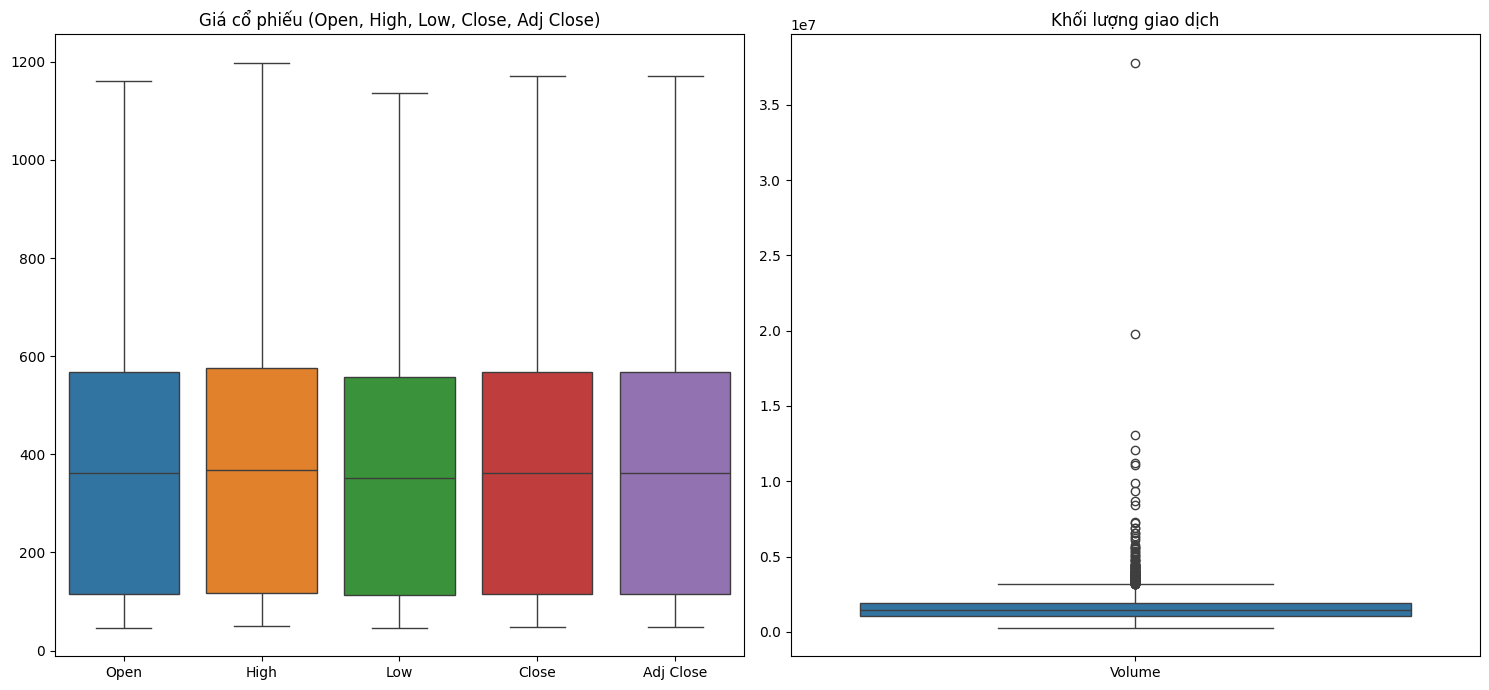


===== Outliers của mã NOW =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          138          2702        5.11


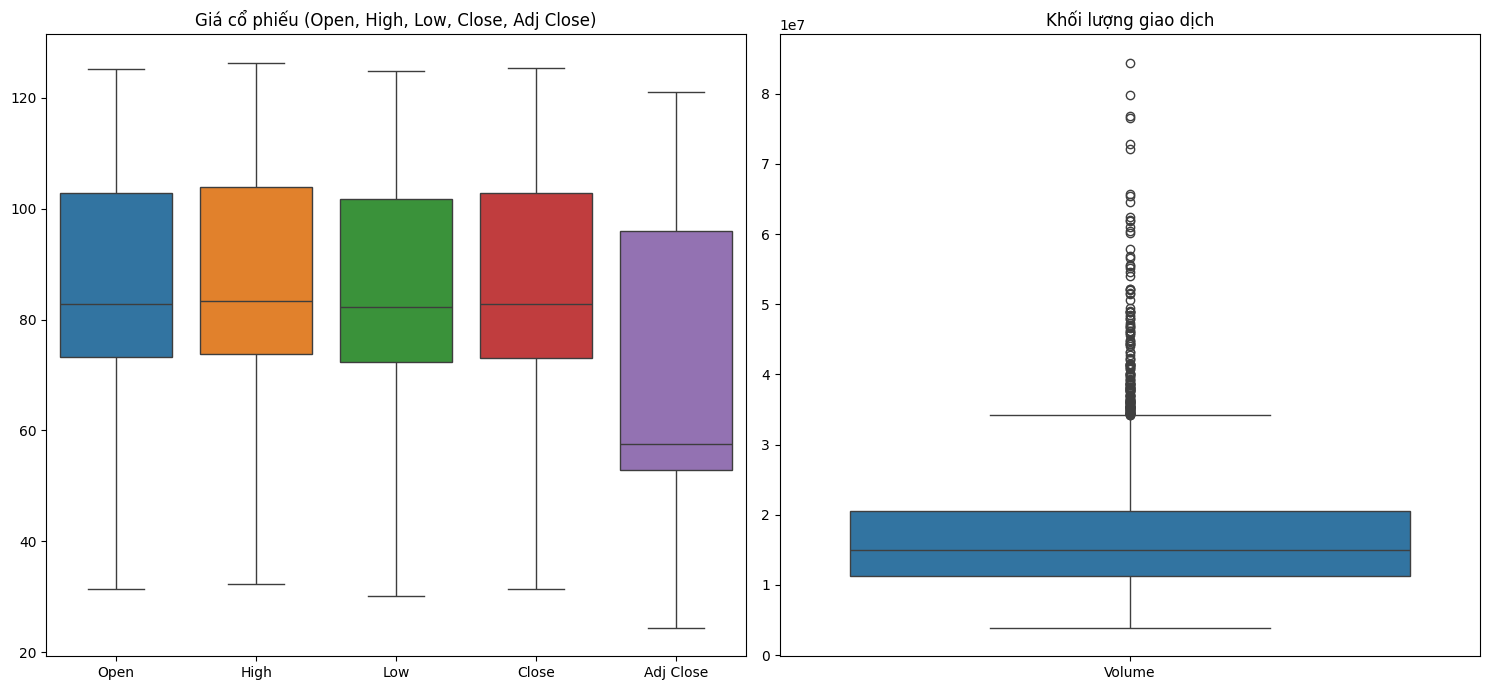


===== Outliers của mã XOM =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          152          2702        5.63


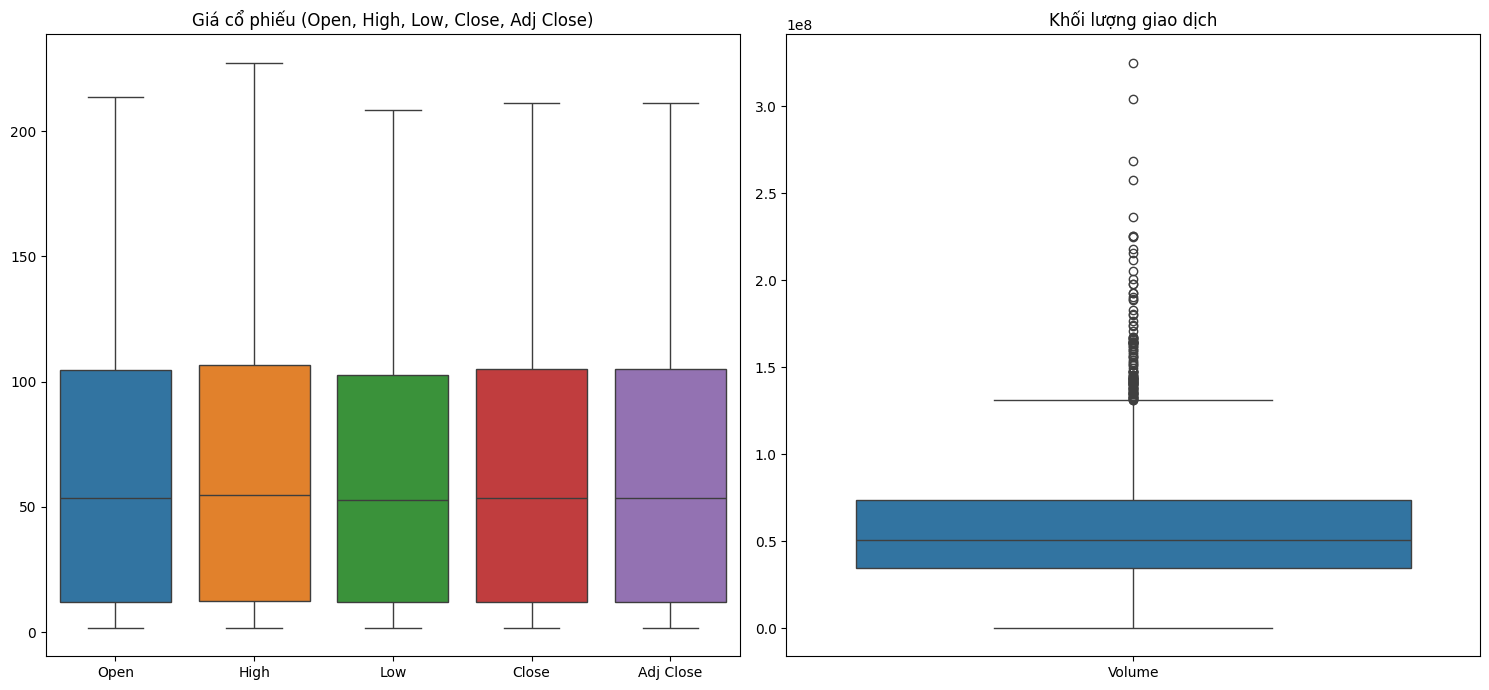


===== Outliers của mã AMD =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          111          2702        4.11


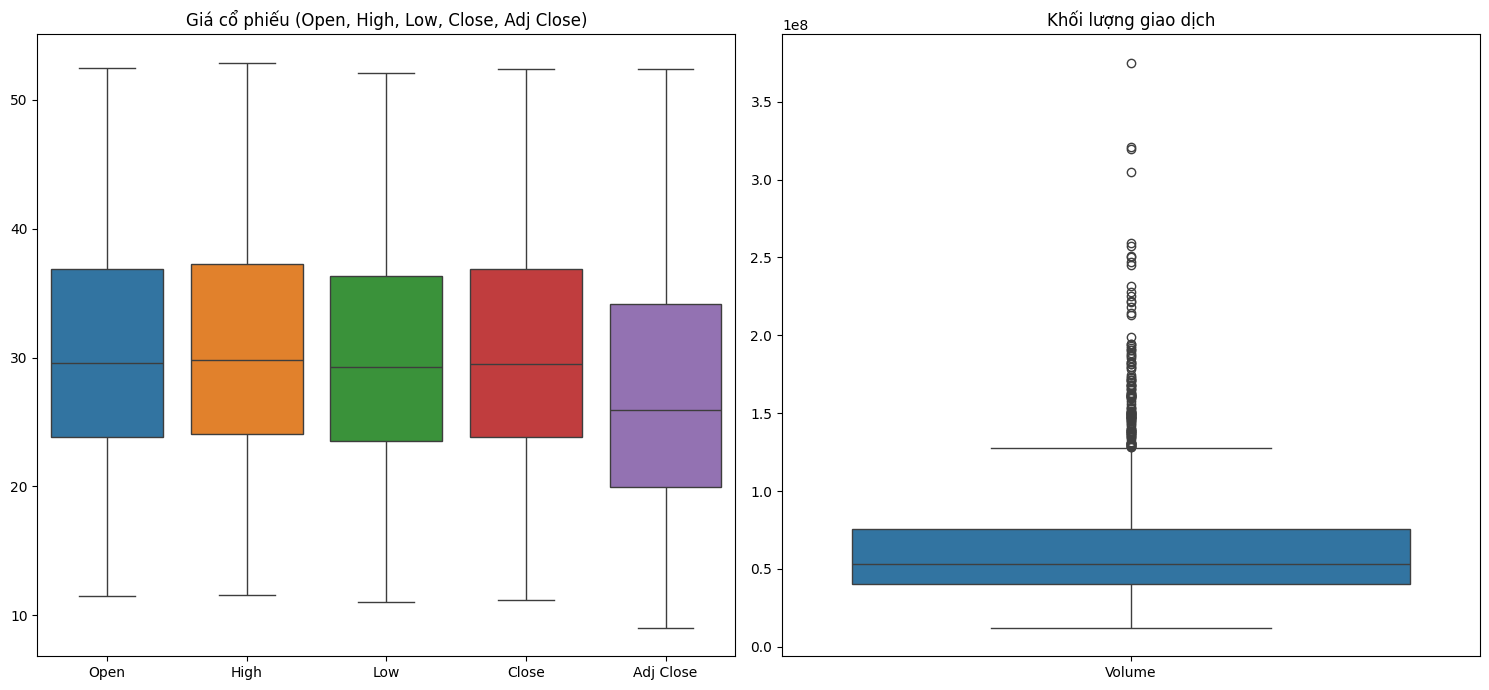


===== Outliers của mã BAC =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          123          2702        4.55


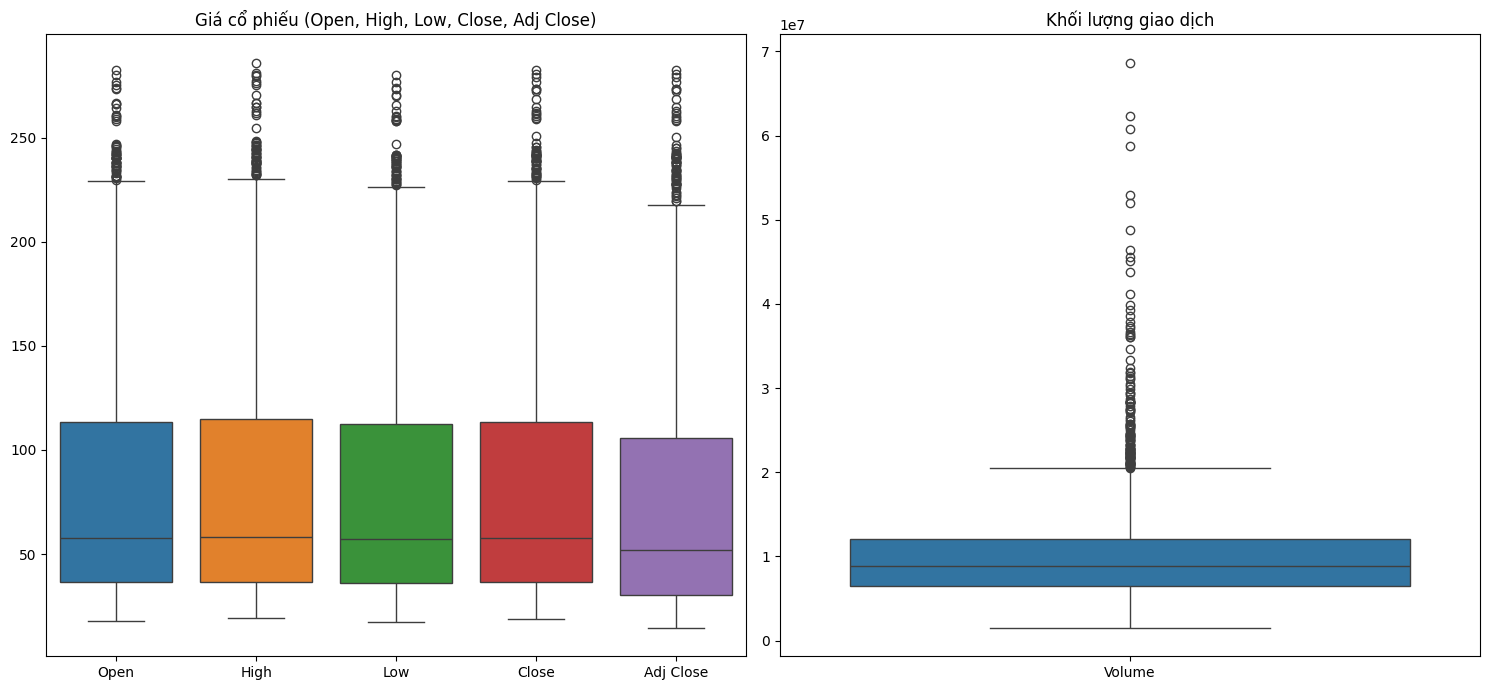


===== Outliers của mã TSM =====
           Outliers  Tổng giá trị  % Outliers
Open             57          2702        2.11
High             58          2702        2.15
Low              57          2702        2.11
Close            57          2702        2.11
Adj Close        72          2702        2.66
Volume          126          2702        4.66


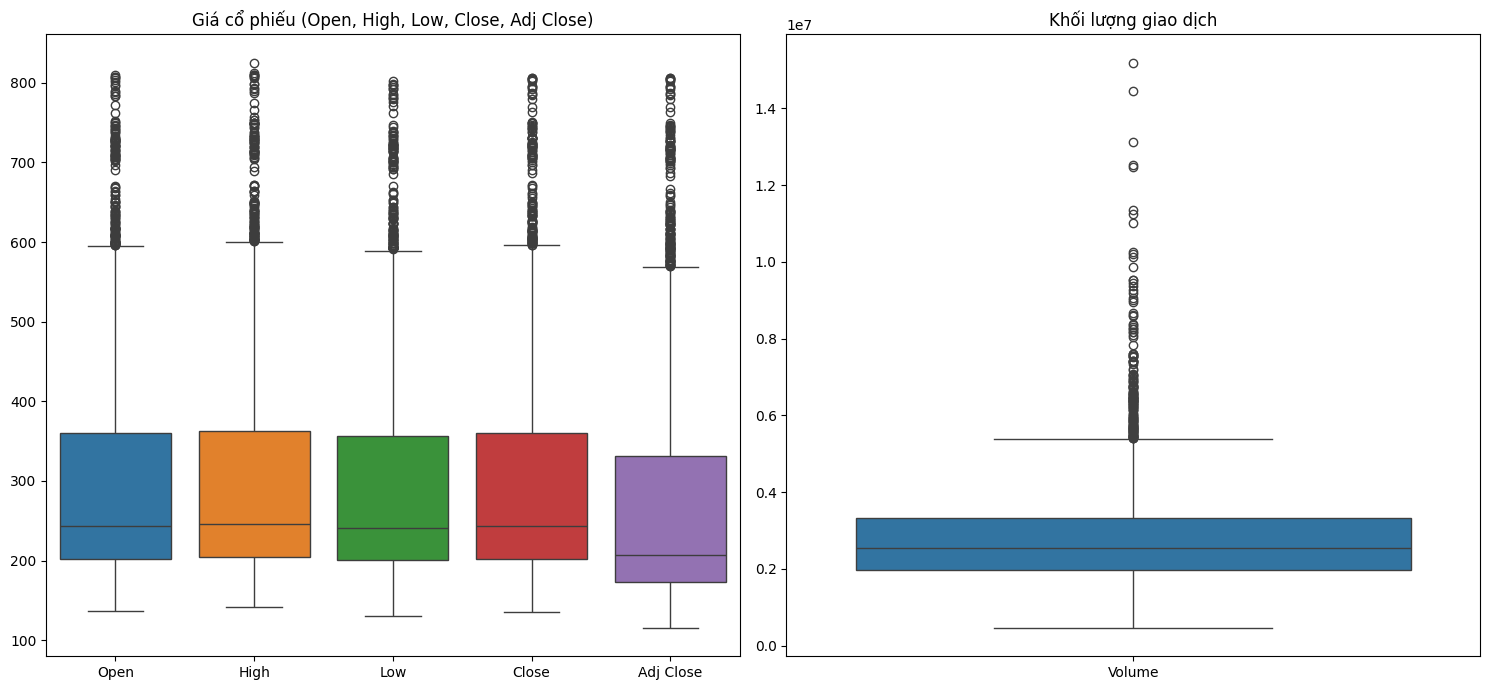


===== Outliers của mã GS =====
           Outliers  Tổng giá trị  % Outliers
Open            142          2702        5.26
High            144          2702        5.33
Low             142          2702        5.26
Close           140          2702        5.18
Adj Close       168          2702        6.22
Volume          150          2702        5.55


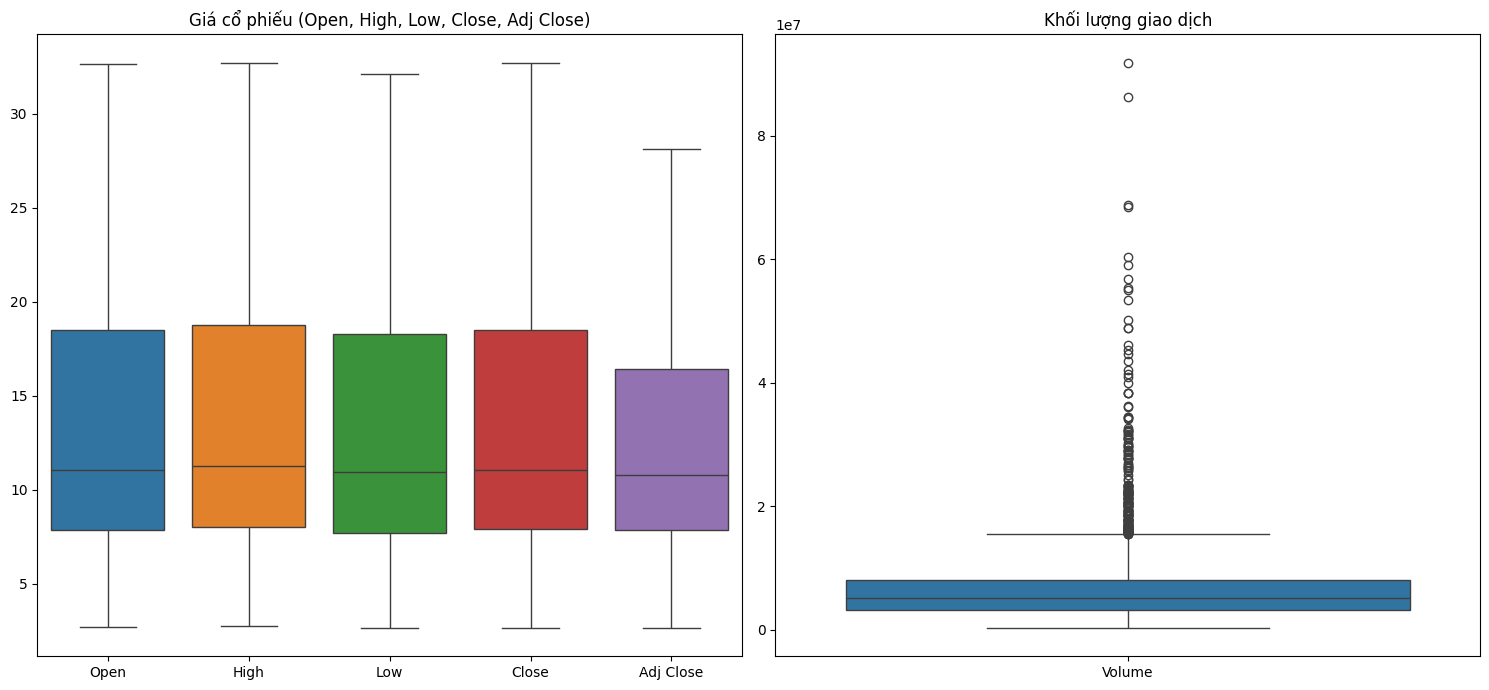


===== Outliers của mã COTY =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          192          2702        7.11


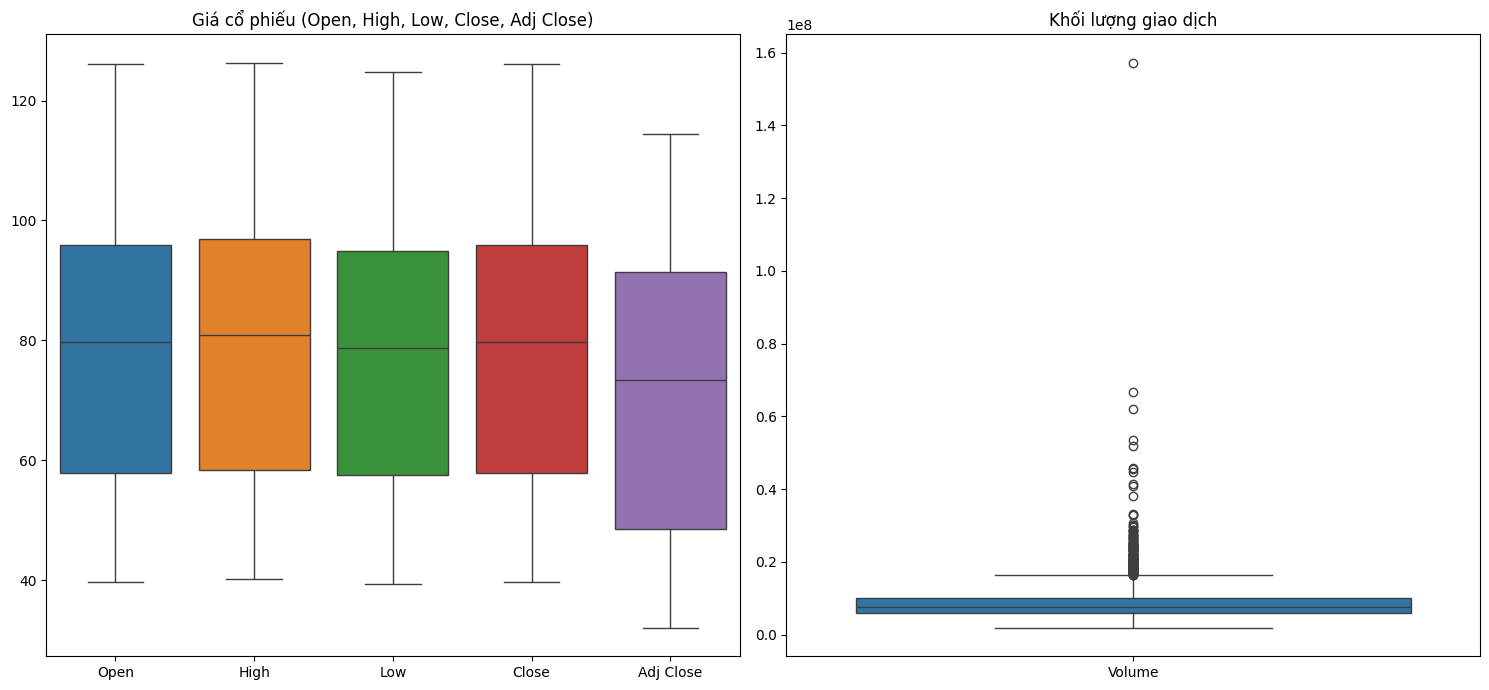


===== Outliers của mã SBUX =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          155          2702        5.74


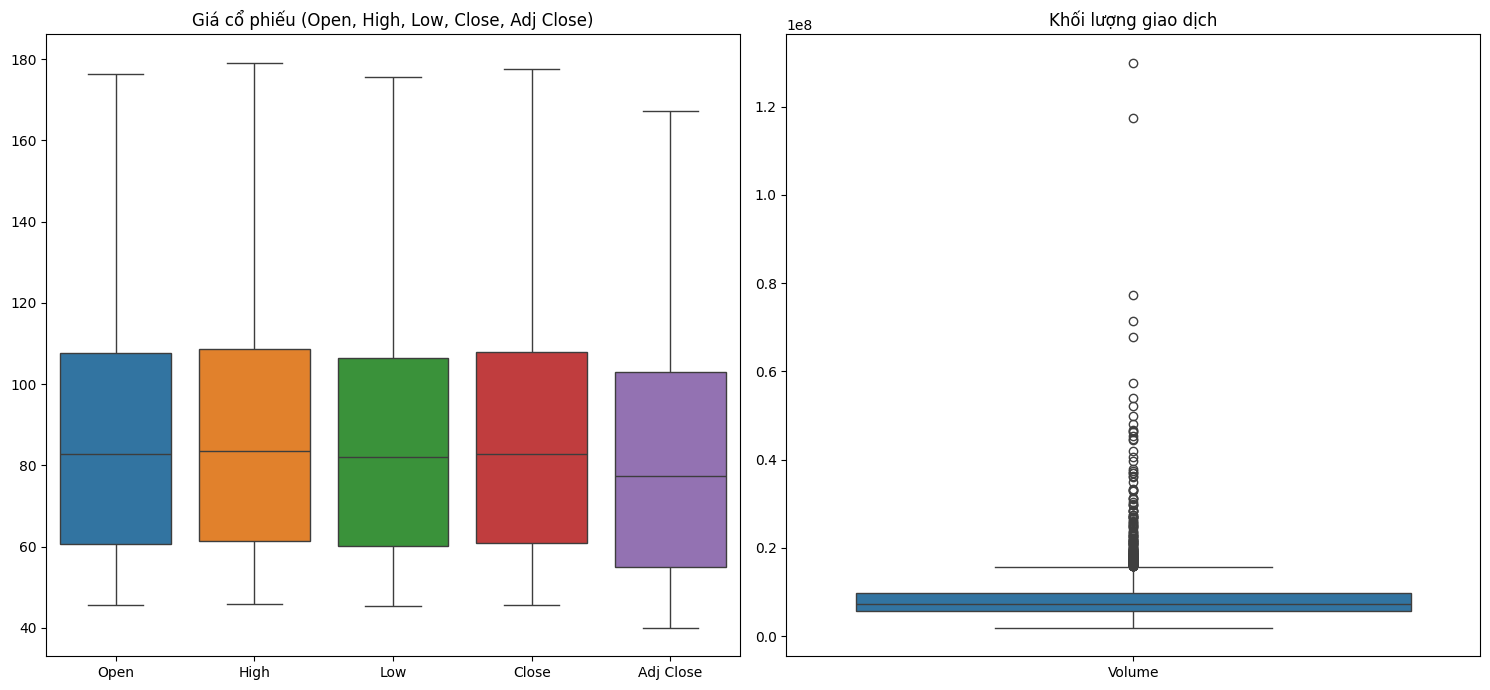


===== Outliers của mã NKE =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          180          2702        6.66


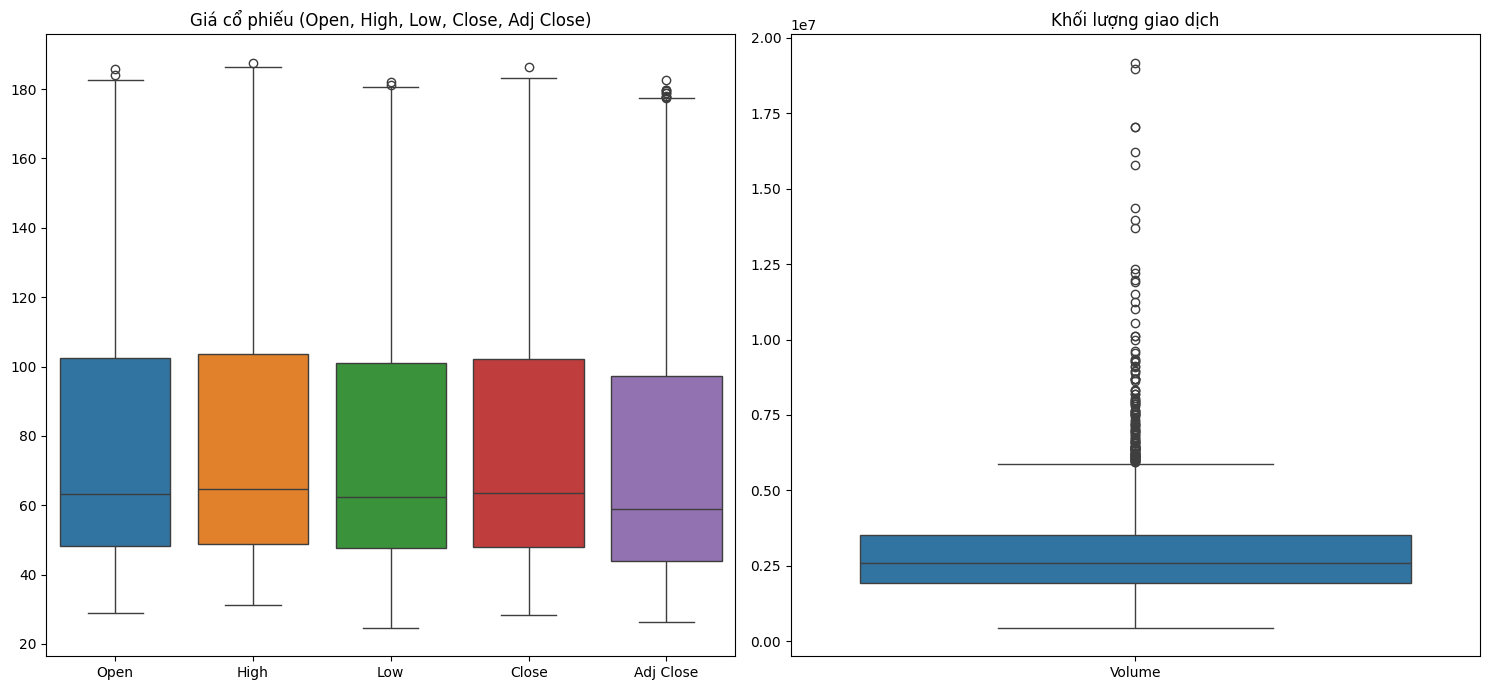


===== Outliers của mã LEN =====
           Outliers  Tổng giá trị  % Outliers
Open              2          2702        0.07
High              1          2702        0.04
Low               2          2702        0.07
Close             1          2702        0.04
Adj Close        10          2702        0.37
Volume          133          2702        4.92


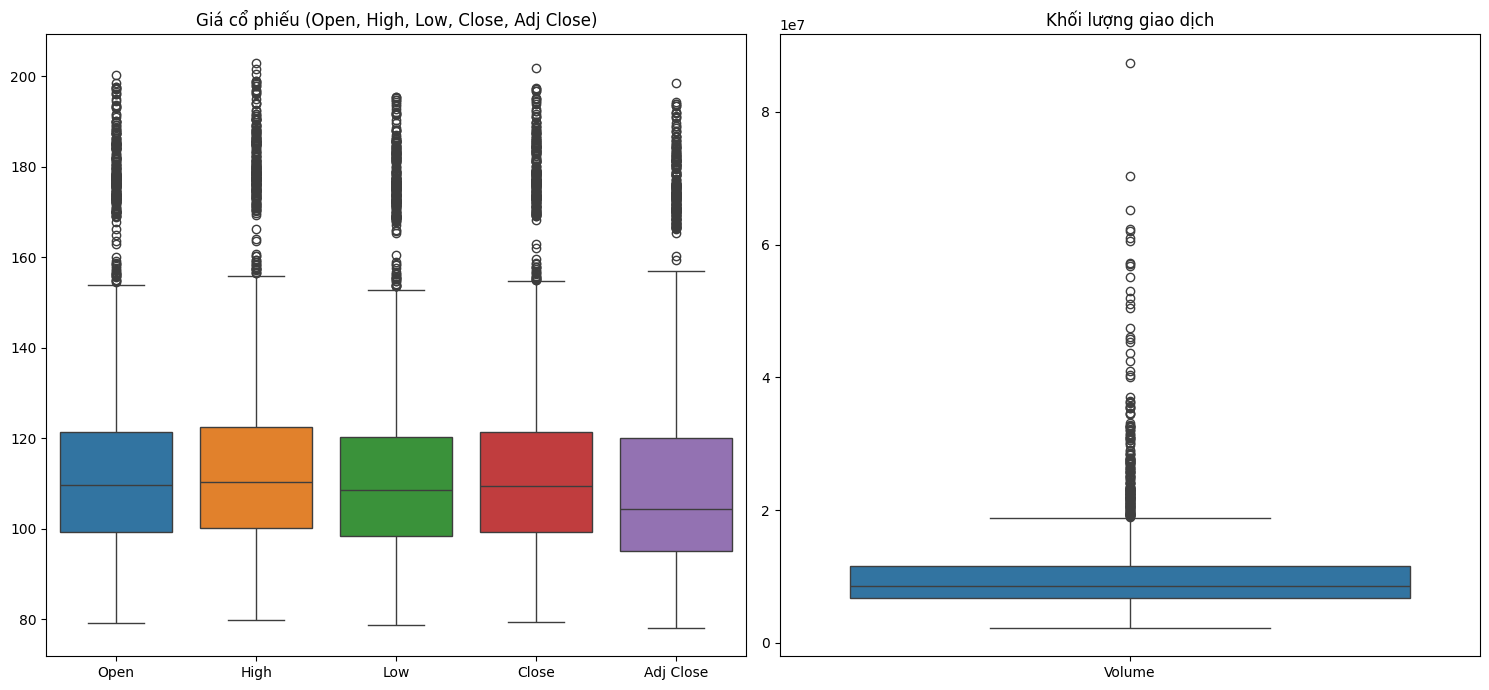


===== Outliers của mã DIS =====
           Outliers  Tổng giá trị  % Outliers
Open            254          2702        9.40
High            252          2702        9.33
Low             251          2702        9.29
Close           251          2702        9.29
Adj Close       232          2702        8.59
Volume          186          2702        6.88


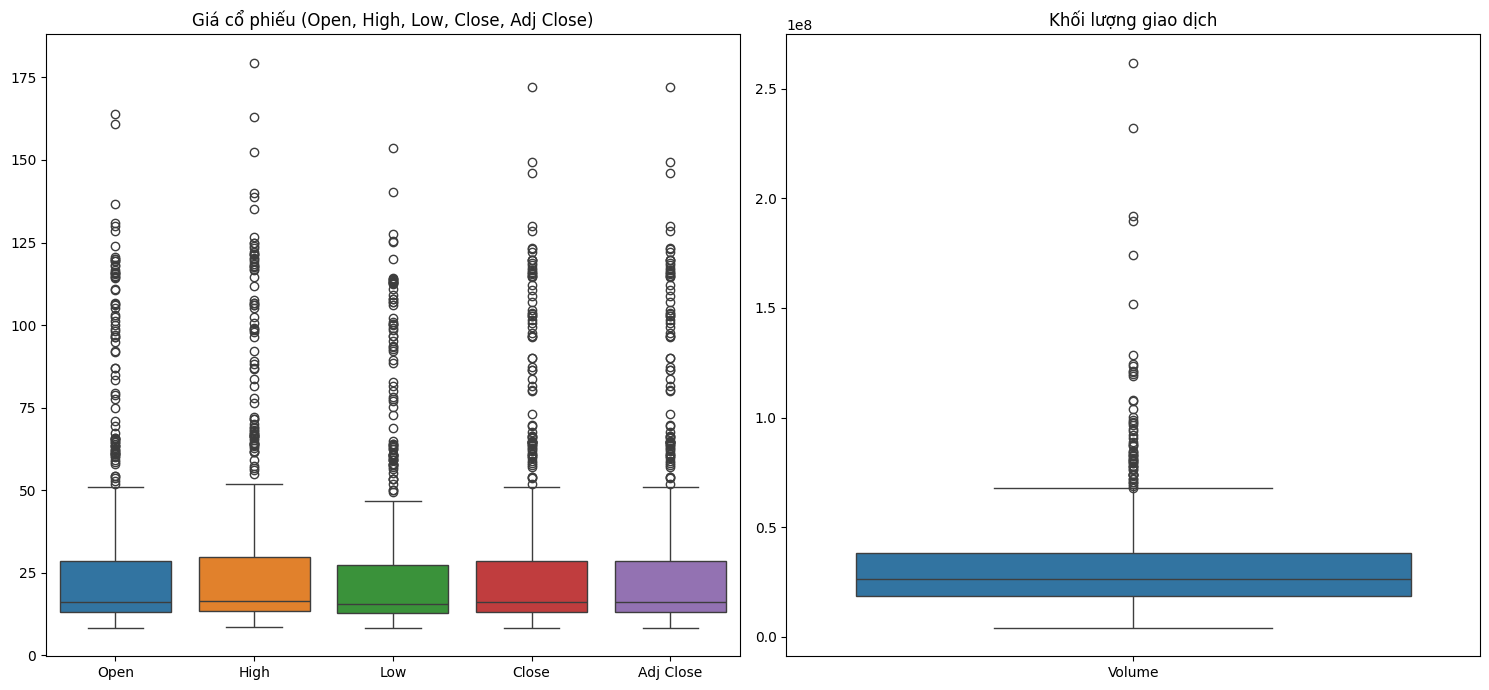


===== Outliers của mã RIVN =====
           Outliers  Tổng giá trị  % Outliers
Open             80           975        8.21
High             80           975        8.21
Low              80           975        8.21
Close            79           975        8.10
Adj Close        79           975        8.10
Volume           59           975        6.05


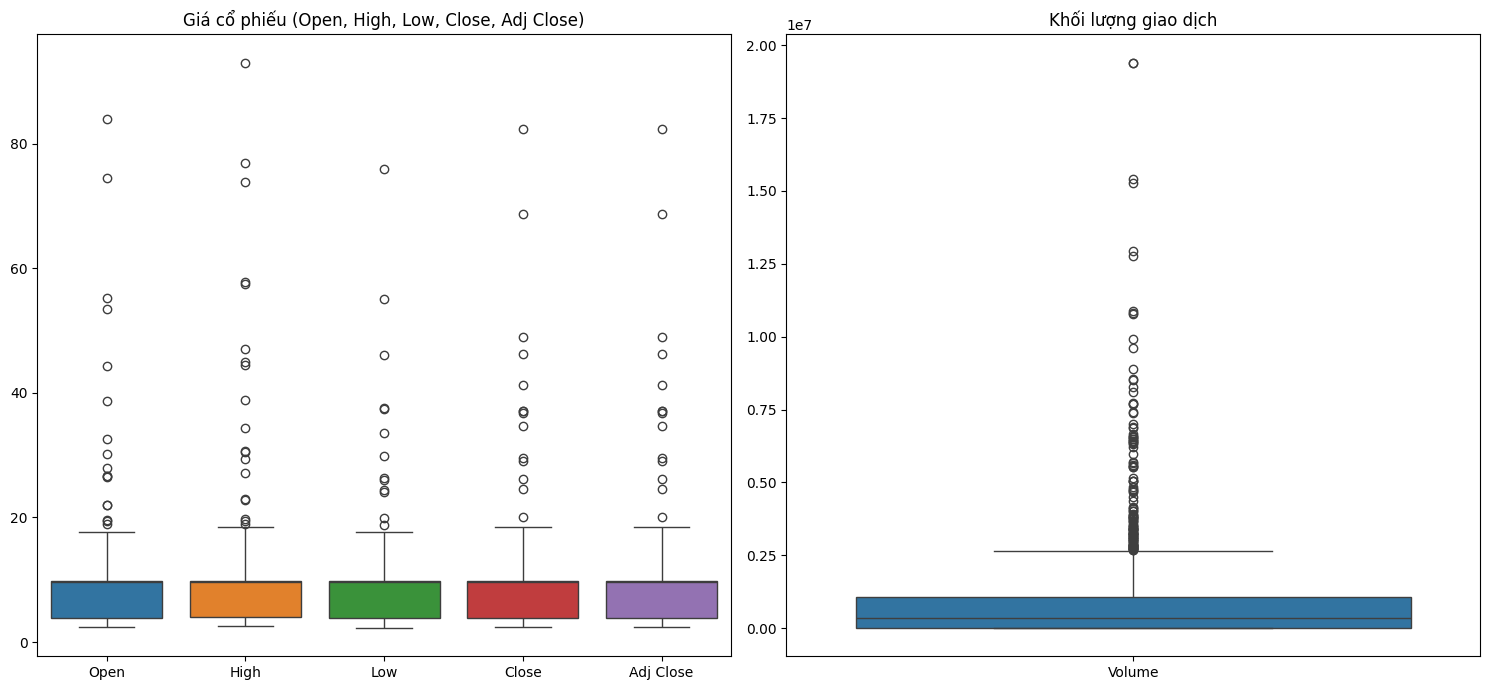


===== Outliers của mã VFS =====
           Outliers  Tổng giá trị  % Outliers
Open             17          1021        1.67
High             19          1021        1.86
Low              13          1021        1.27
Close            14          1021        1.37
Adj Close        14          1021        1.37
Volume          118          1021       11.56


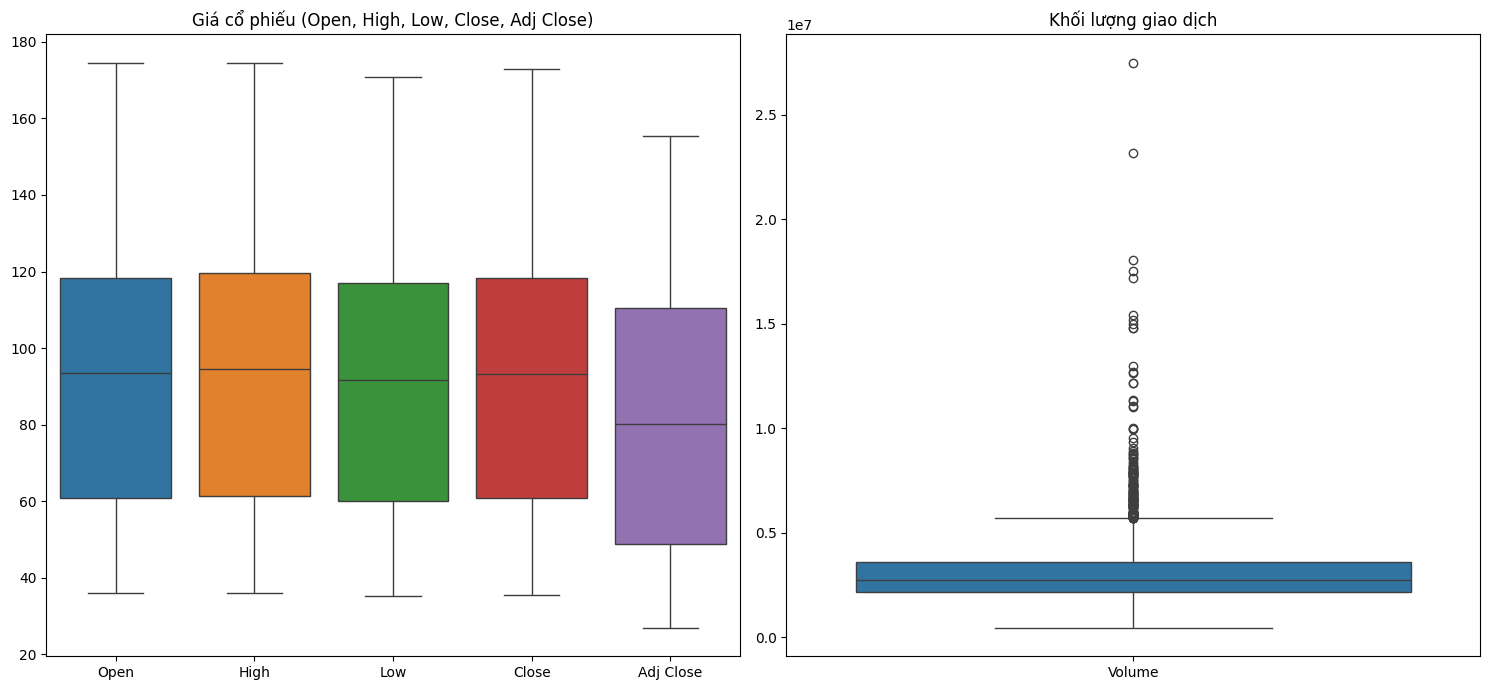


===== Outliers của mã PLD =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          144          2702        5.33


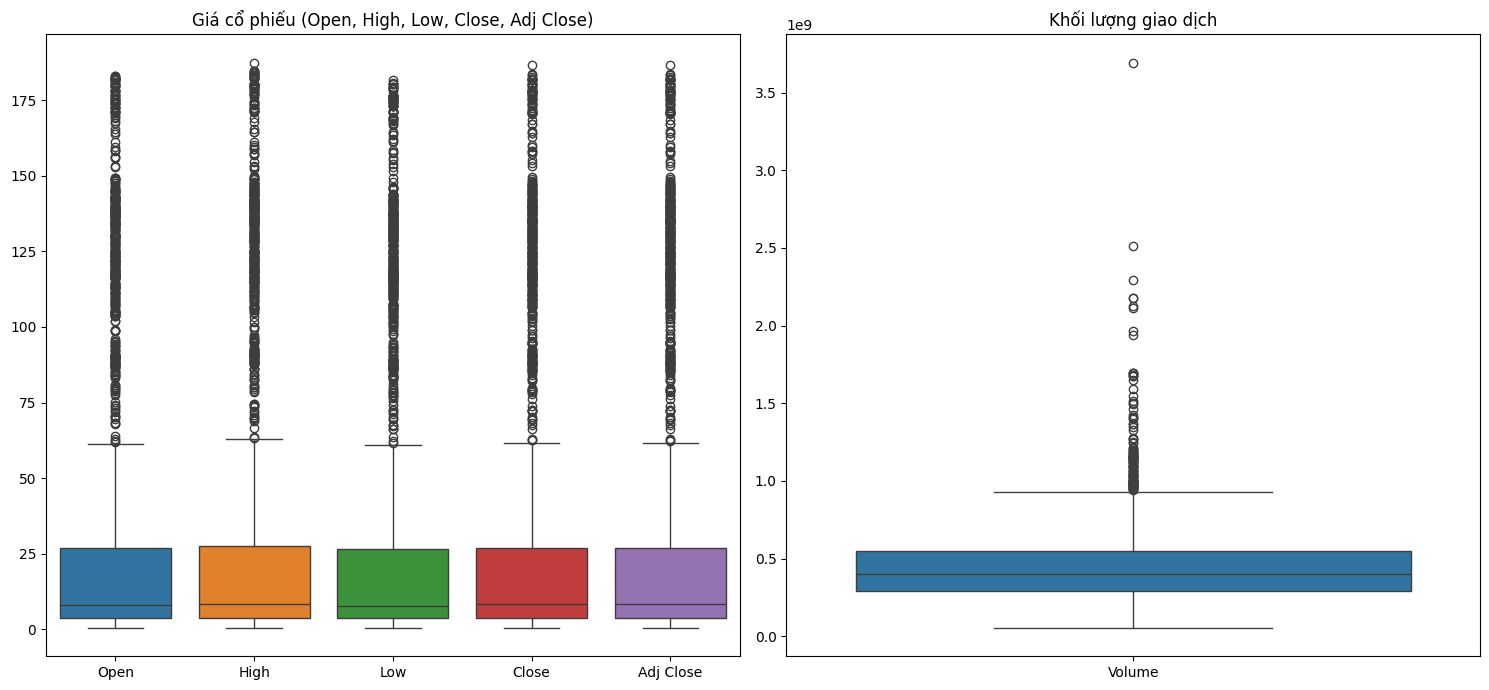


===== Outliers của mã NVDA =====
           Outliers  Tổng giá trị  % Outliers
Open            419          2702       15.51
High            418          2702       15.47
Low             418          2702       15.47
Close           419          2702       15.51
Adj Close       419          2702       15.51
Volume          113          2702        4.18


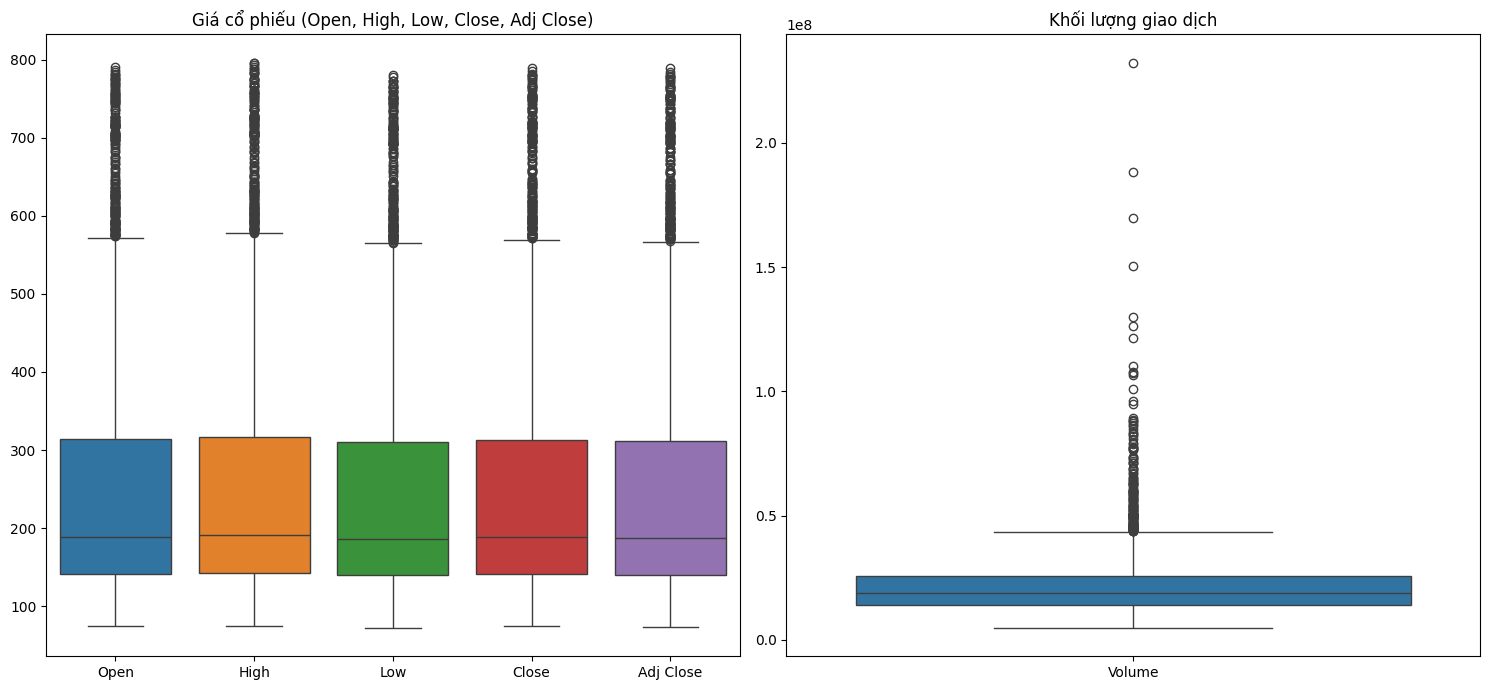


===== Outliers của mã META =====
           Outliers  Tổng giá trị  % Outliers
Open            216          2702        7.99
High            217          2702        8.03
Low             216          2702        7.99
Close           220          2702        8.14
Adj Close       221          2702        8.18
Volume          159          2702        5.88


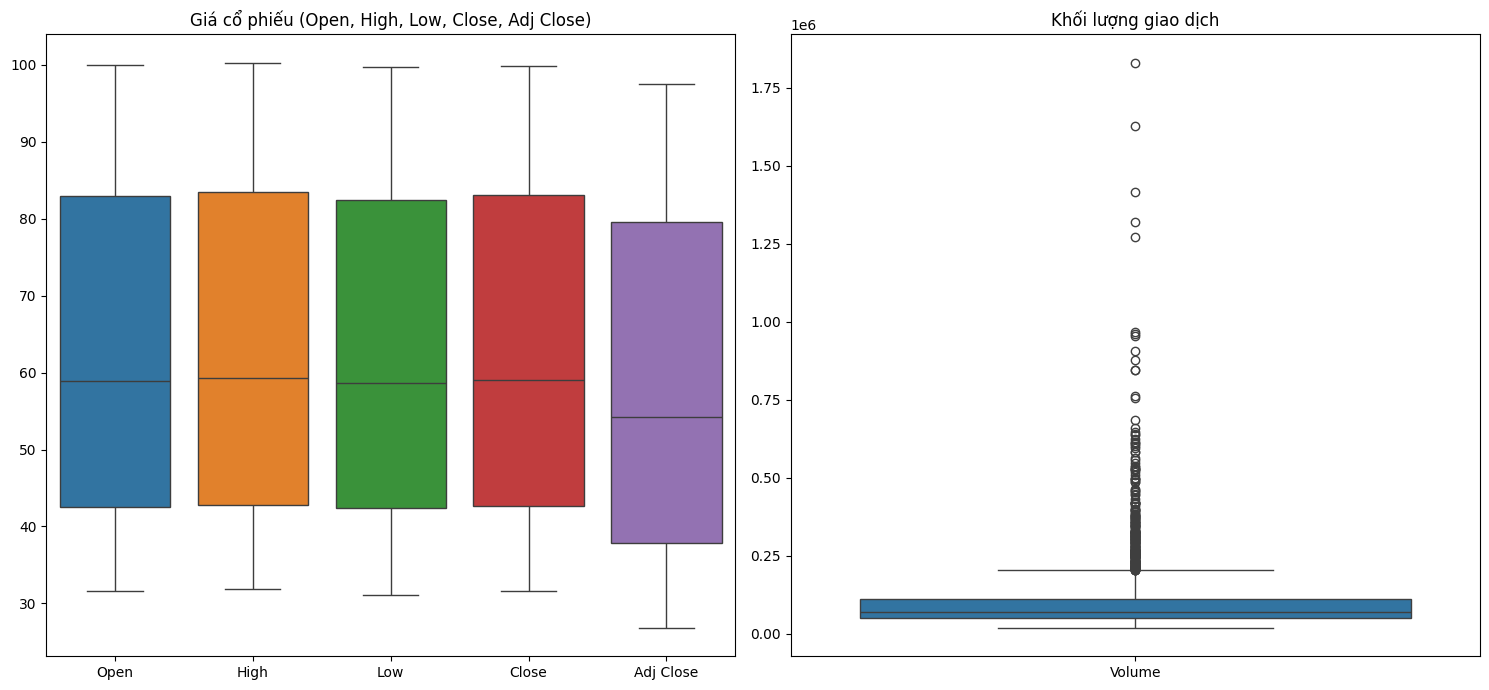


===== Outliers của mã LRLCY =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          243          2702        8.99


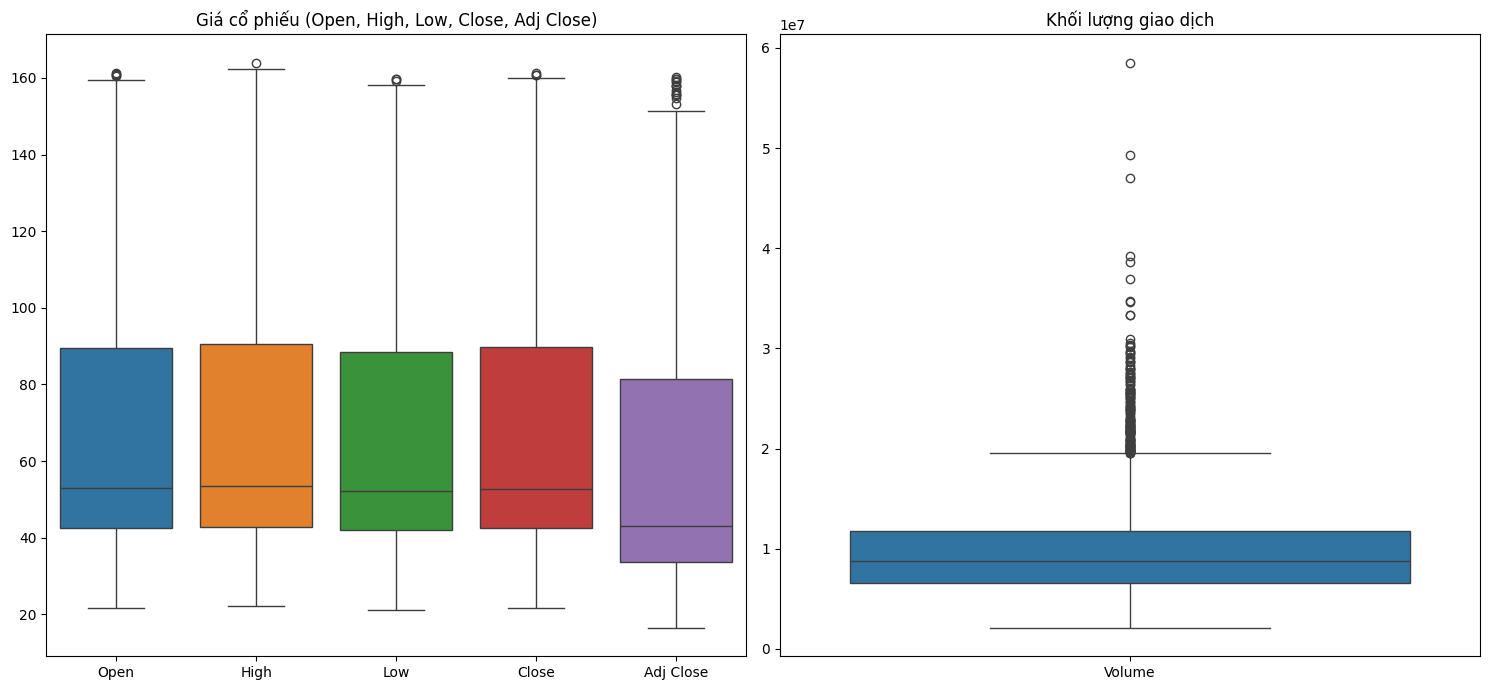


===== Outliers của mã MS =====
           Outliers  Tổng giá trị  % Outliers
Open              4          2702        0.15
High              1          2702        0.04
Low               3          2702        0.11
Close             3          2702        0.11
Adj Close        15          2702        0.56
Volume          144          2702        5.33


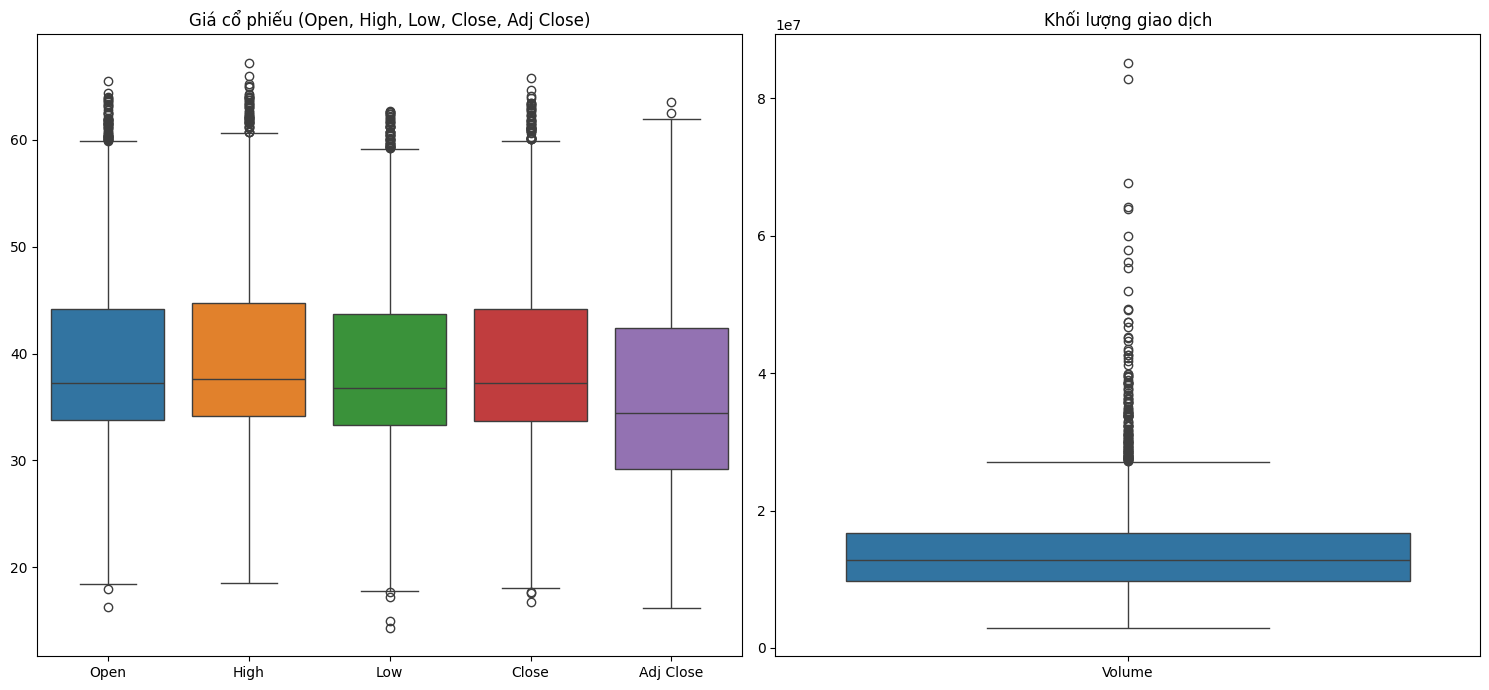


===== Outliers của mã GM =====
           Outliers  Tổng giá trị  % Outliers
Open             56          2702        2.07
High             49          2702        1.81
Low              53          2702        1.96
Close            53          2702        1.96
Adj Close         2          2702        0.07
Volume          133          2702        4.92


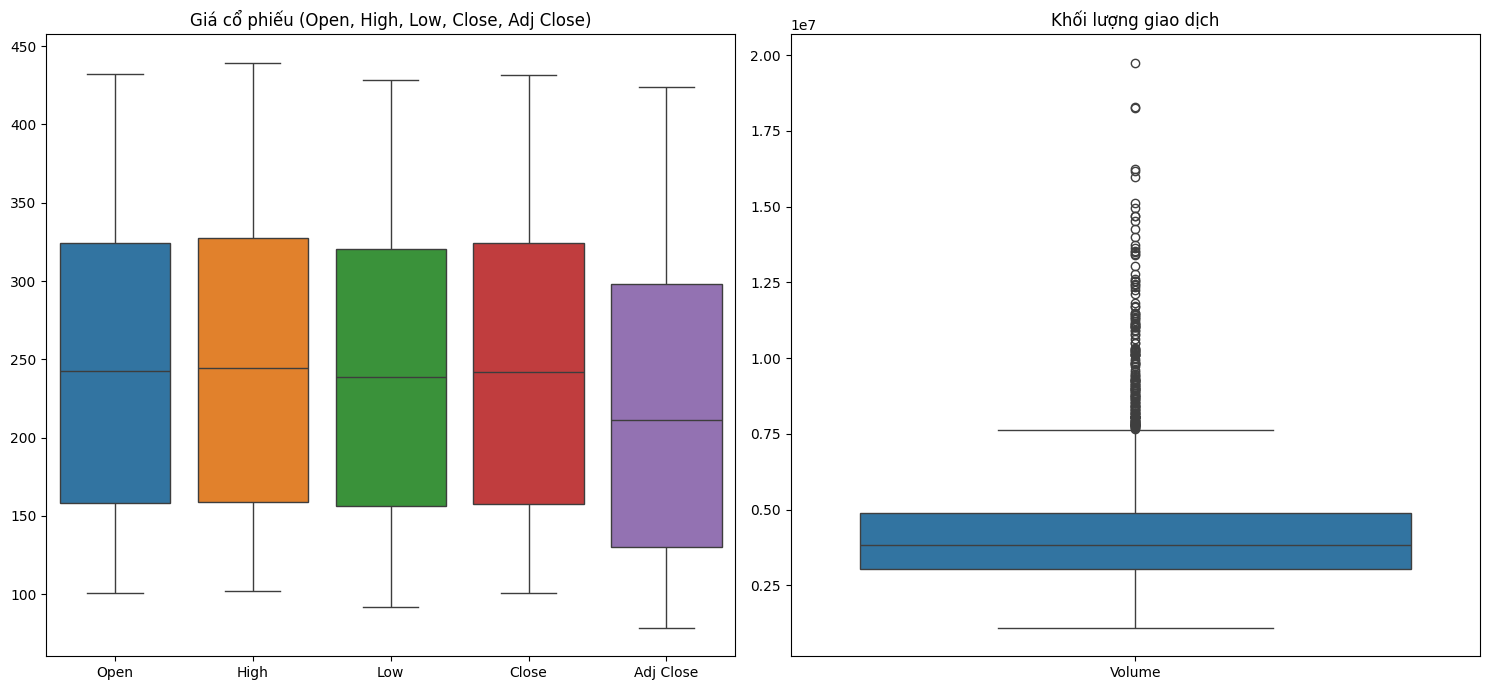


===== Outliers của mã HD =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          166          2702        6.14


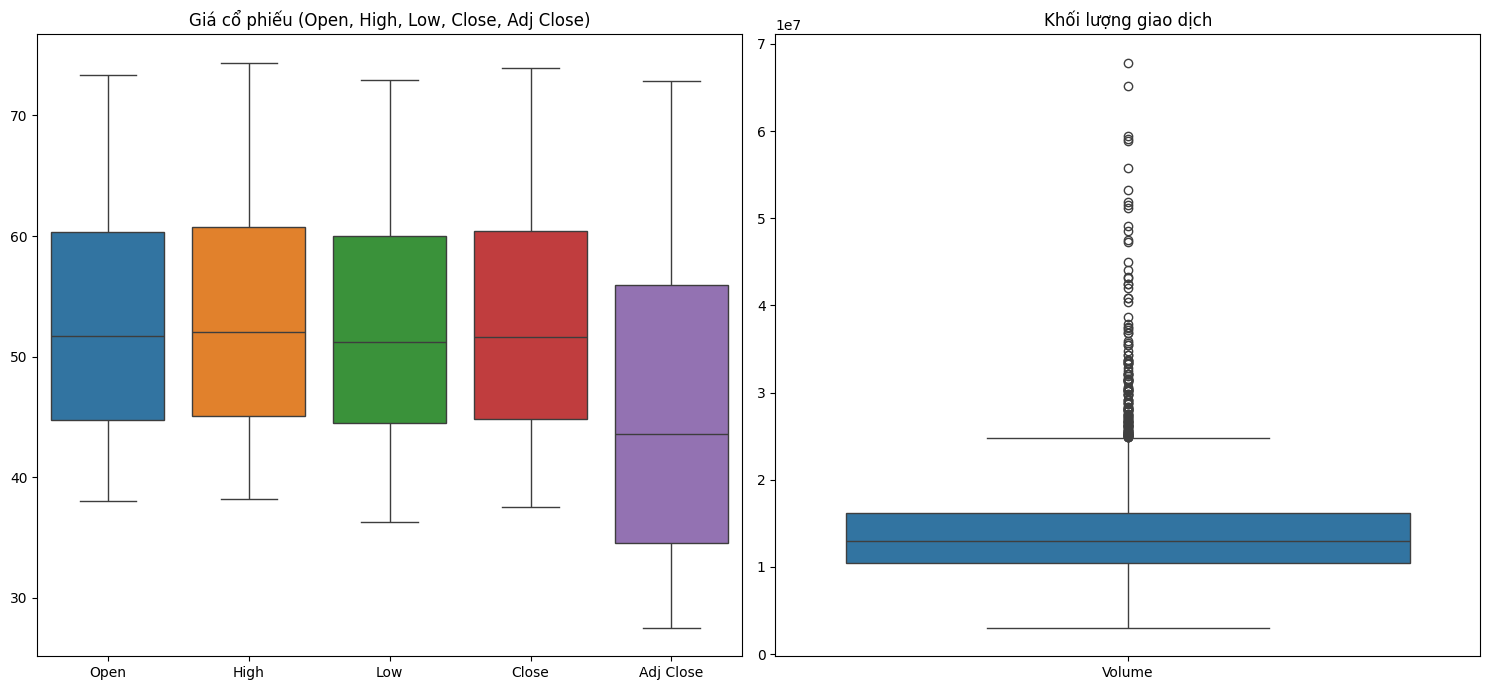


===== Outliers của mã KO =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          141          2702        5.22


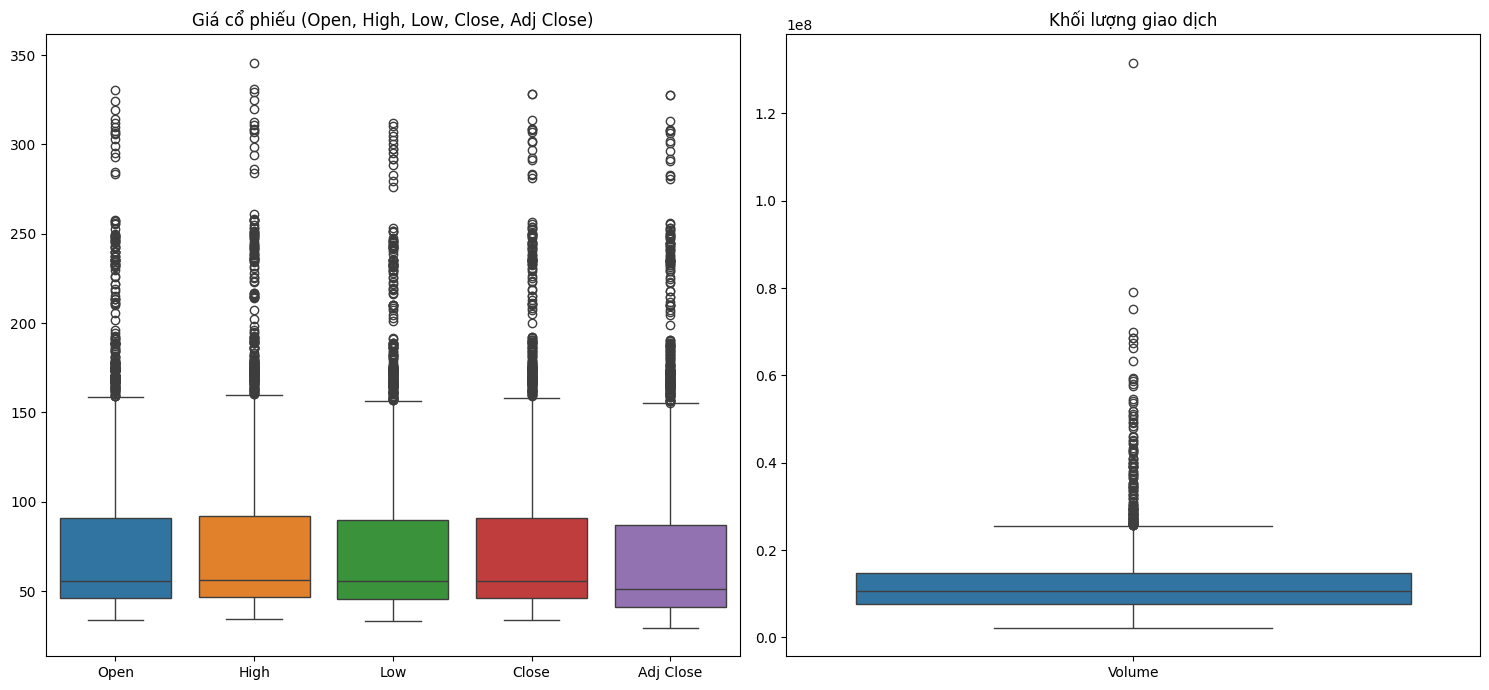


===== Outliers của mã ORCL =====
           Outliers  Tổng giá trị  % Outliers
Open            206          2702        7.62
High            210          2702        7.77
Low             209          2702        7.74
Close           207          2702        7.66
Adj Close       214          2702        7.92
Volume          132          2702        4.89


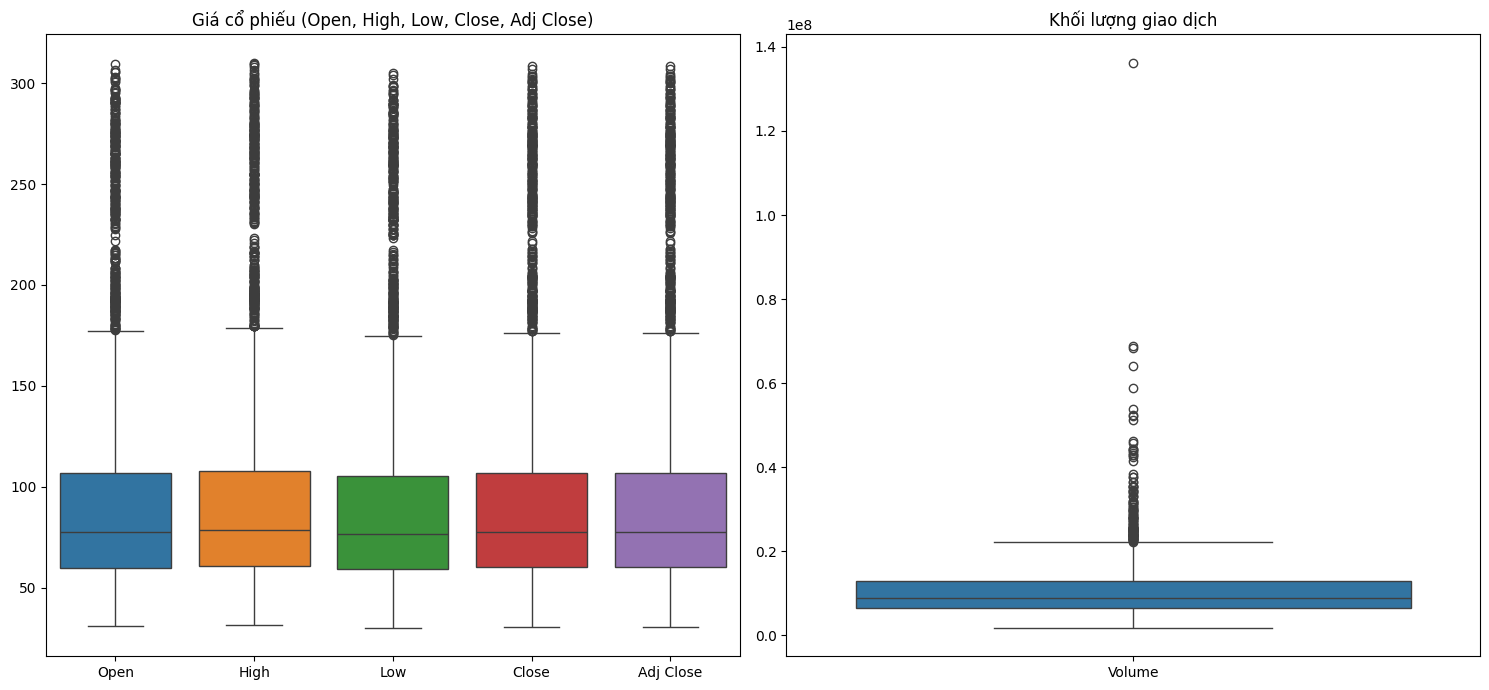


===== Outliers của mã PYPL =====
           Outliers  Tổng giá trị  % Outliers
Open            378          2576       14.67
High            383          2576       14.87
Low             374          2576       14.52
Close           378          2576       14.67
Adj Close       378          2576       14.67
Volume          126          2576        4.89


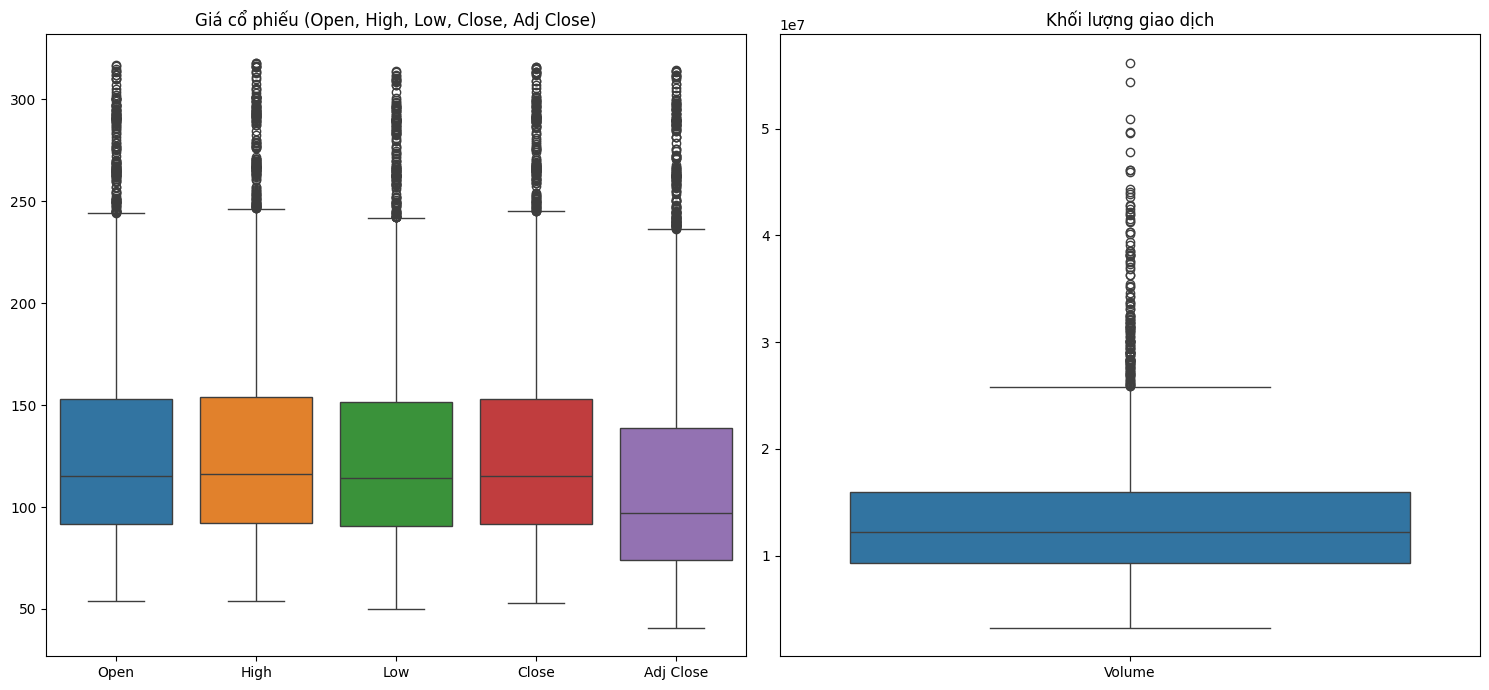


===== Outliers của mã JPM =====
           Outliers  Tổng giá trị  % Outliers
Open            159          2702        5.88
High            163          2702        6.03
Low             160          2702        5.92
Close           157          2702        5.81
Adj Close       184          2702        6.81
Volume          144          2702        5.33


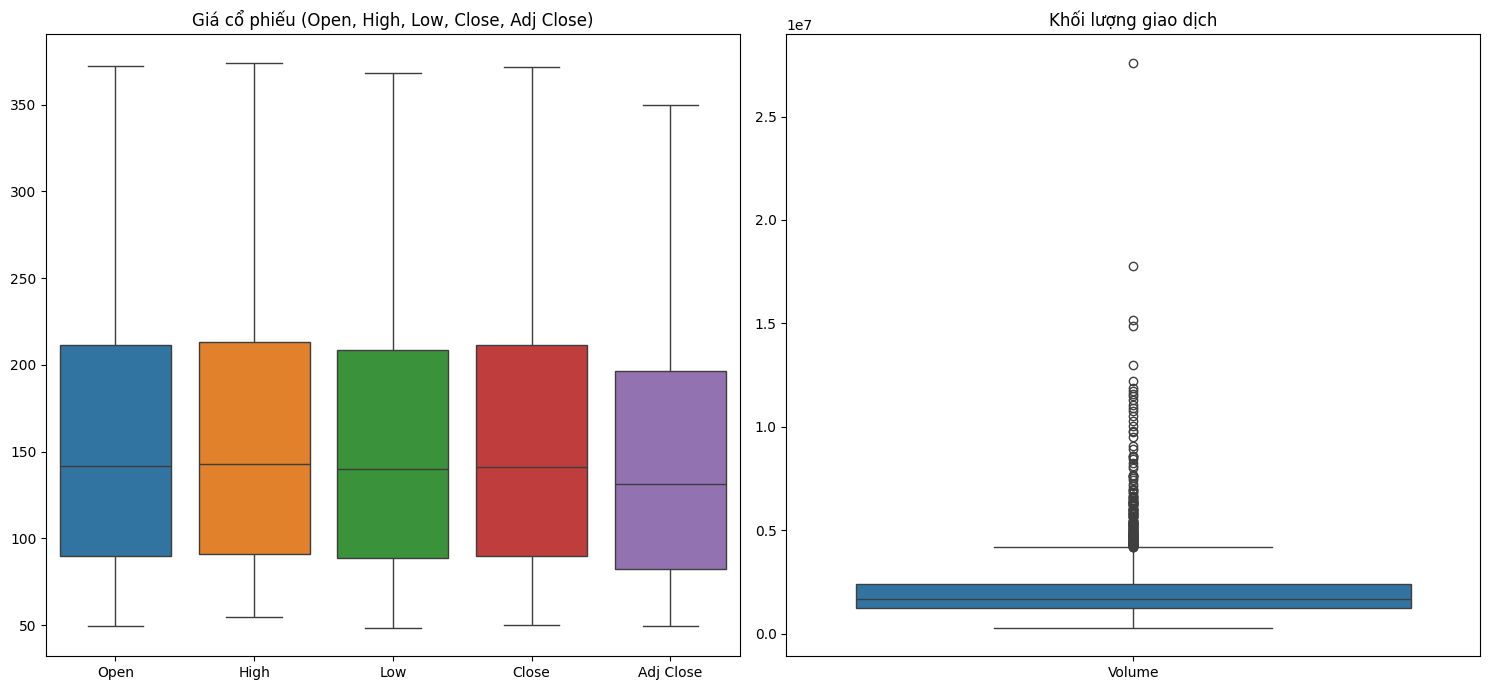


===== Outliers của mã EL =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          183          2702        6.77


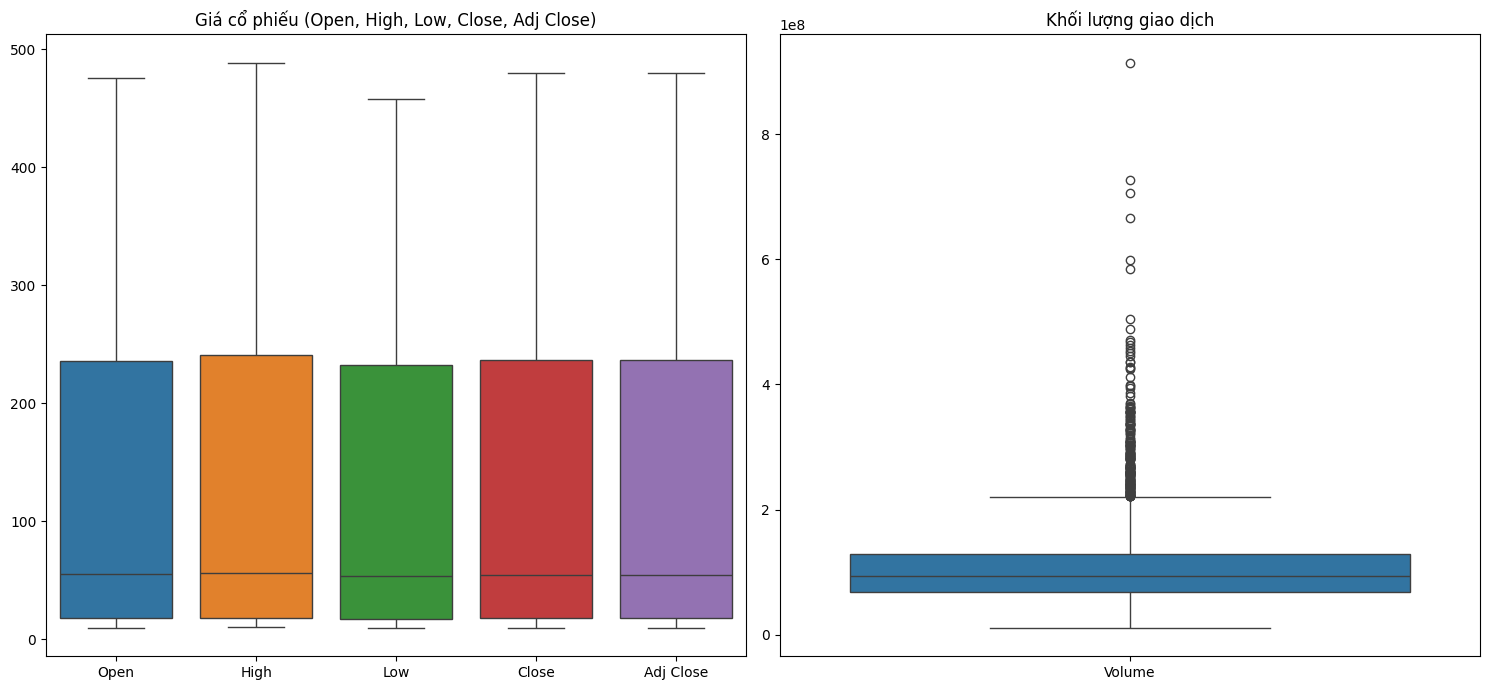


===== Outliers của mã TSLA =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          191          2702        7.07


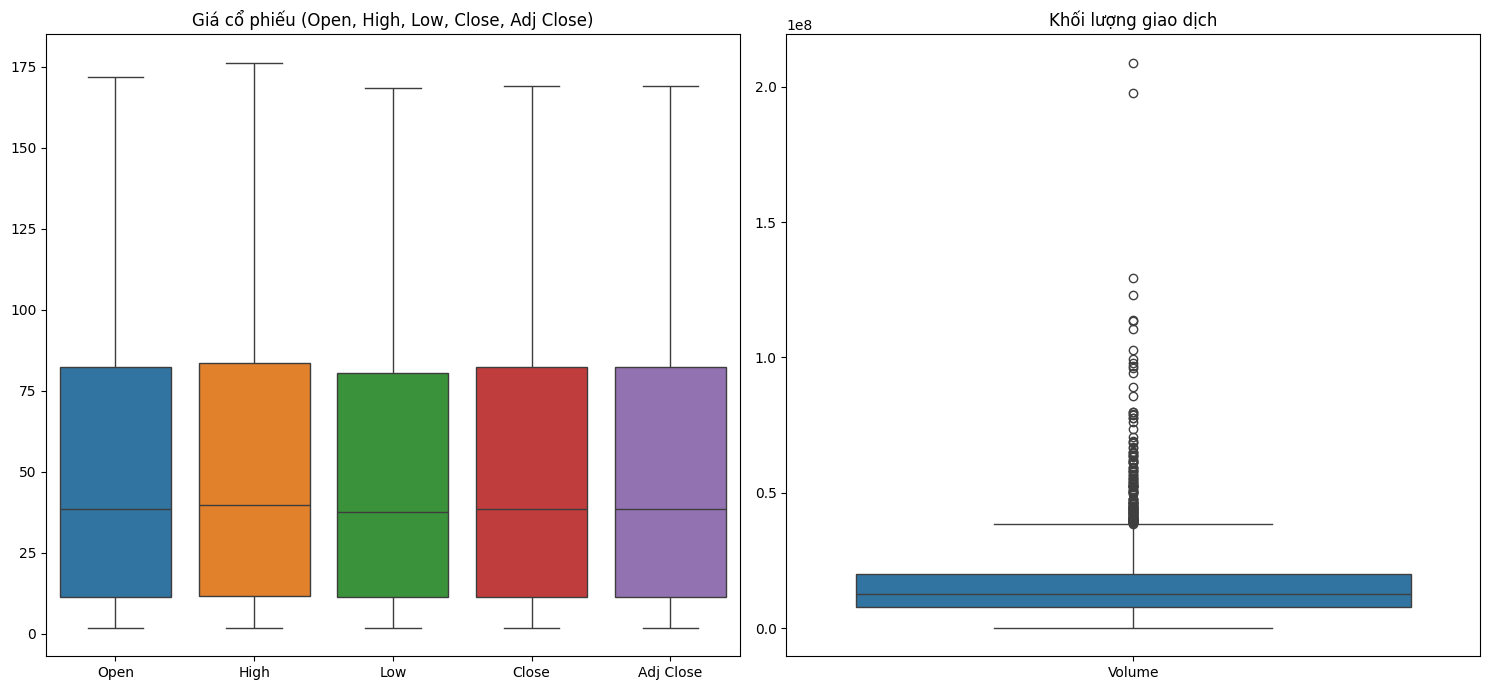


===== Outliers của mã SHOP =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2607        0.00
High              0          2607        0.00
Low               0          2607        0.00
Close             0          2607        0.00
Adj Close         0          2607        0.00
Volume          145          2607        5.56


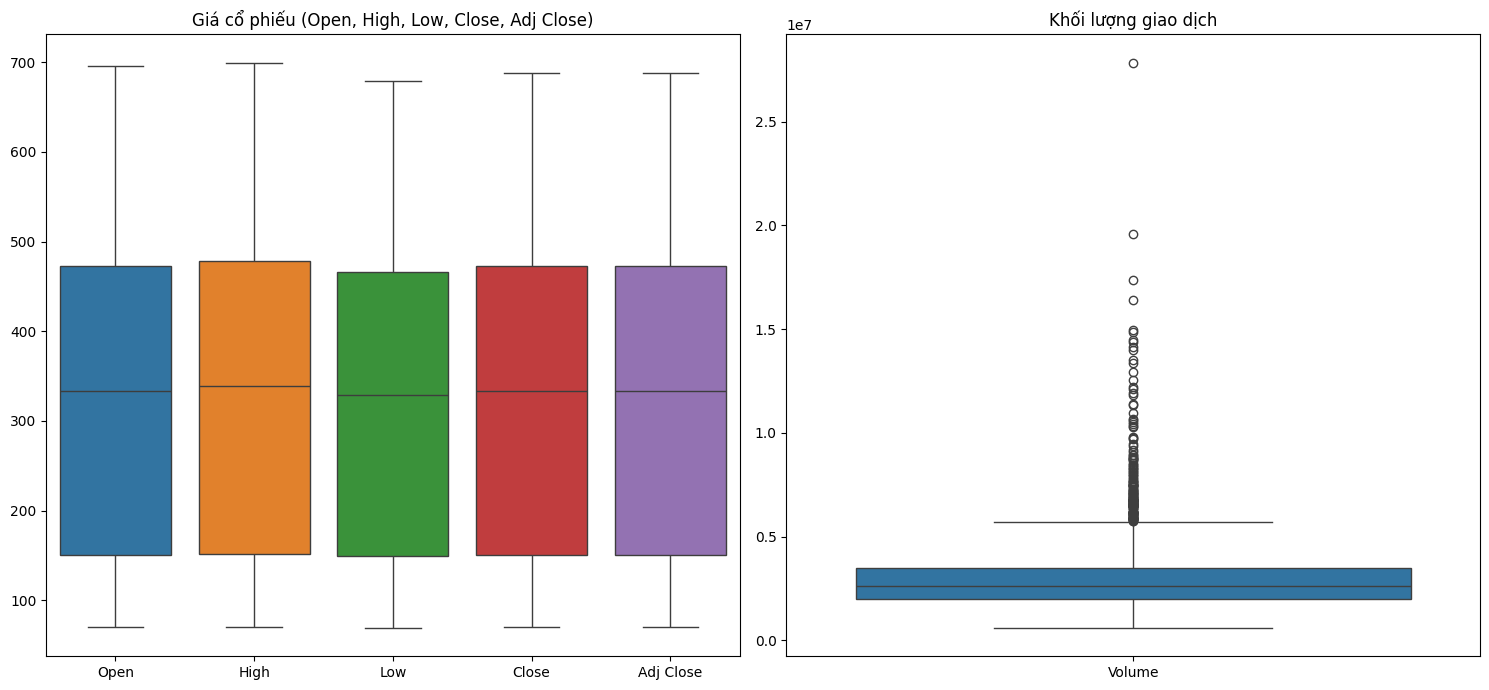


===== Outliers của mã ADBE =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702         0.0
High              0          2702         0.0
Low               0          2702         0.0
Close             0          2702         0.0
Adj Close         0          2702         0.0
Volume          154          2702         5.7


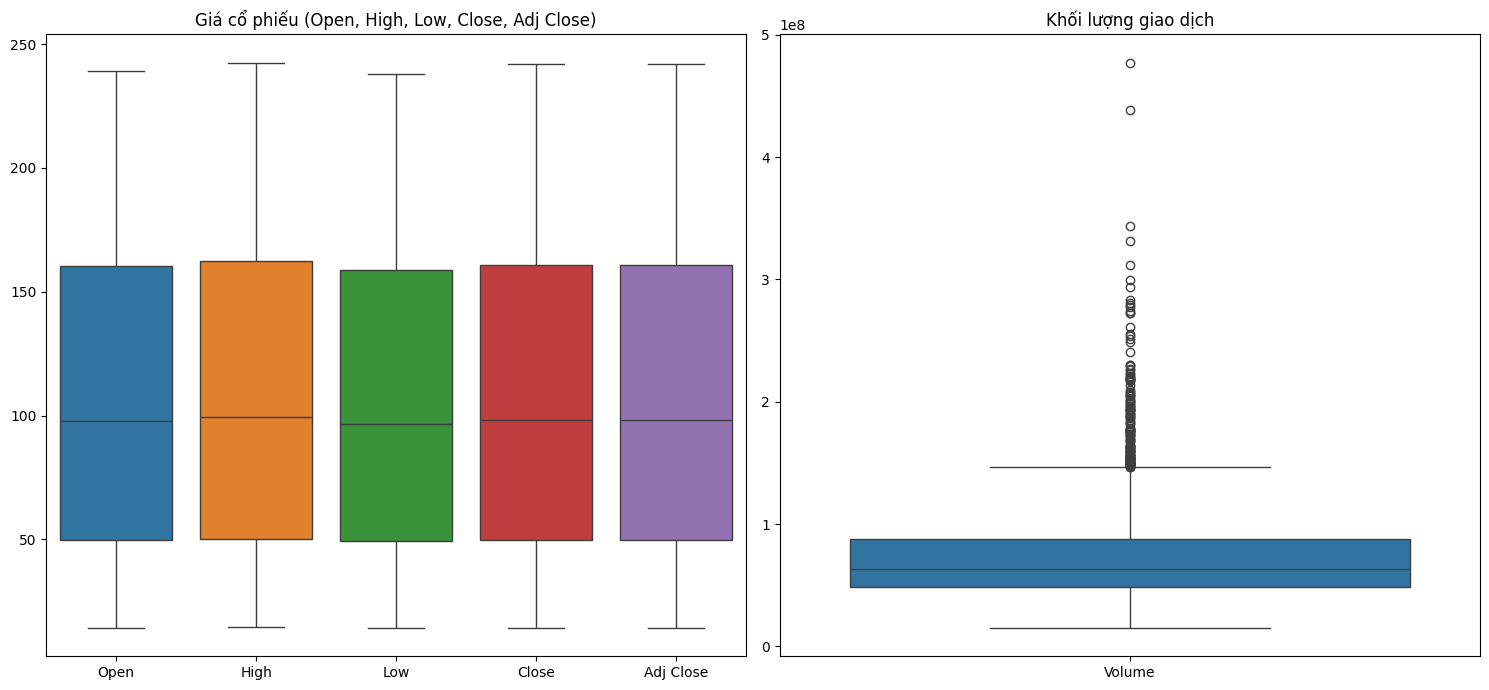


===== Outliers của mã AMZN =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          142          2702        5.26


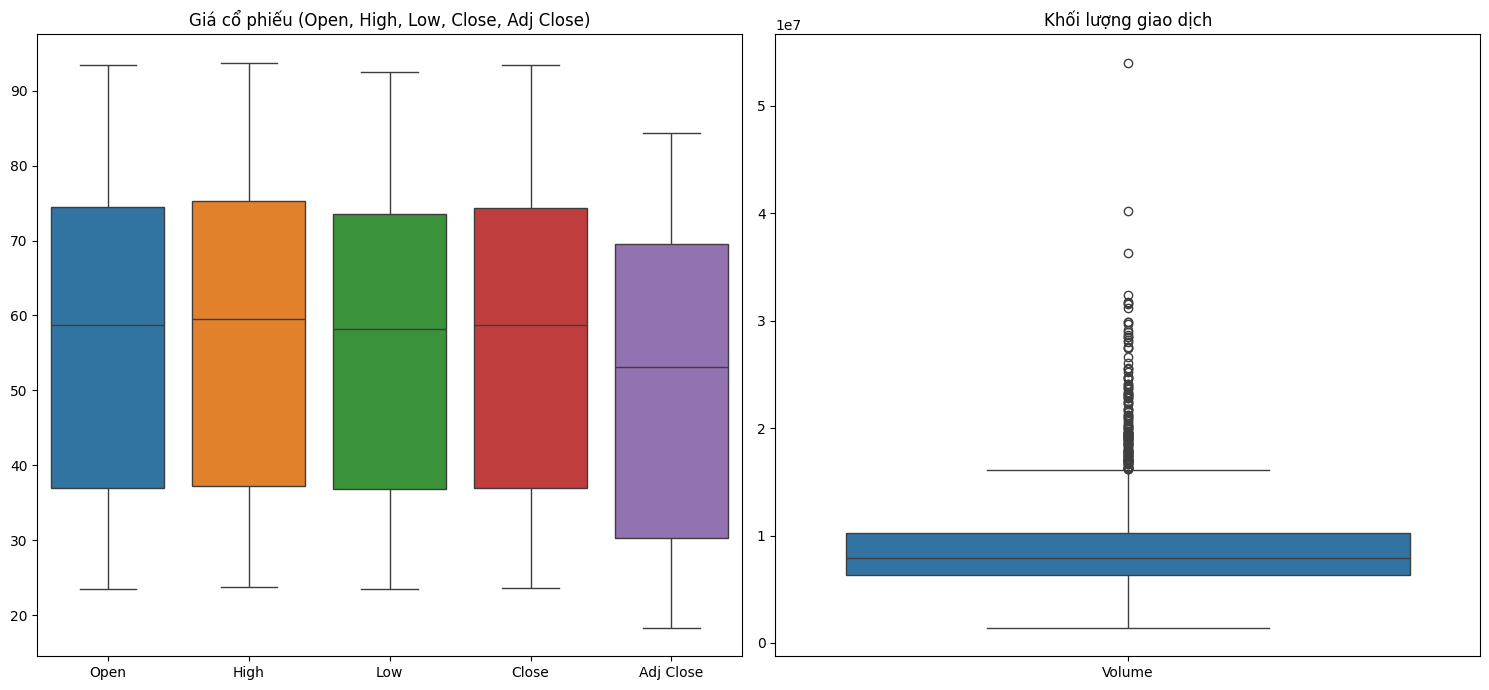


===== Outliers của mã NEE =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          148          2702        5.48


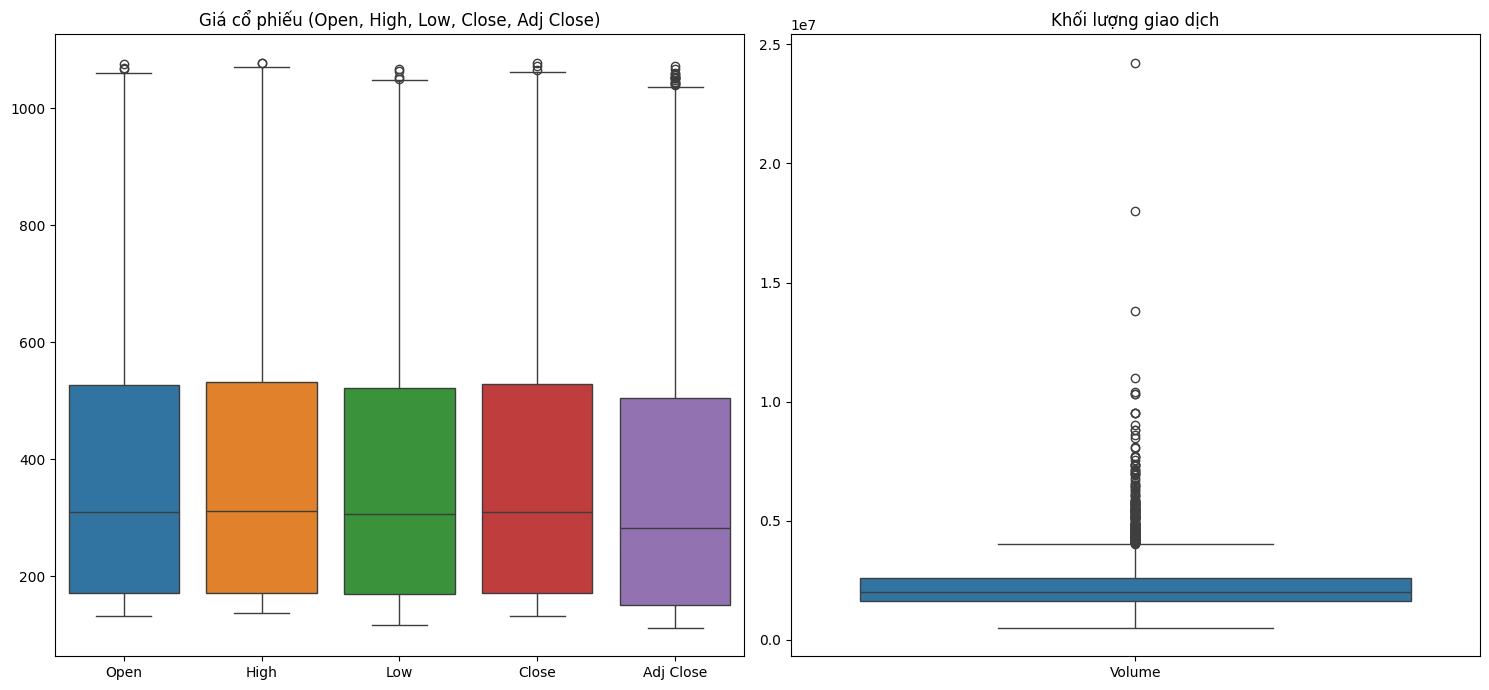


===== Outliers của mã COST =====
           Outliers  Tổng giá trị  % Outliers
Open              3          2702        0.11
High              2          2702        0.07
Low               4          2702        0.15
Close             3          2702        0.11
Adj Close        16          2702        0.59
Volume          182          2702        6.74


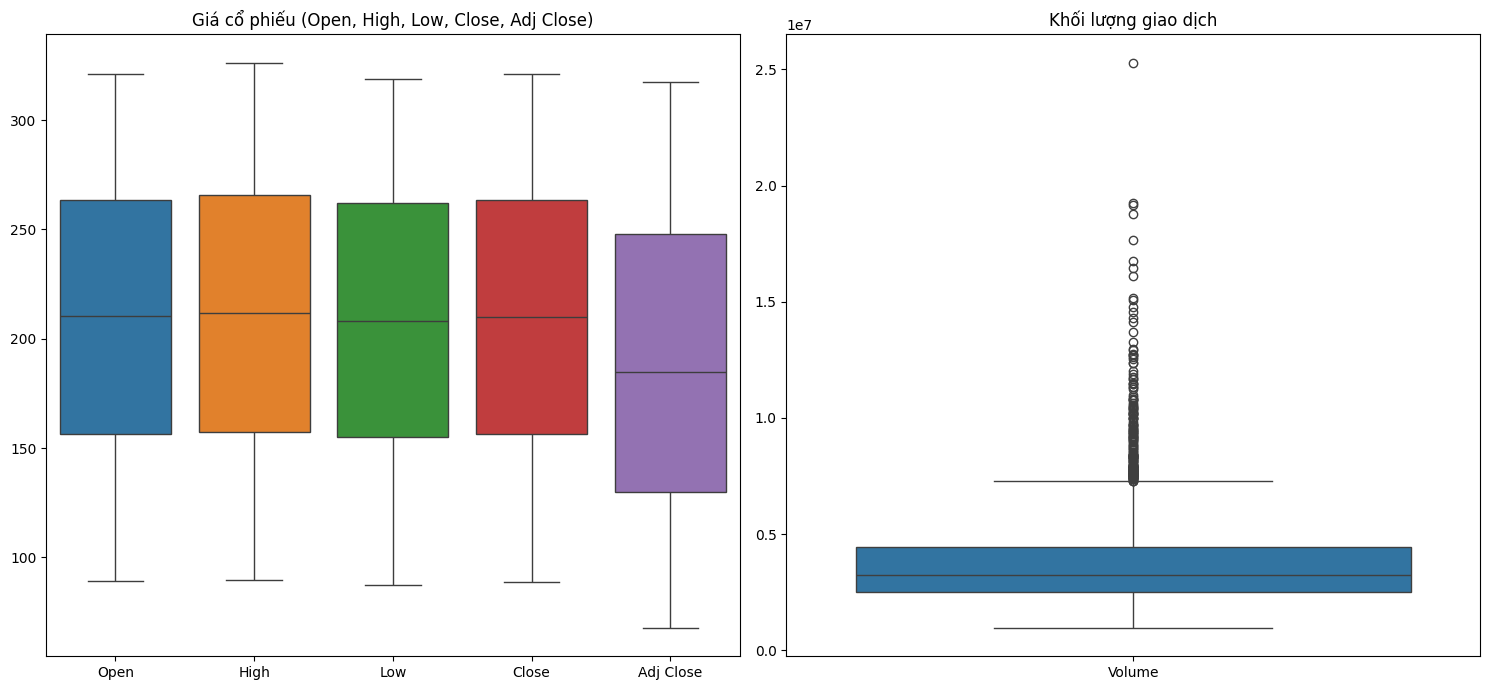


===== Outliers của mã MCD =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          174          2702        6.44


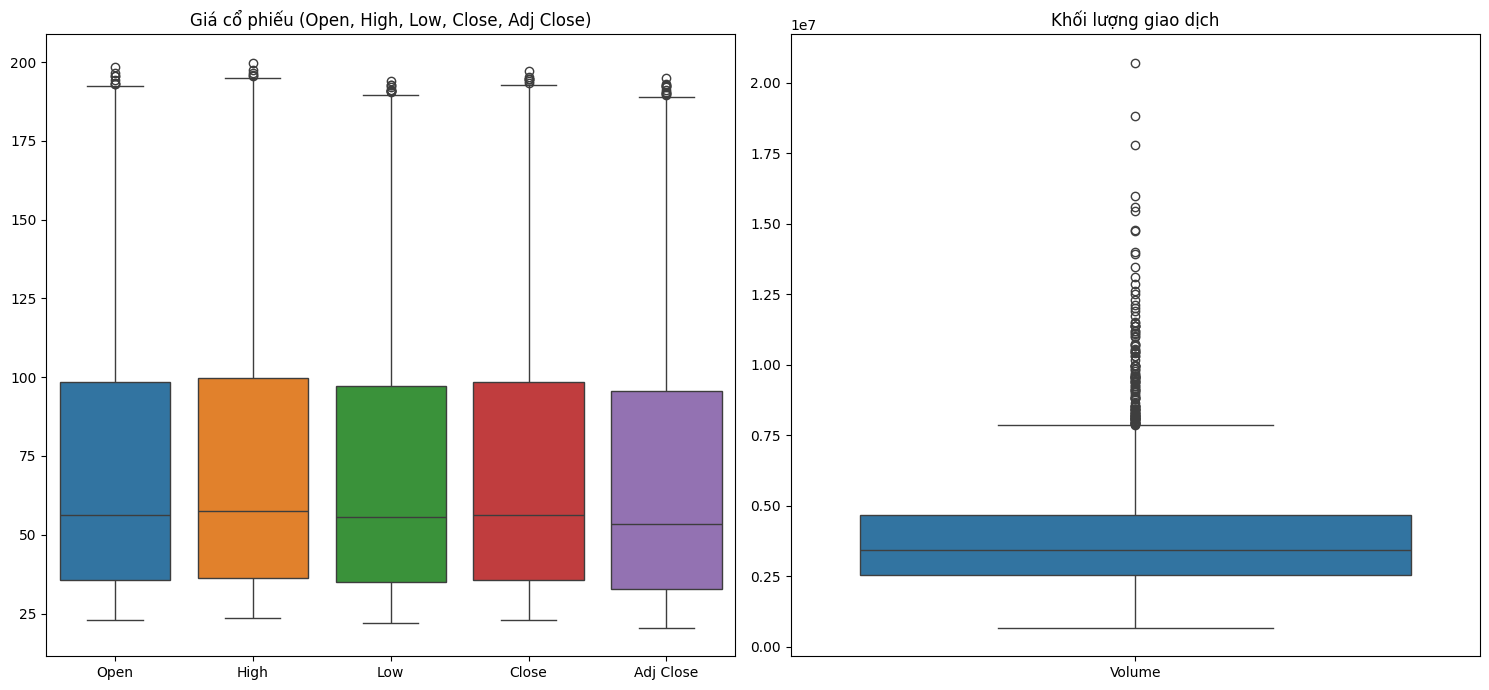


===== Outliers của mã DHI =====
           Outliers  Tổng giá trị  % Outliers
Open              8          2702        0.30
High              5          2702        0.19
Low              10          2702        0.37
Close             7          2702        0.26
Adj Close        12          2702        0.44
Volume          127          2702        4.70


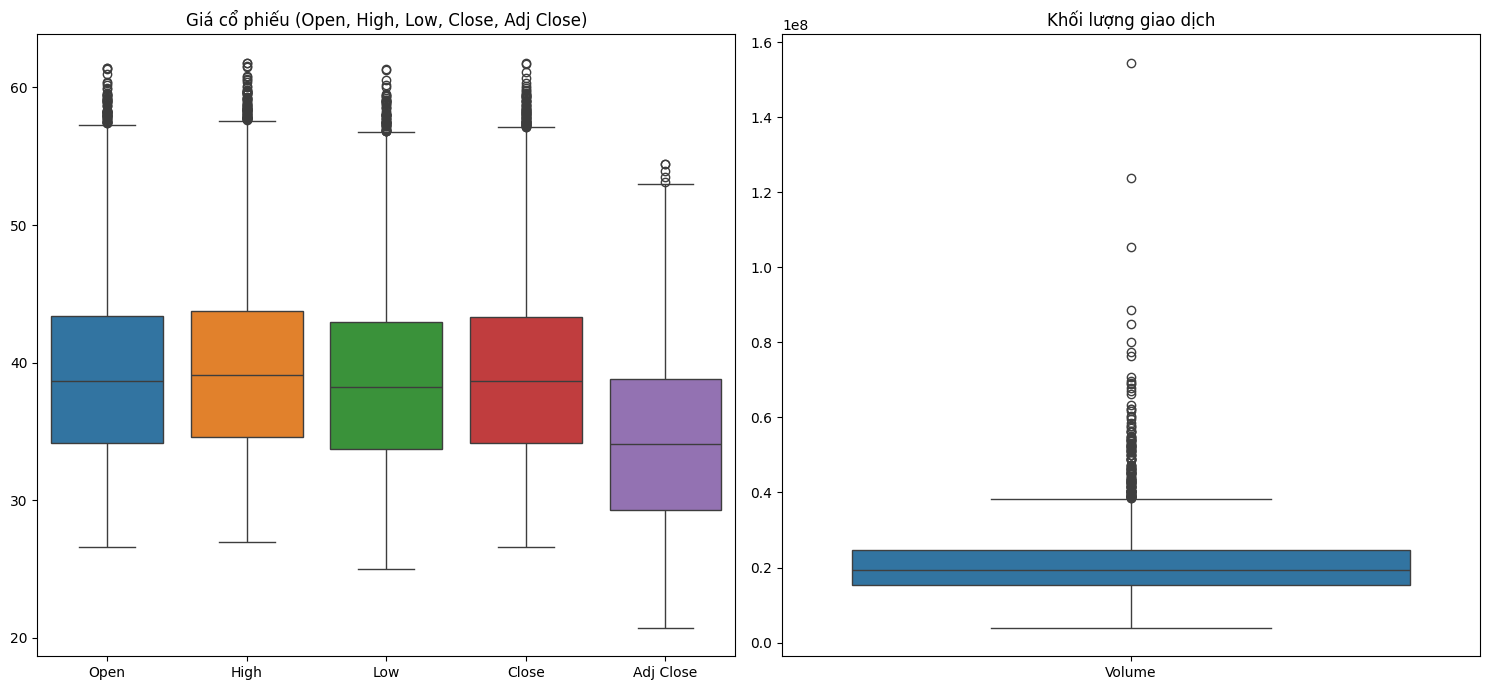


===== Outliers của mã CMCSA =====
           Outliers  Tổng giá trị  % Outliers
Open             61          2702        2.26
High             71          2702        2.63
Low              60          2702        2.22
Close            70          2702        2.59
Adj Close         5          2702        0.19
Volume          141          2702        5.22


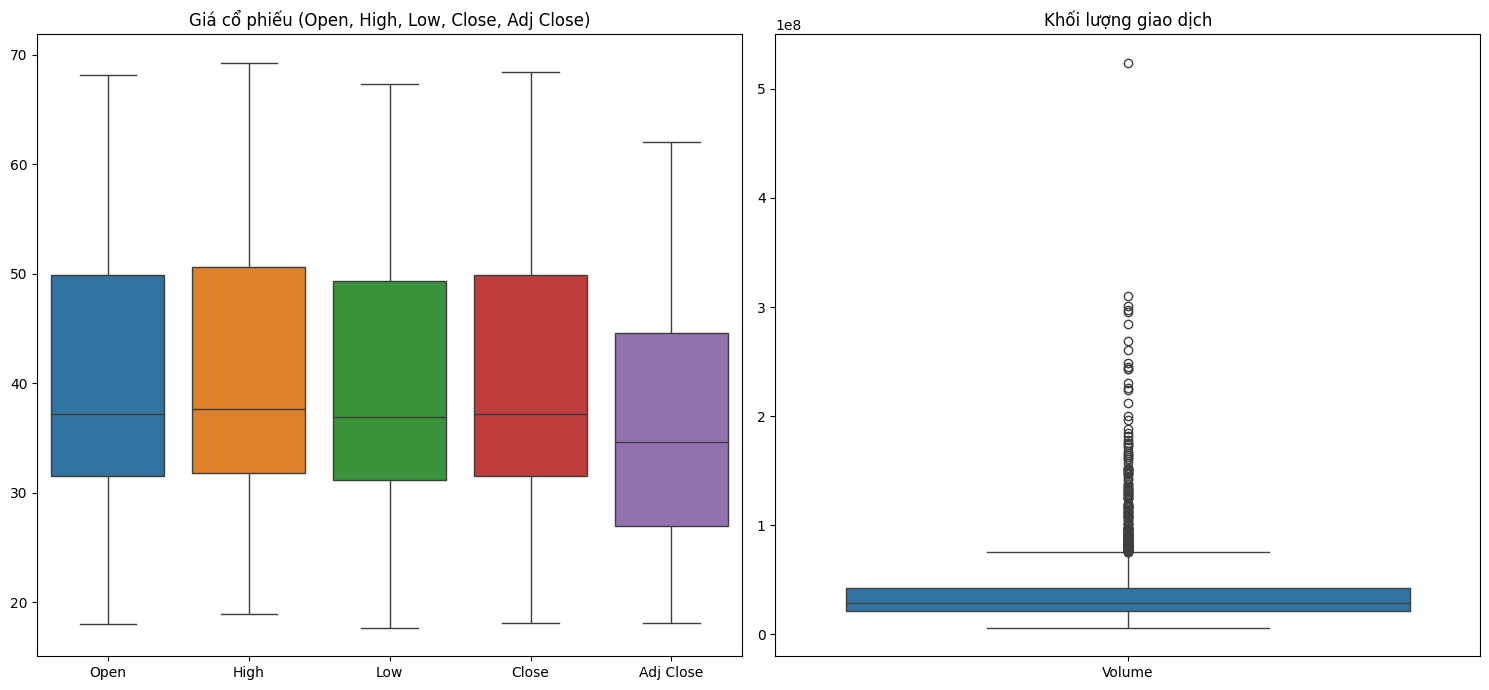


===== Outliers của mã INTC =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702         0.0
High              0          2702         0.0
Low               0          2702         0.0
Close             0          2702         0.0
Adj Close         0          2702         0.0
Volume          200          2702         7.4


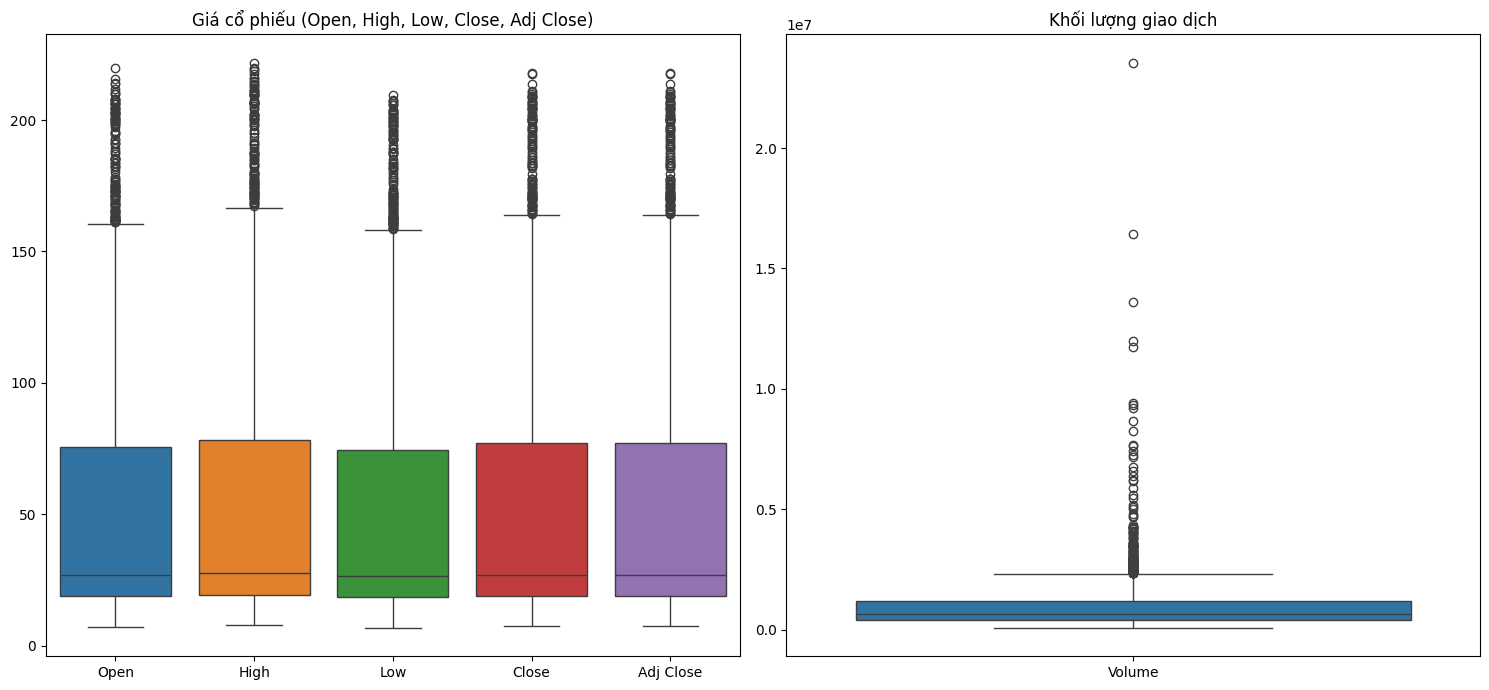


===== Outliers của mã ELF =====
           Outliers  Tổng giá trị  % Outliers
Open            134          2268        5.91
High            119          2268        5.25
Low             126          2268        5.56
Close           113          2268        4.98
Adj Close       113          2268        4.98
Volume          166          2268        7.32


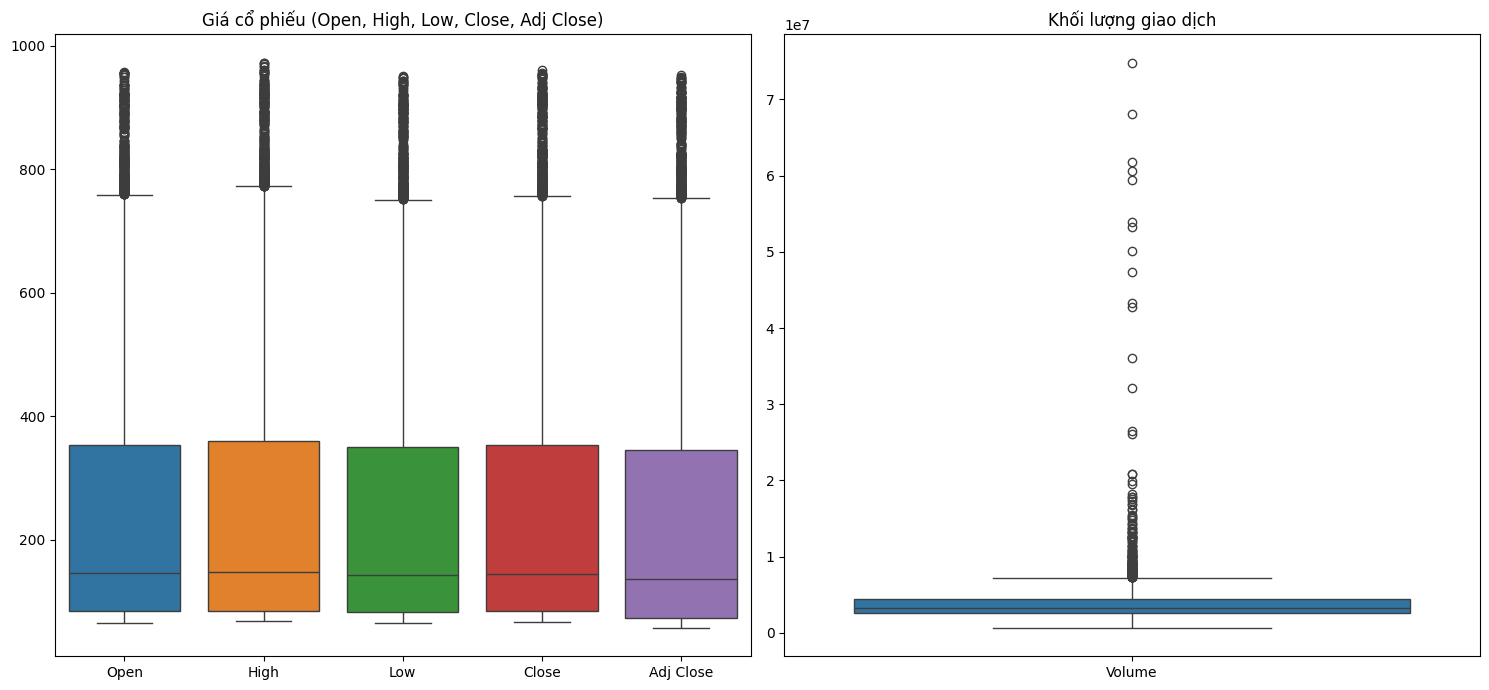


===== Outliers của mã LLY =====
           Outliers  Tổng giá trị  % Outliers
Open            308          2702       11.40
High            297          2702       10.99
Low             300          2702       11.10
Close           315          2702       11.66
Adj Close       307          2702       11.36
Volume          180          2702        6.66


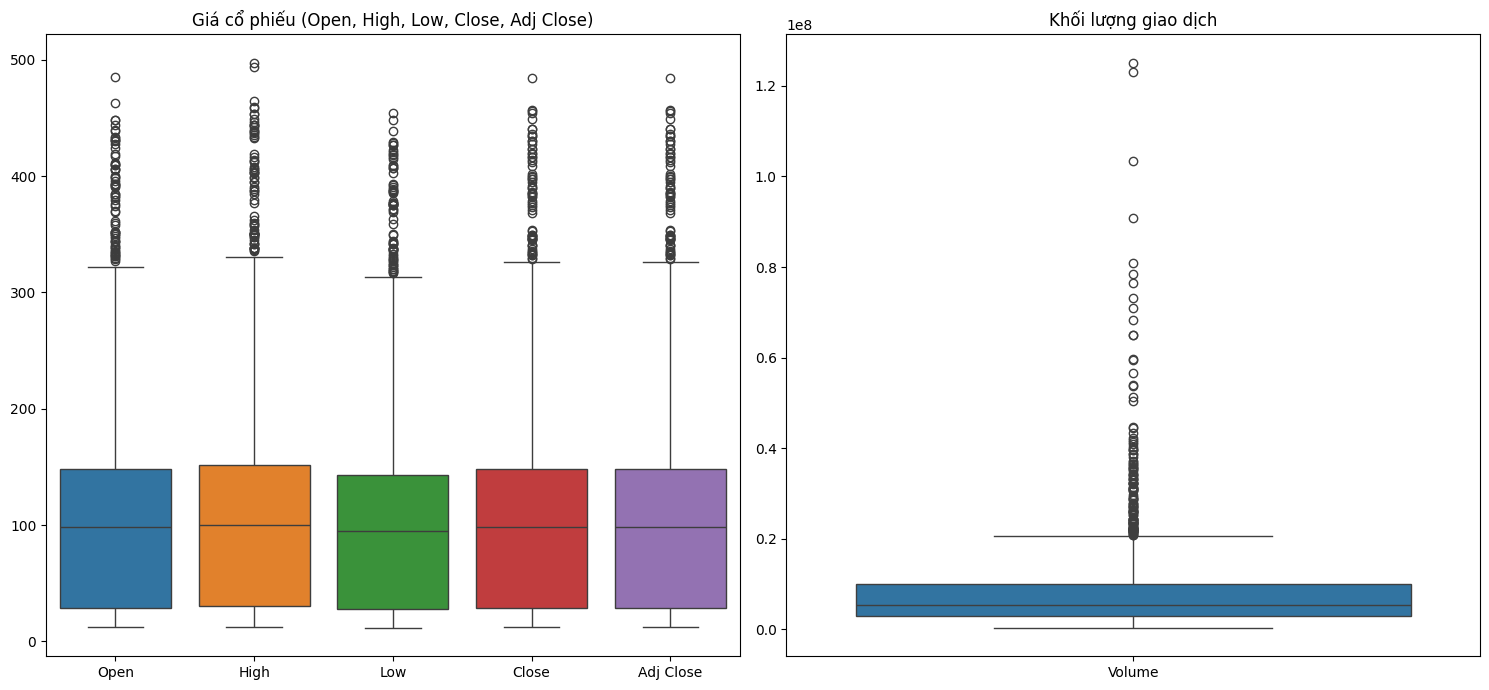


===== Outliers của mã MRNA =====
           Outliers  Tổng giá trị  % Outliers
Open             68          1712        3.97
High             71          1712        4.15
Low              69          1712        4.03
Close            67          1712        3.91
Adj Close        67          1712        3.91
Volume          126          1712        7.36


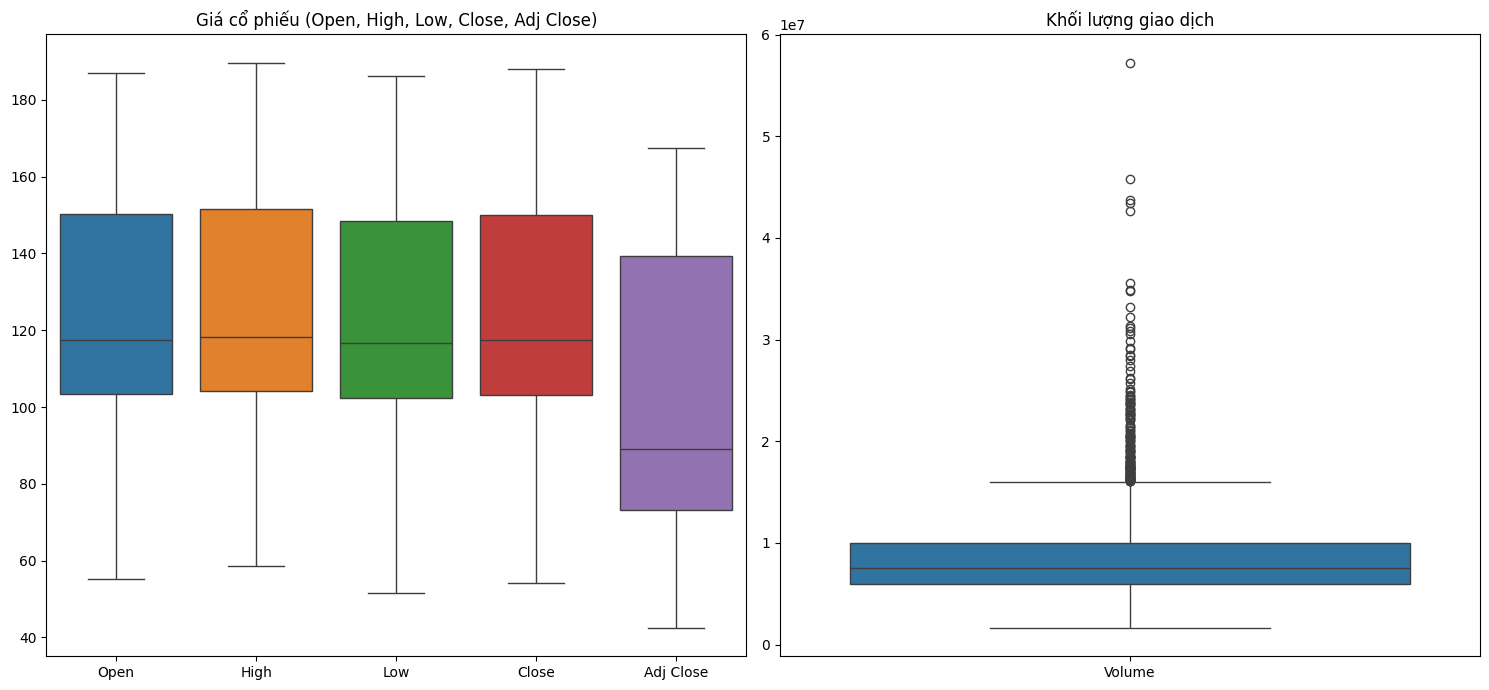


===== Outliers của mã CVX =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          142          2702        5.26


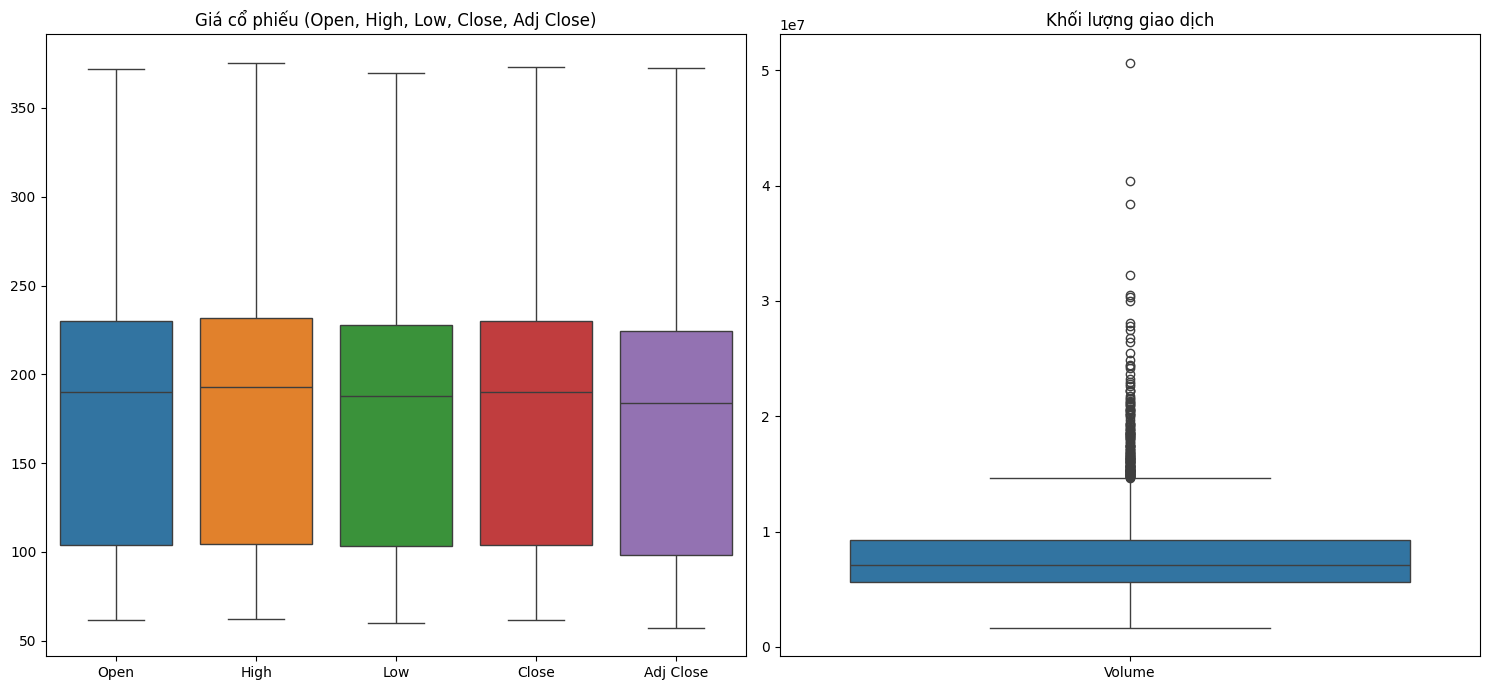


===== Outliers của mã V =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          147          2702        5.44


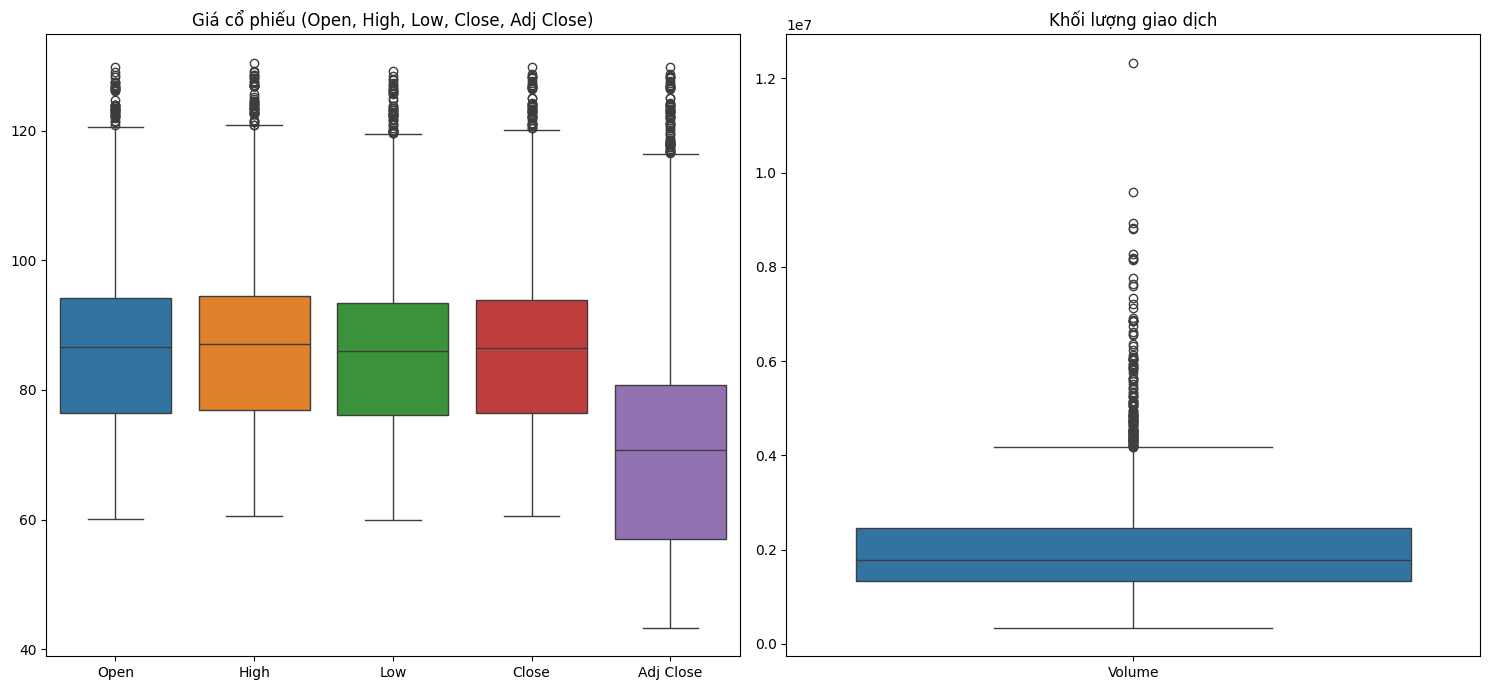


===== Outliers của mã NVS =====
           Outliers  Tổng giá trị  % Outliers
Open             42          2702        1.55
High             47          2702        1.74
Low              50          2702        1.85
Close            48          2702        1.78
Adj Close        73          2702        2.70
Volume          139          2702        5.14


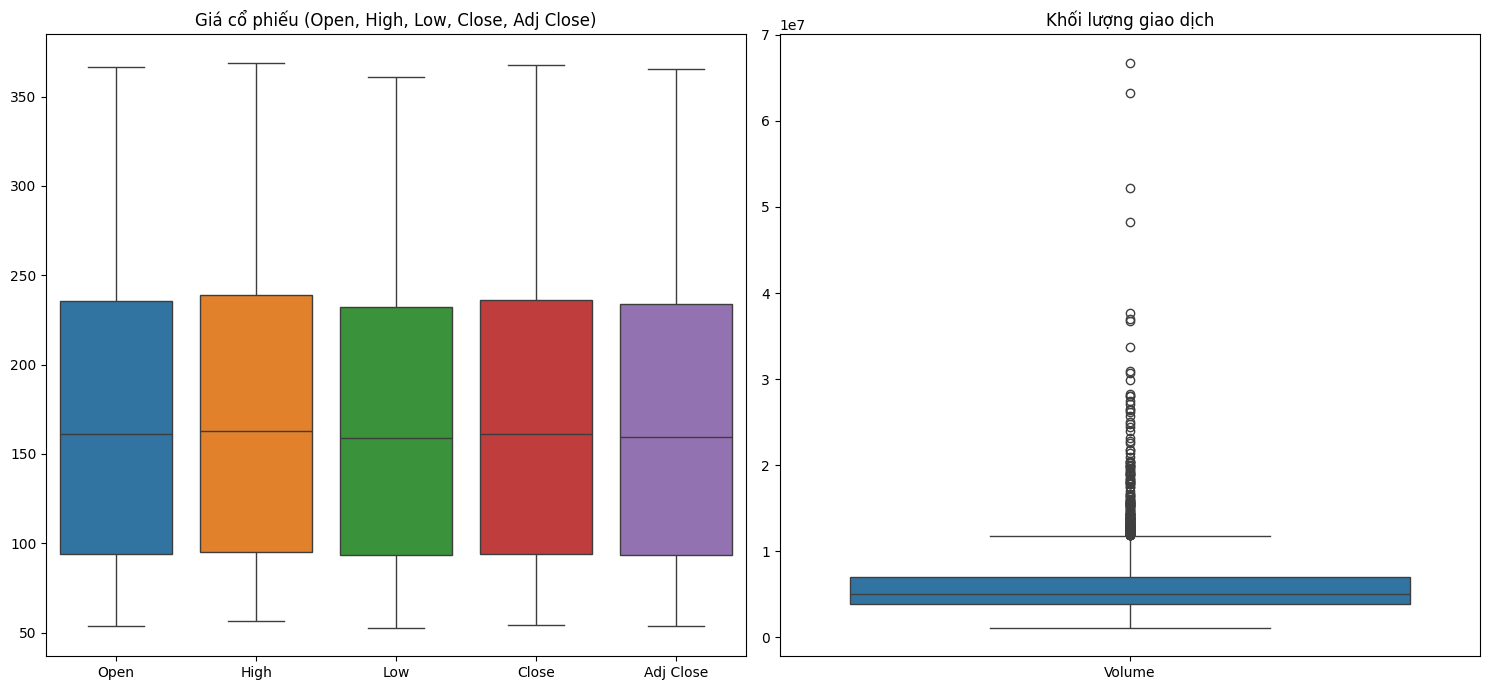


===== Outliers của mã CRM =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          176          2702        6.51


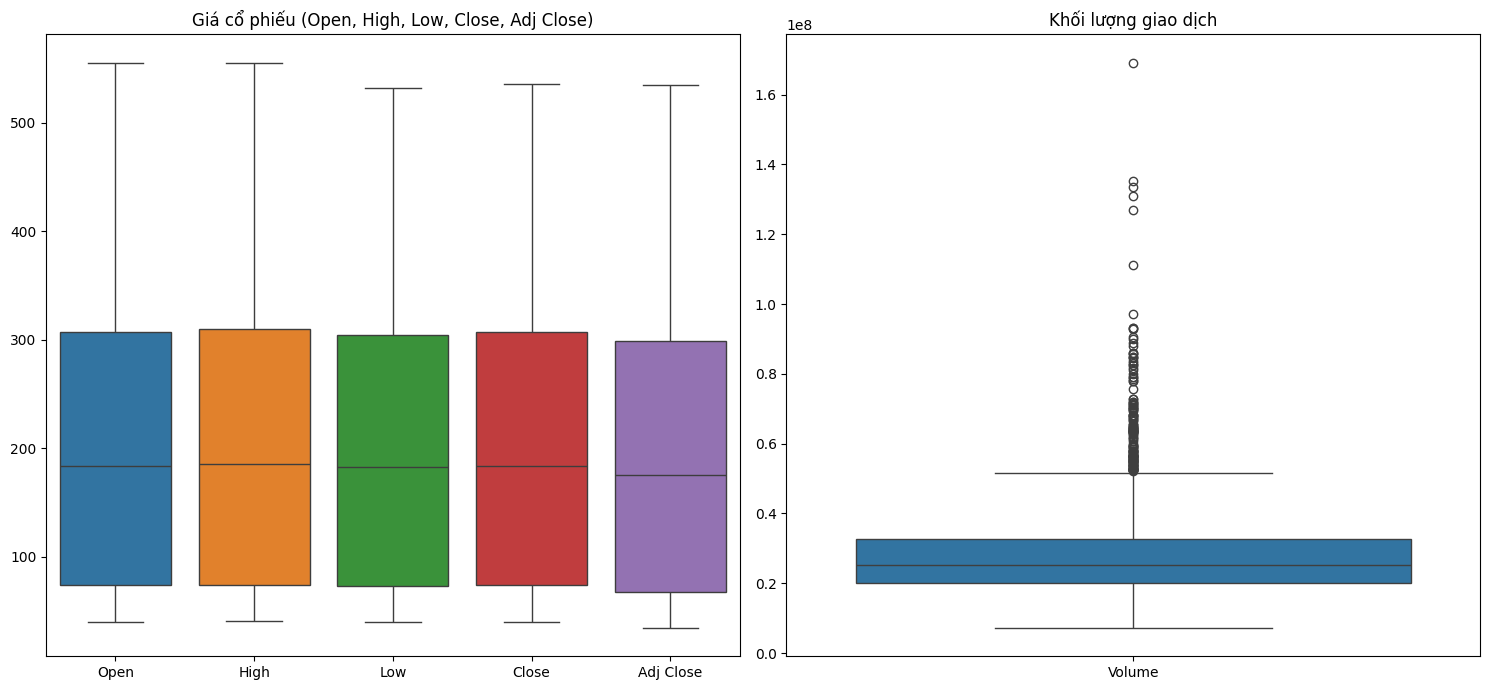


===== Outliers của mã MSFT =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          144          2702        5.33


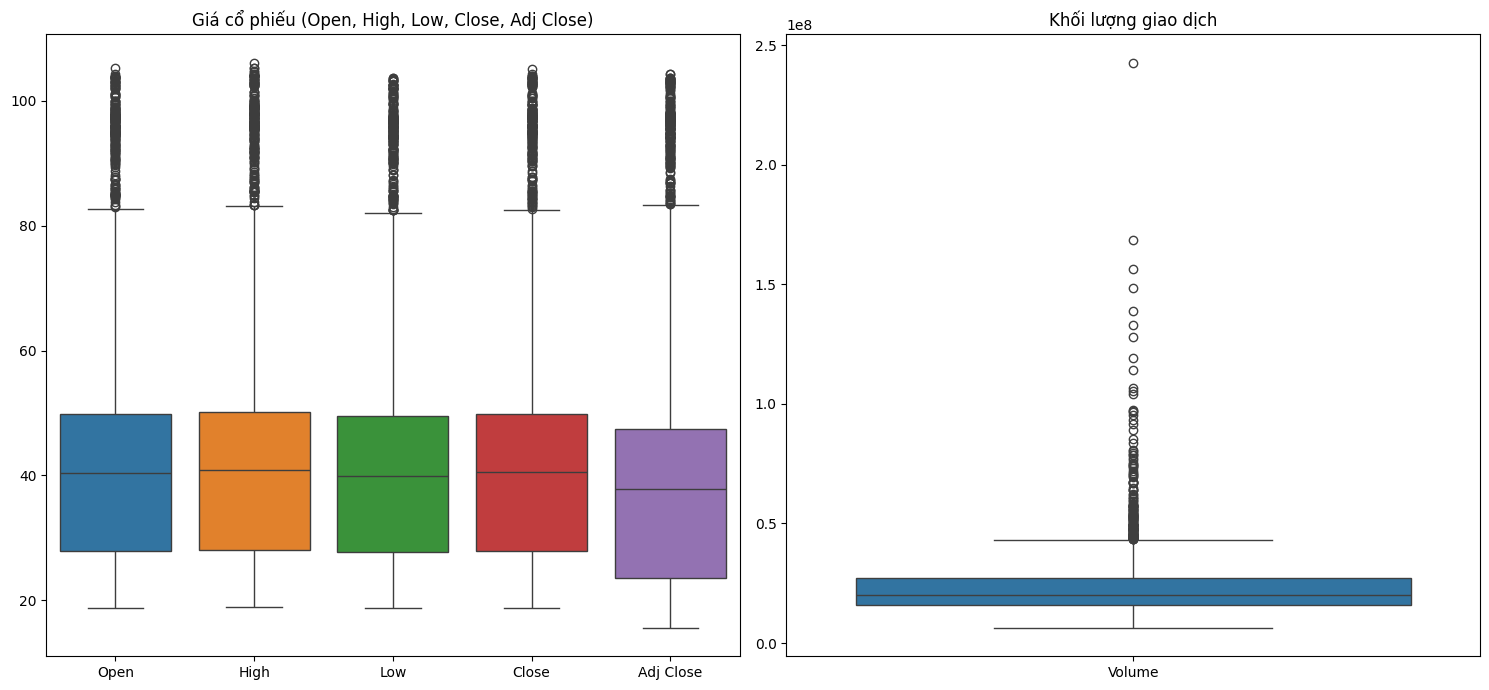


===== Outliers của mã WMT =====
           Outliers  Tổng giá trị  % Outliers
Open            225          2702        8.33
High            228          2702        8.44
Low             225          2702        8.33
Close           227          2702        8.40
Adj Close       218          2702        8.07
Volume          163          2702        6.03


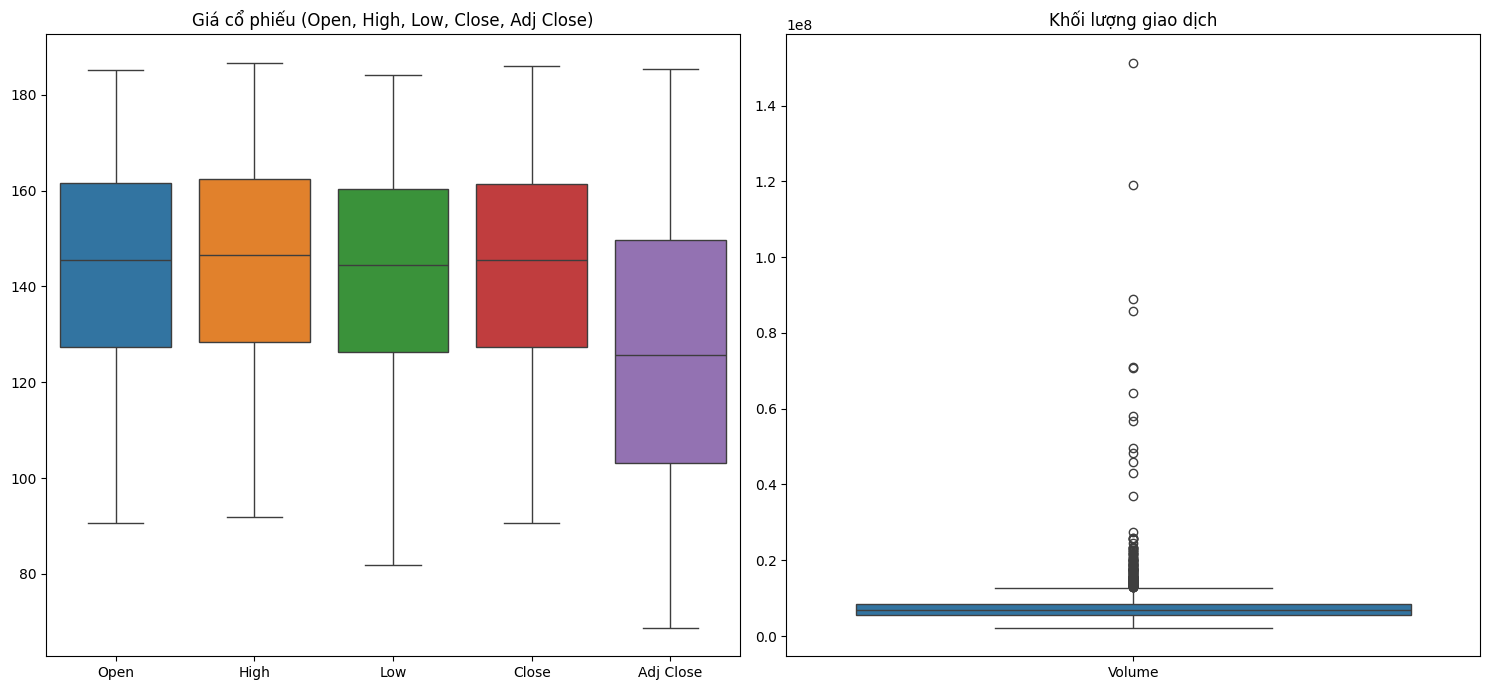


===== Outliers của mã JNJ =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          148          2702        5.48


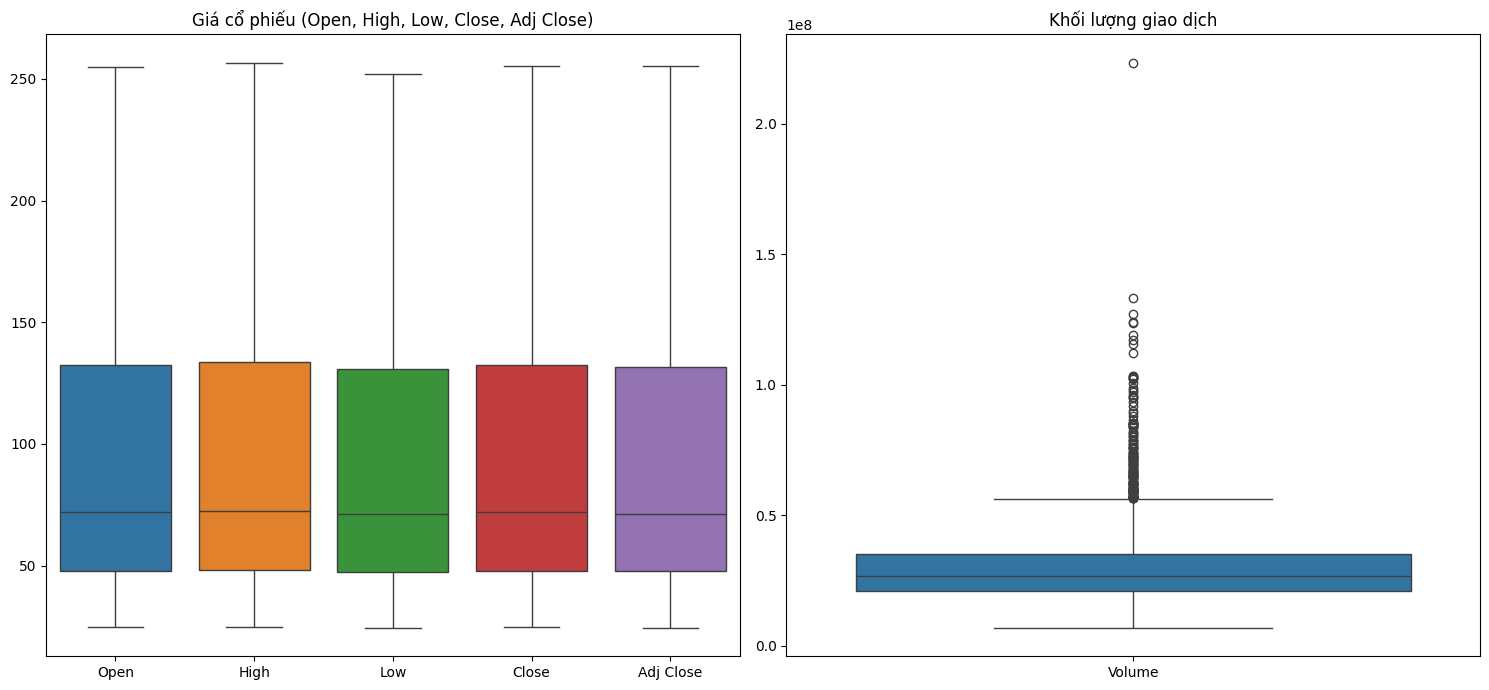


===== Outliers của mã GOOG =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702         0.0
High              0          2702         0.0
Low               0          2702         0.0
Close             0          2702         0.0
Adj Close         0          2702         0.0
Volume          146          2702         5.4


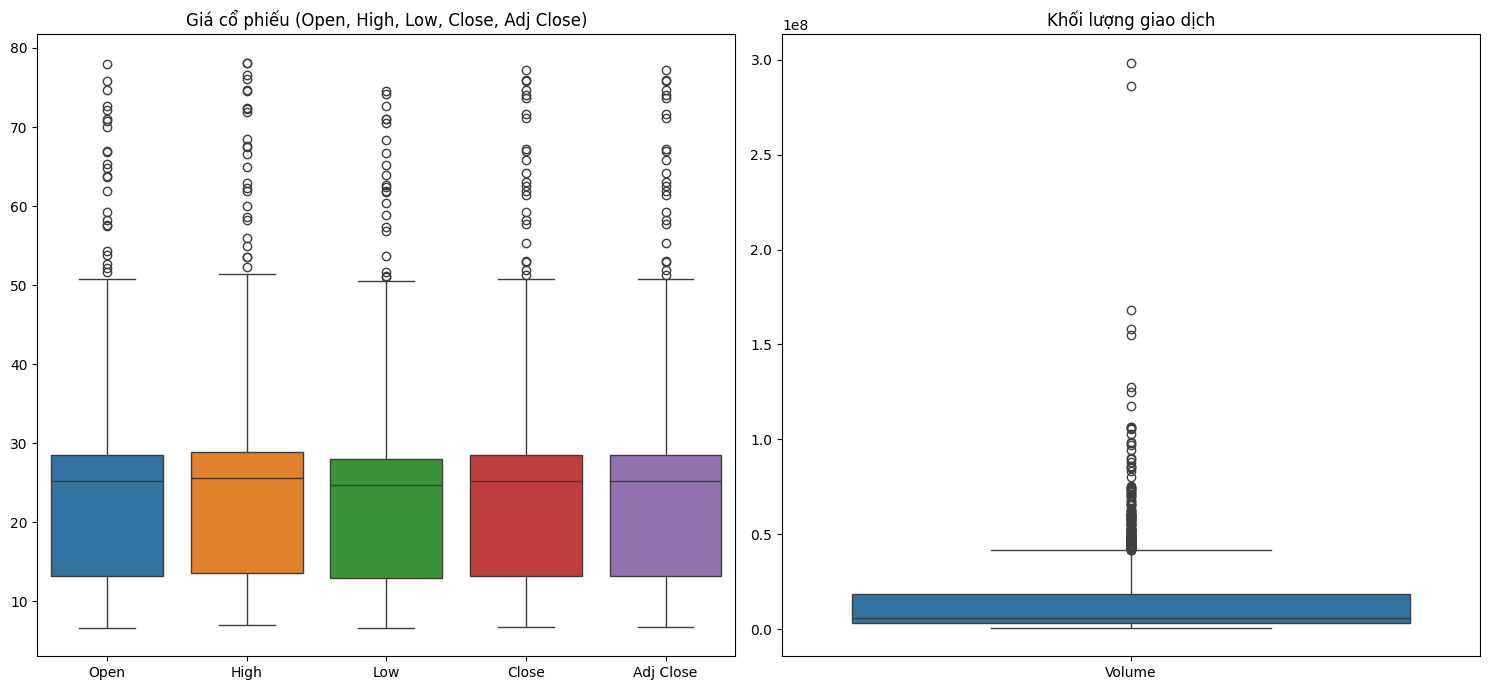


===== Outliers của mã WBD =====
           Outliers  Tổng giá trị  % Outliers
Open             24          2702        0.89
High             25          2702        0.93
Low              22          2702        0.81
Close            24          2702        0.89
Adj Close        24          2702        0.89
Volume          167          2702        6.18


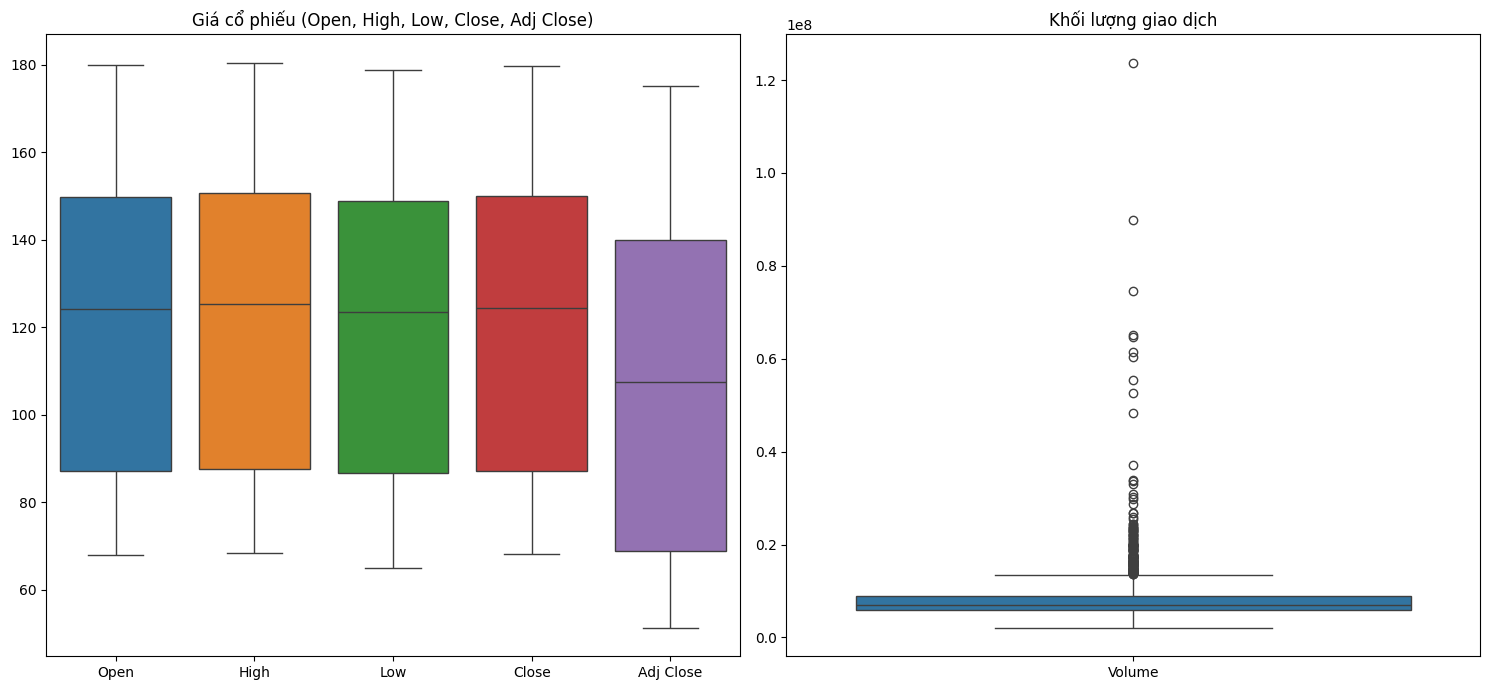


===== Outliers của mã PG =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          170          2702        6.29


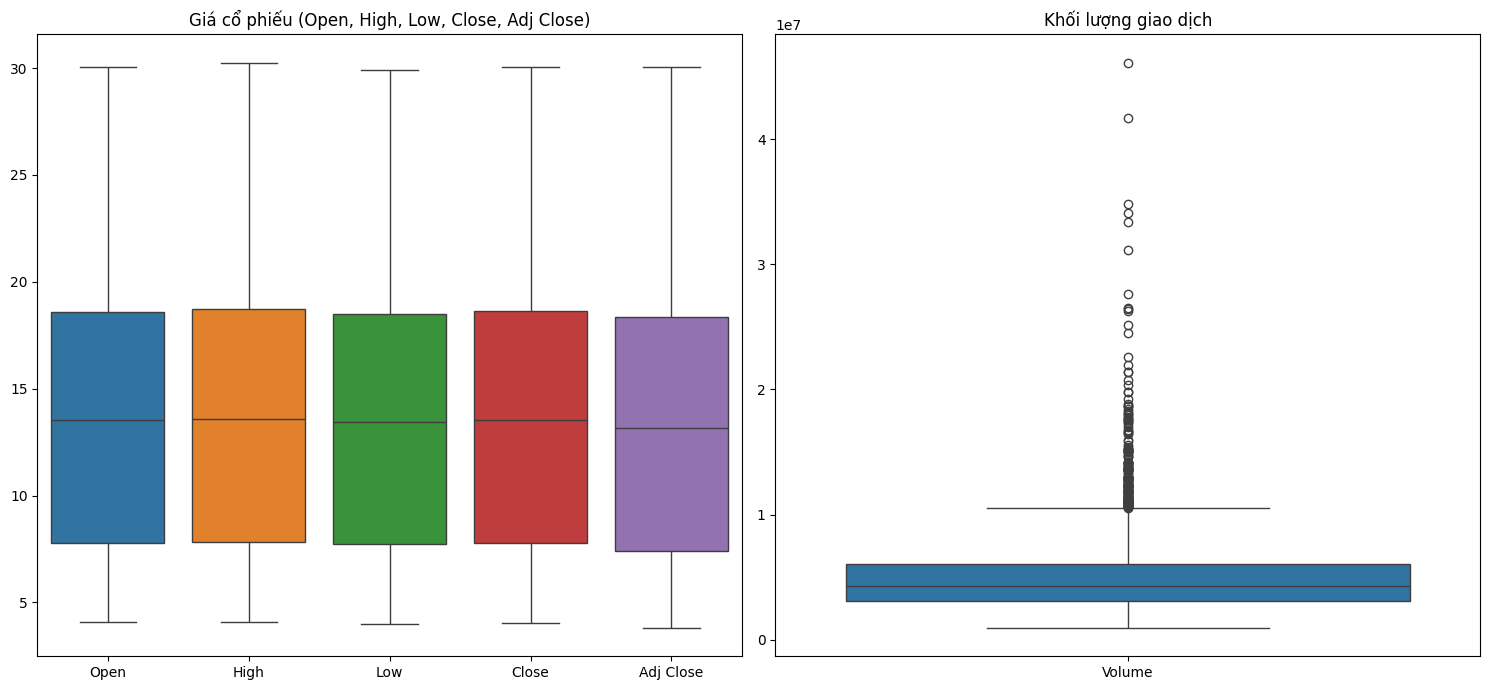


===== Outliers của mã SONY =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          190          2702        7.03


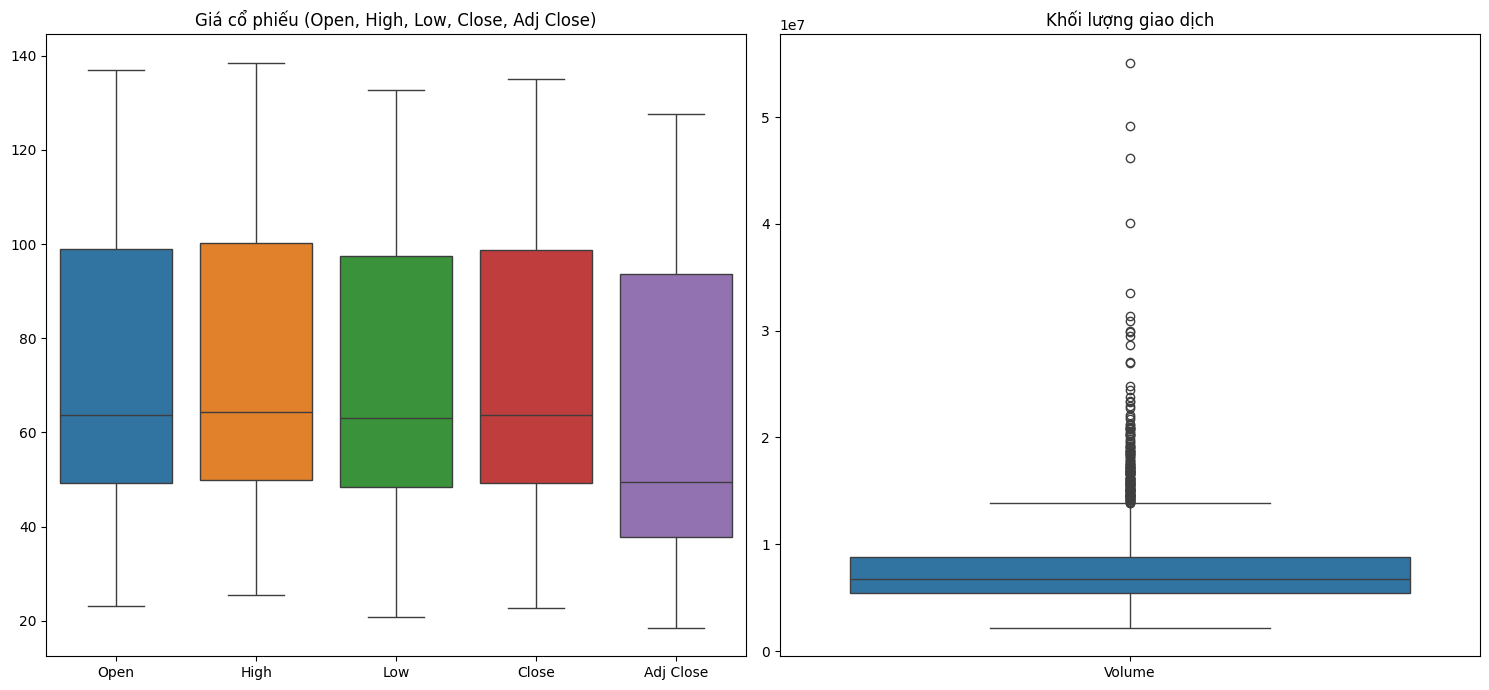


===== Outliers của mã COP =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          147          2702        5.44


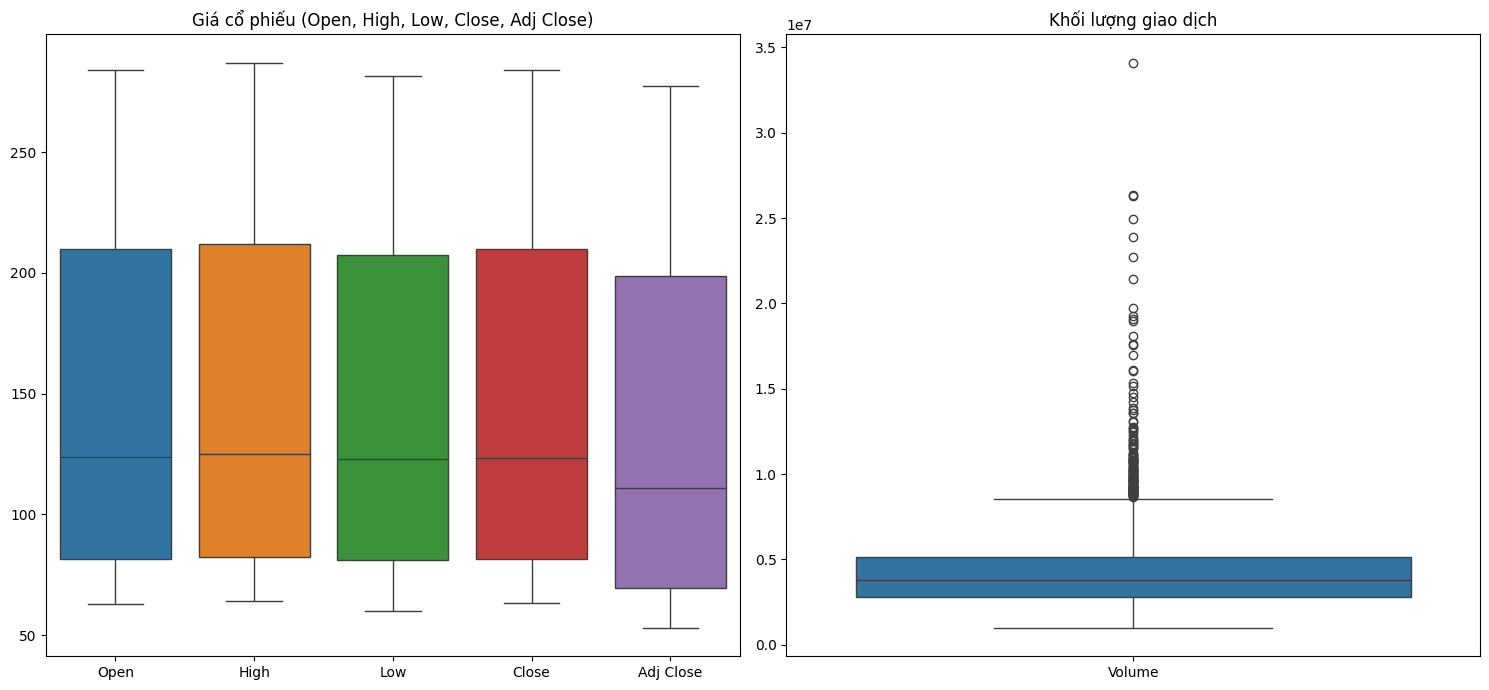


===== Outliers của mã LOW =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702         0.0
High              0          2702         0.0
Low               0          2702         0.0
Close             0          2702         0.0
Adj Close         0          2702         0.0
Volume          135          2702         5.0


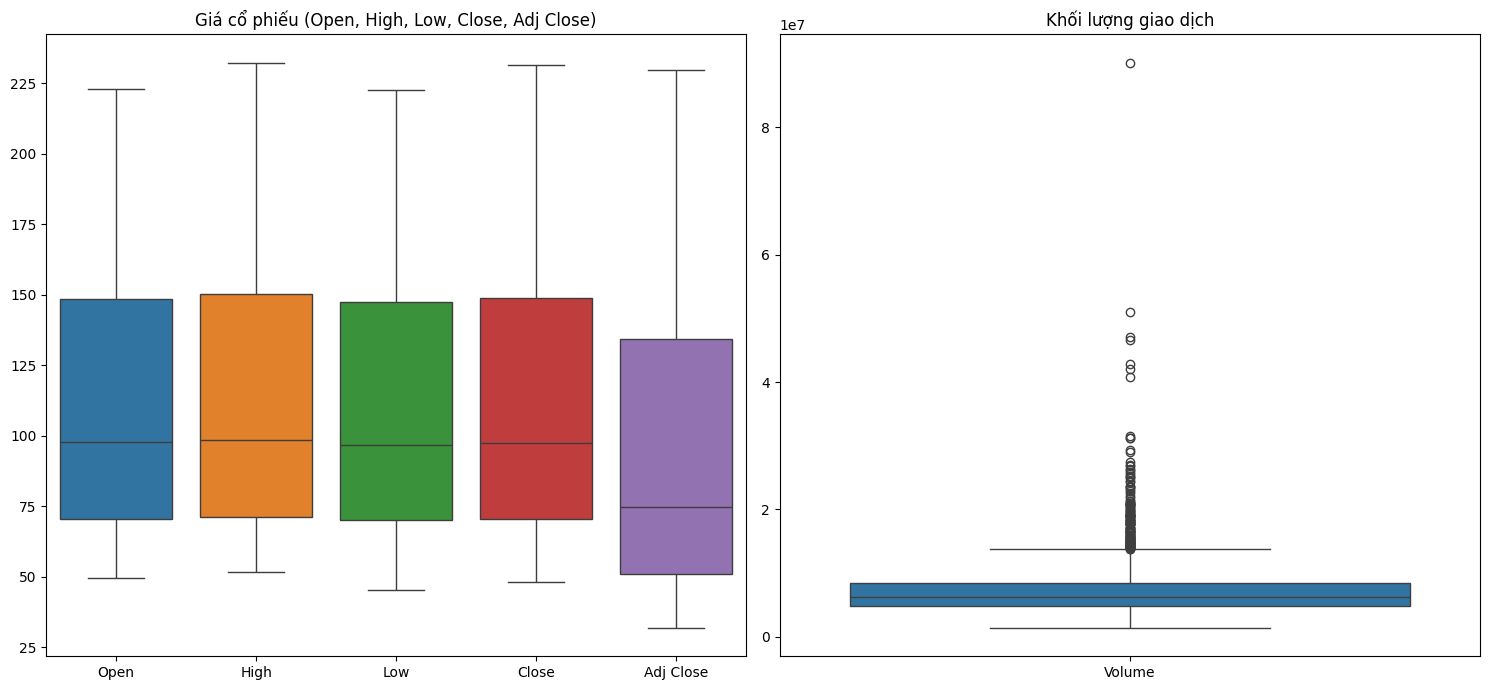


===== Outliers của mã ABBV =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          145          2702        5.37


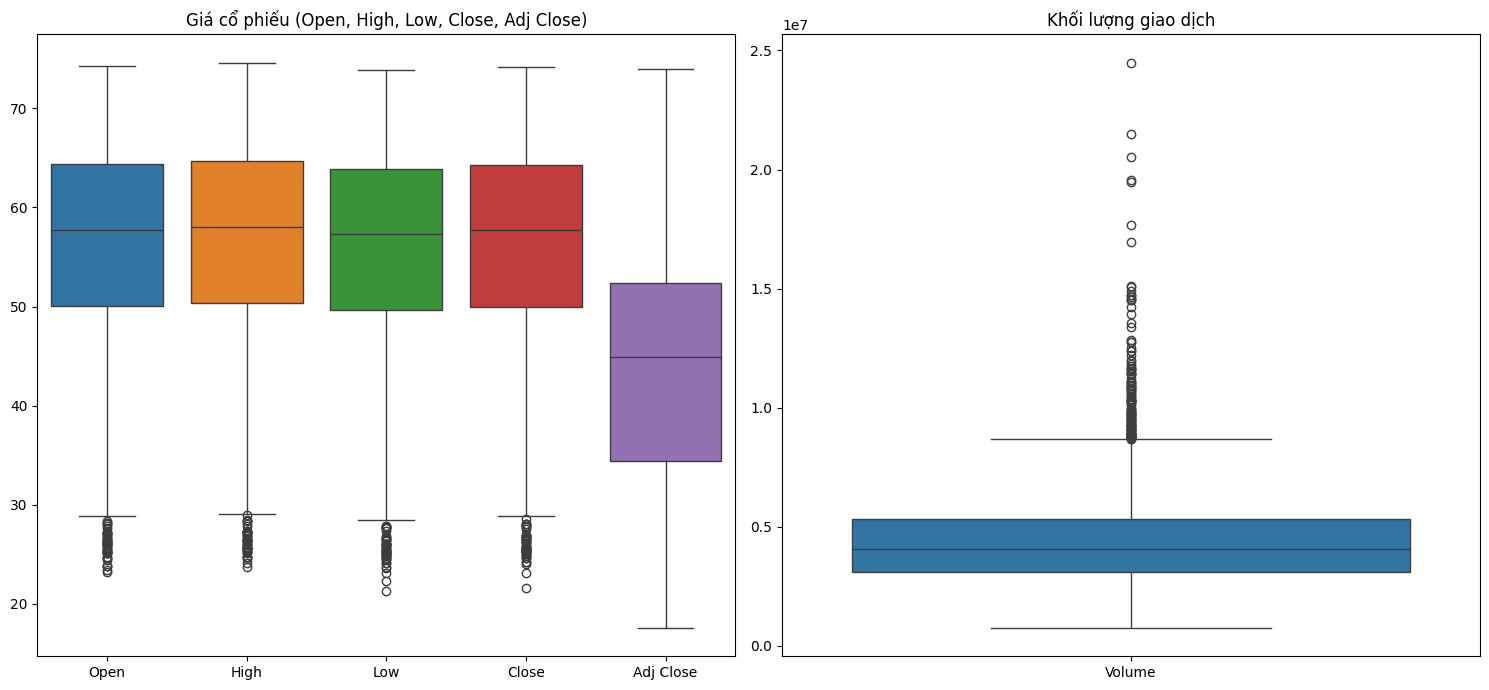


===== Outliers của mã SHEL =====
           Outliers  Tổng giá trị  % Outliers
Open             48          2702        1.78
High             49          2702        1.81
Low              50          2702        1.85
Close            50          2702        1.85
Adj Close         0          2702        0.00
Volume          122          2702        4.52


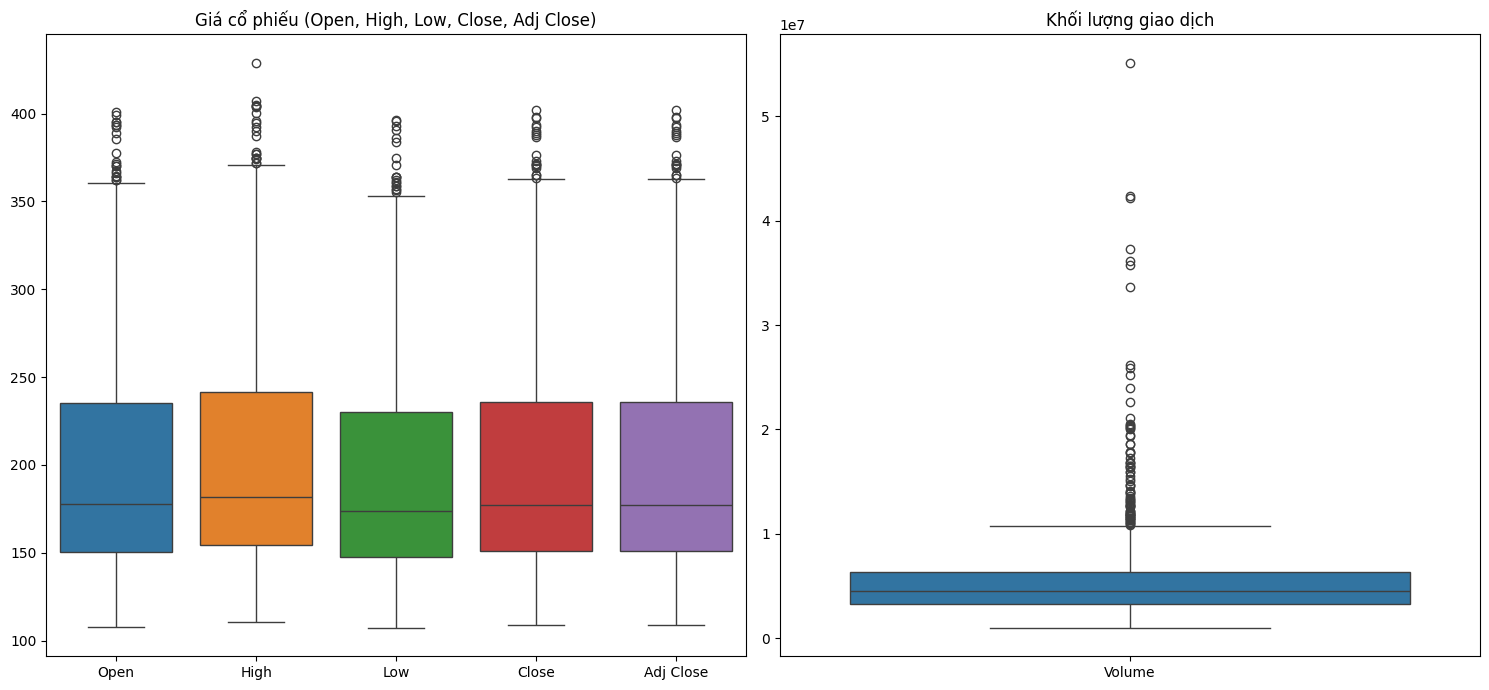


===== Outliers của mã SNOW =====
           Outliers  Tổng giá trị  % Outliers
Open             21          1266        1.66
High             21          1266        1.66
Low              19          1266        1.50
Close            19          1266        1.50
Adj Close        19          1266        1.50
Volume           80          1266        6.32


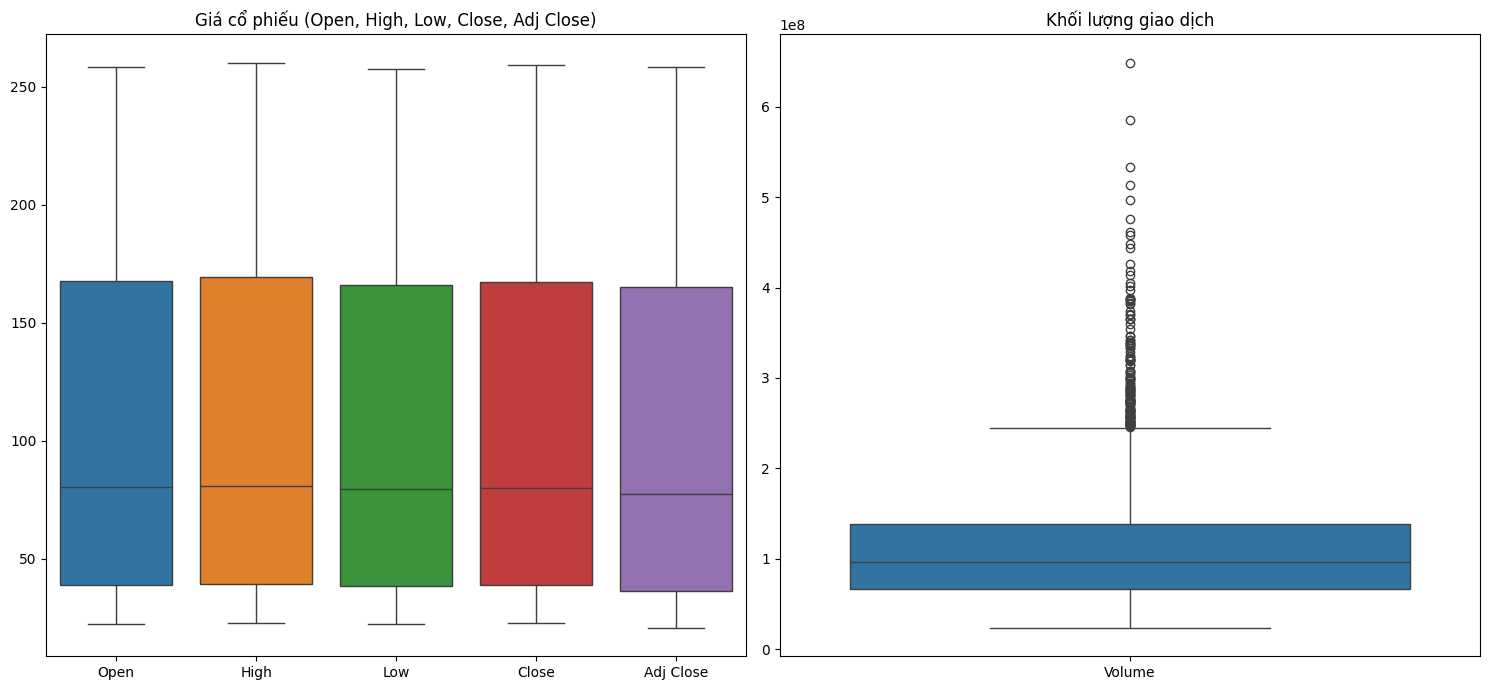


===== Outliers của mã AAPL =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          138          2702        5.11


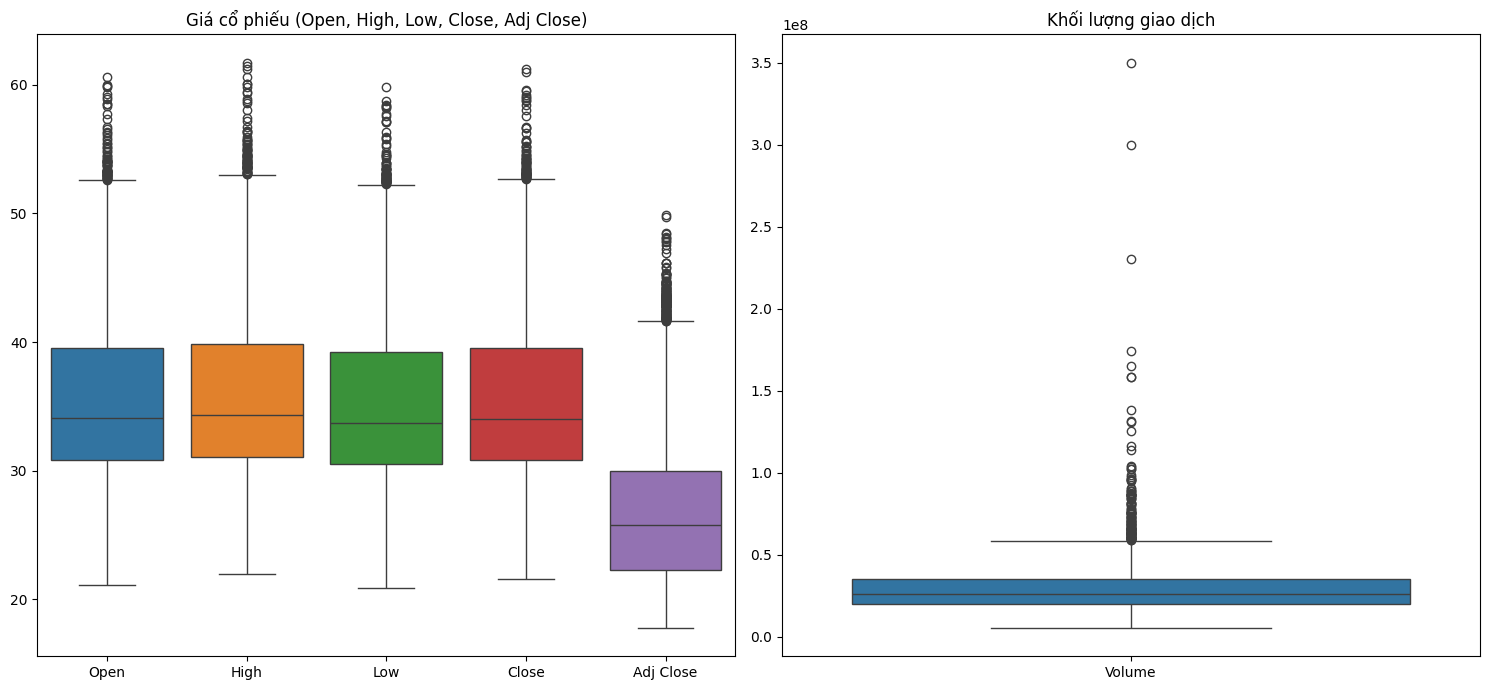


===== Outliers của mã PFE =====
           Outliers  Tổng giá trị  % Outliers
Open             75          2702        2.78
High             82          2702        3.03
Low              68          2702        2.52
Close            75          2702        2.78
Adj Close       153          2702        5.66
Volume          133          2702        4.92


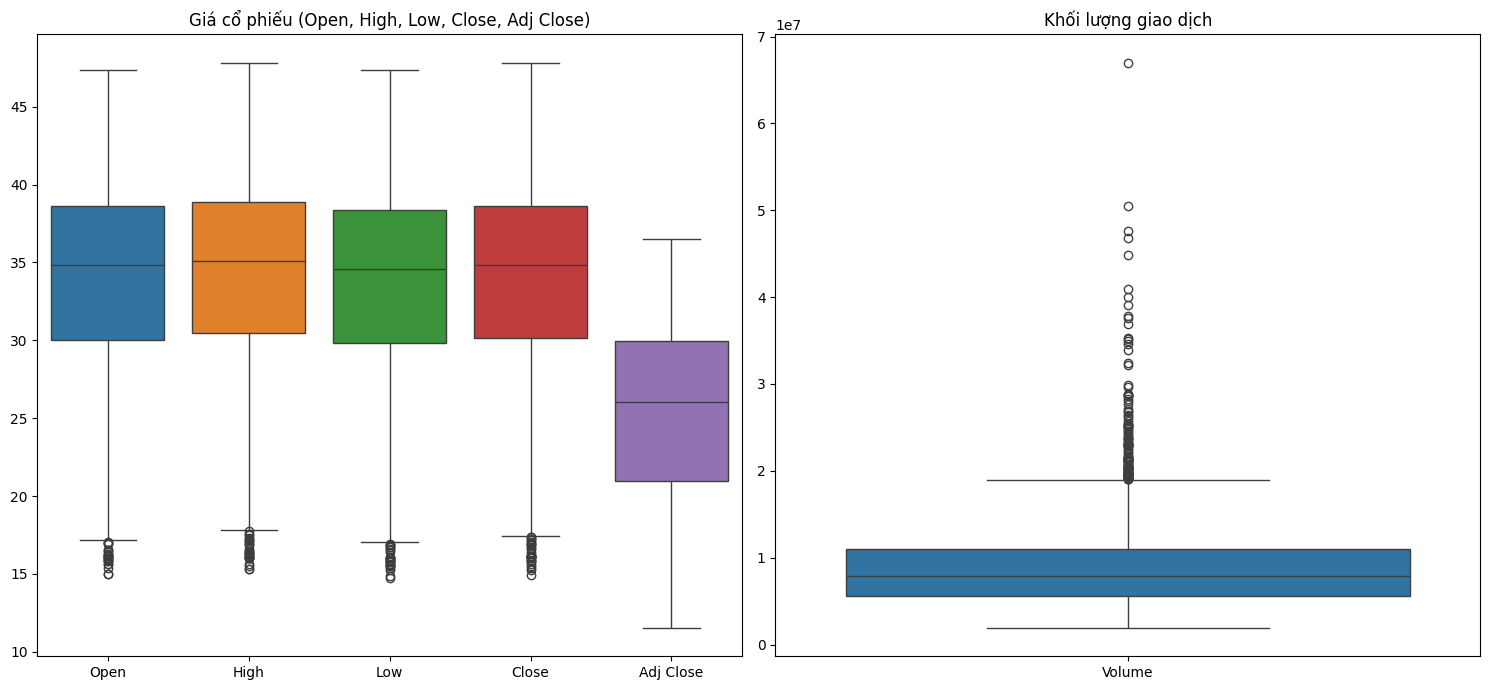


===== Outliers của mã BP =====
           Outliers  Tổng giá trị  % Outliers
Open             24          2702        0.89
High             27          2702        1.00
Low              27          2702        1.00
Close            29          2702        1.07
Adj Close         0          2702        0.00
Volume          128          2702        4.74


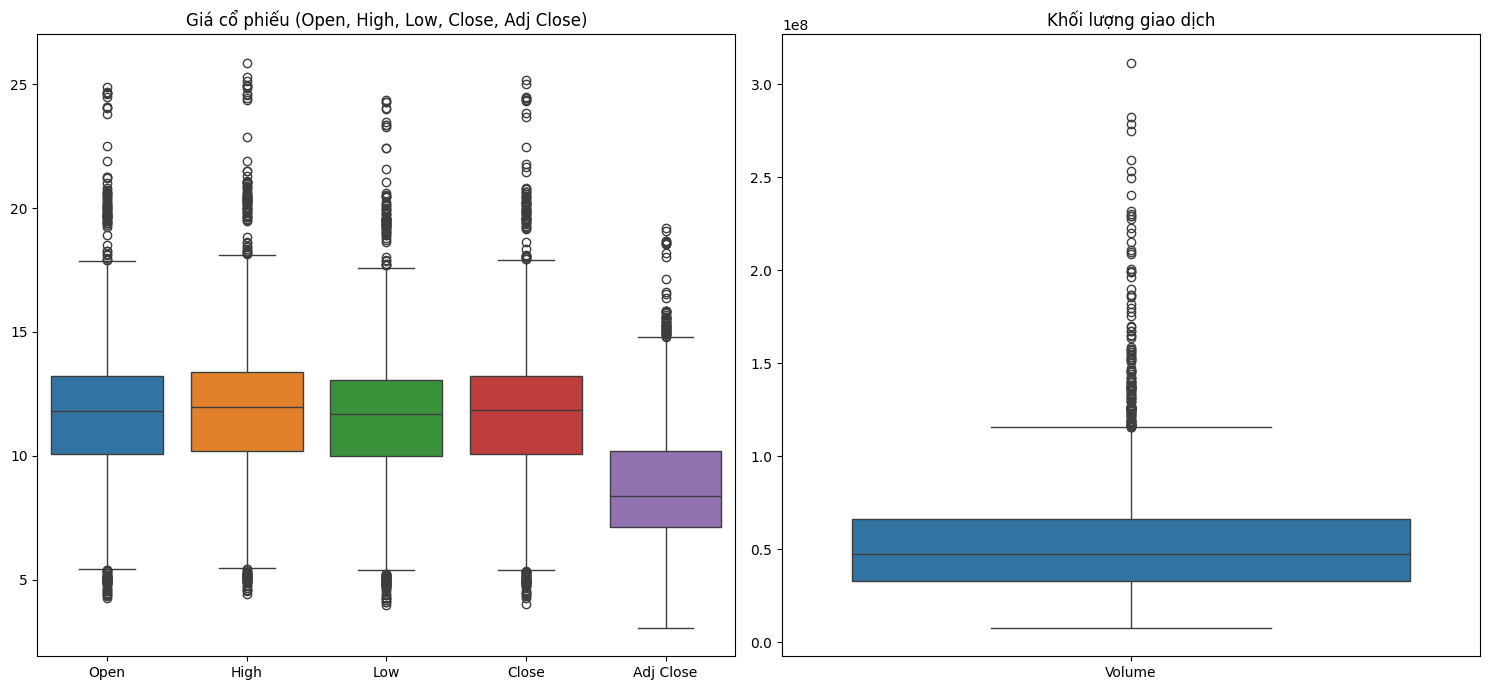


===== Outliers của mã F =====
           Outliers  Tổng giá trị  % Outliers
Open            115          2702        4.26
High            114          2702        4.22
Low             118          2702        4.37
Close           117          2702        4.33
Adj Close        55          2702        2.04
Volume          141          2702        5.22


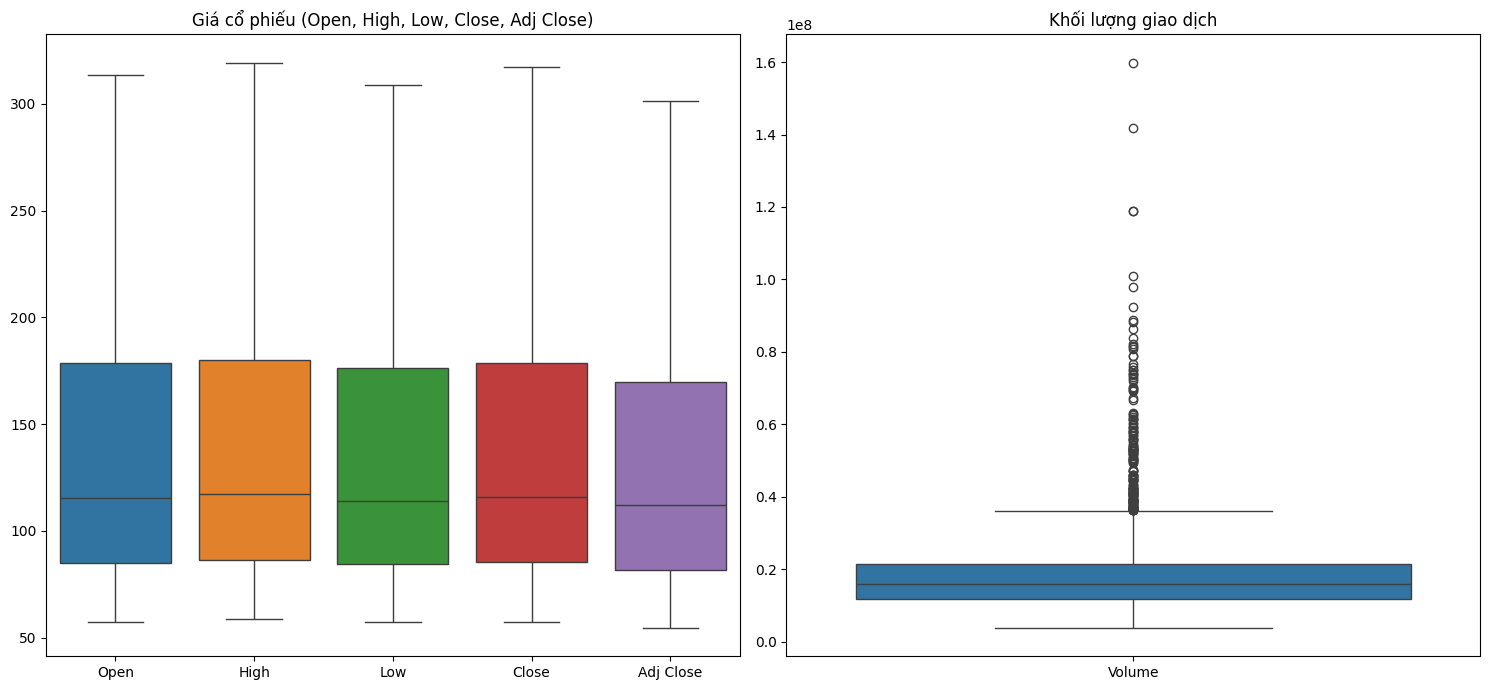


===== Outliers của mã BABA =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          168          2702        6.22


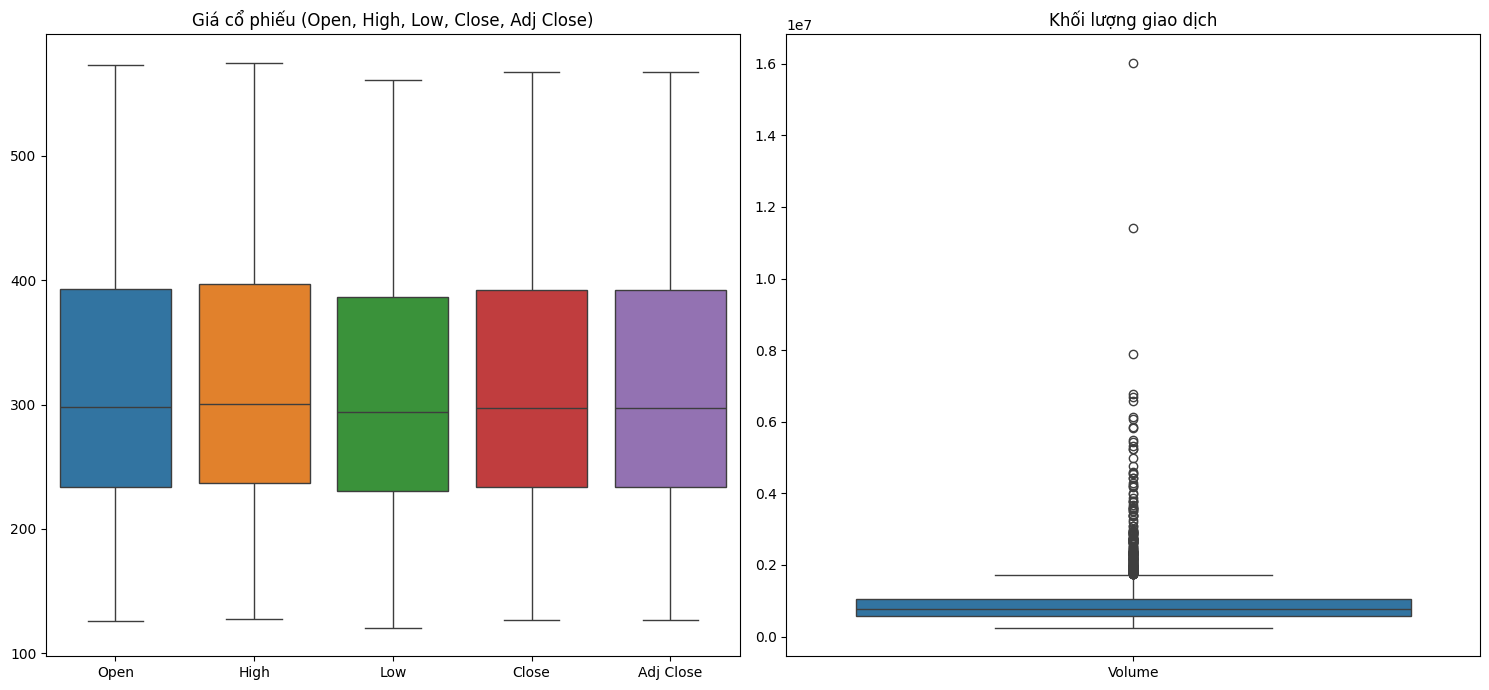


===== Outliers của mã ULTA =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          196          2702        7.25


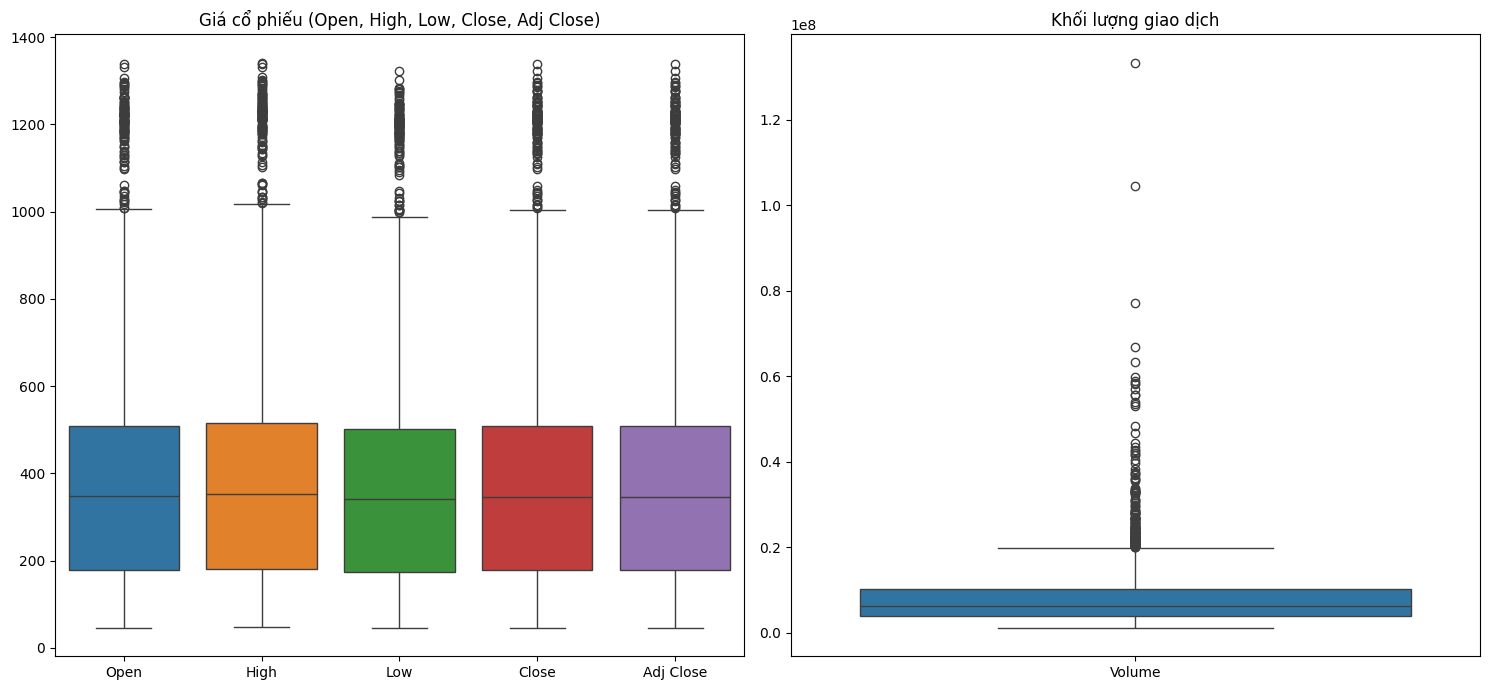


===== Outliers của mã NFLX =====
           Outliers  Tổng giá trị  % Outliers
Open            122          2702        4.52
High            123          2702        4.55
Low             123          2702        4.55
Close           123          2702        4.55
Adj Close       123          2702        4.55
Volume          169          2702        6.25


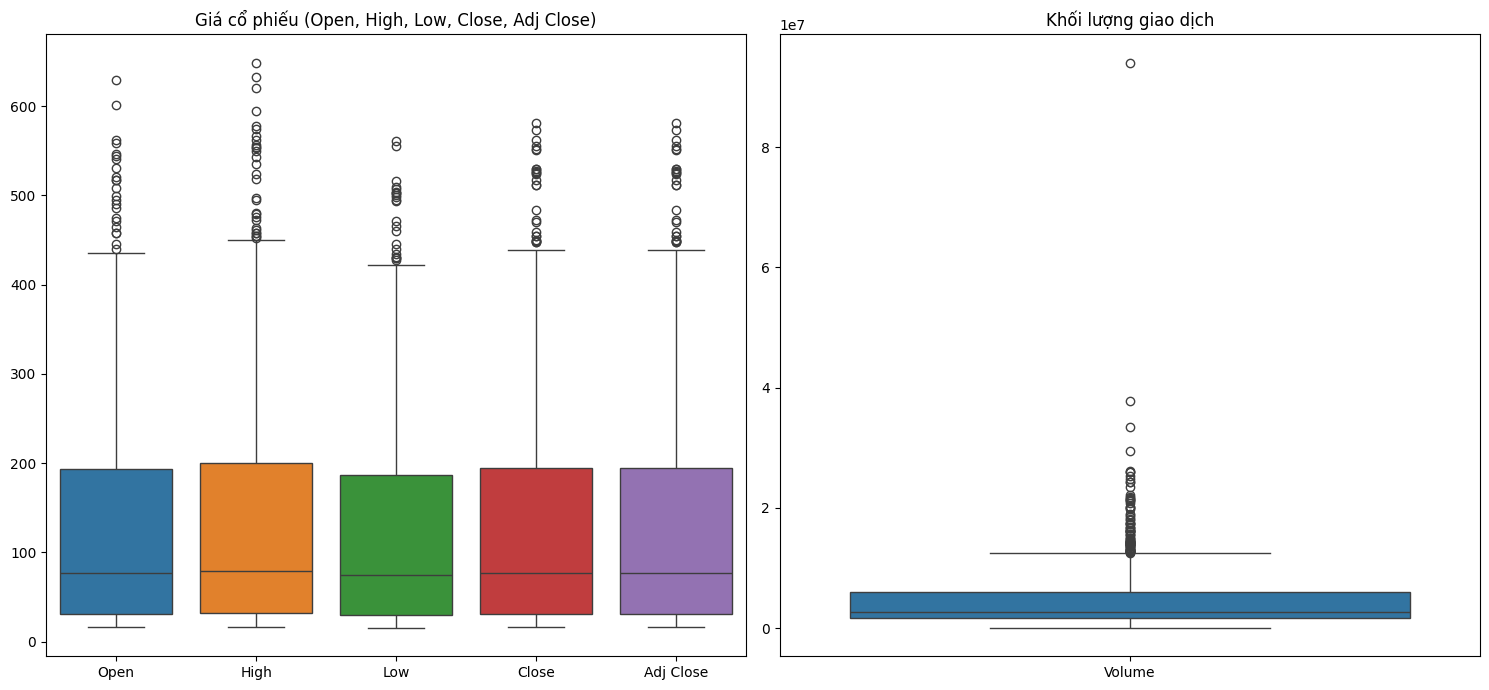


===== Outliers của mã LCID =====
           Outliers  Tổng giá trị  % Outliers
Open             23          1264        1.82
High             29          1264        2.29
Low              22          1264        1.74
Close            26          1264        2.06
Adj Close        26          1264        2.06
Volume           82          1264        6.49


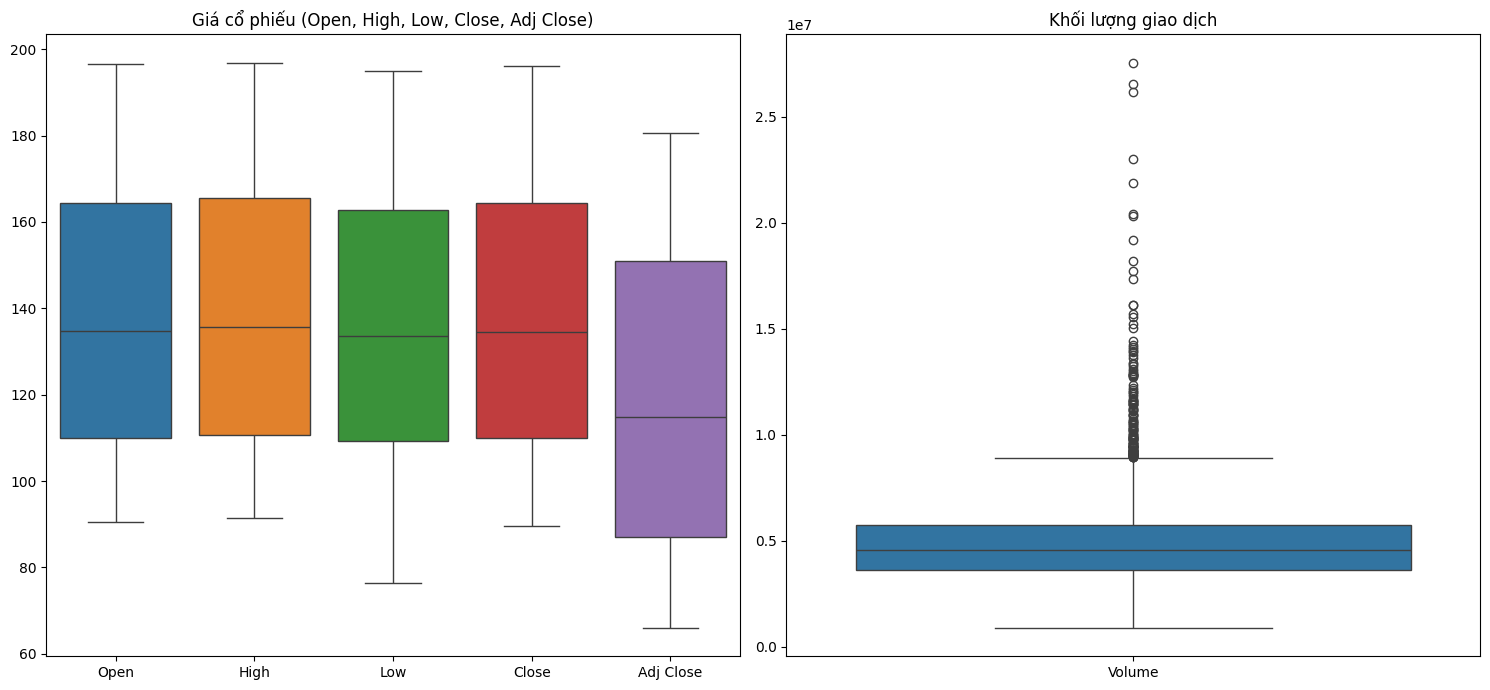


===== Outliers của mã PEP =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702         0.0
High              0          2702         0.0
Low               0          2702         0.0
Close             0          2702         0.0
Adj Close         0          2702         0.0
Volume          135          2702         5.0


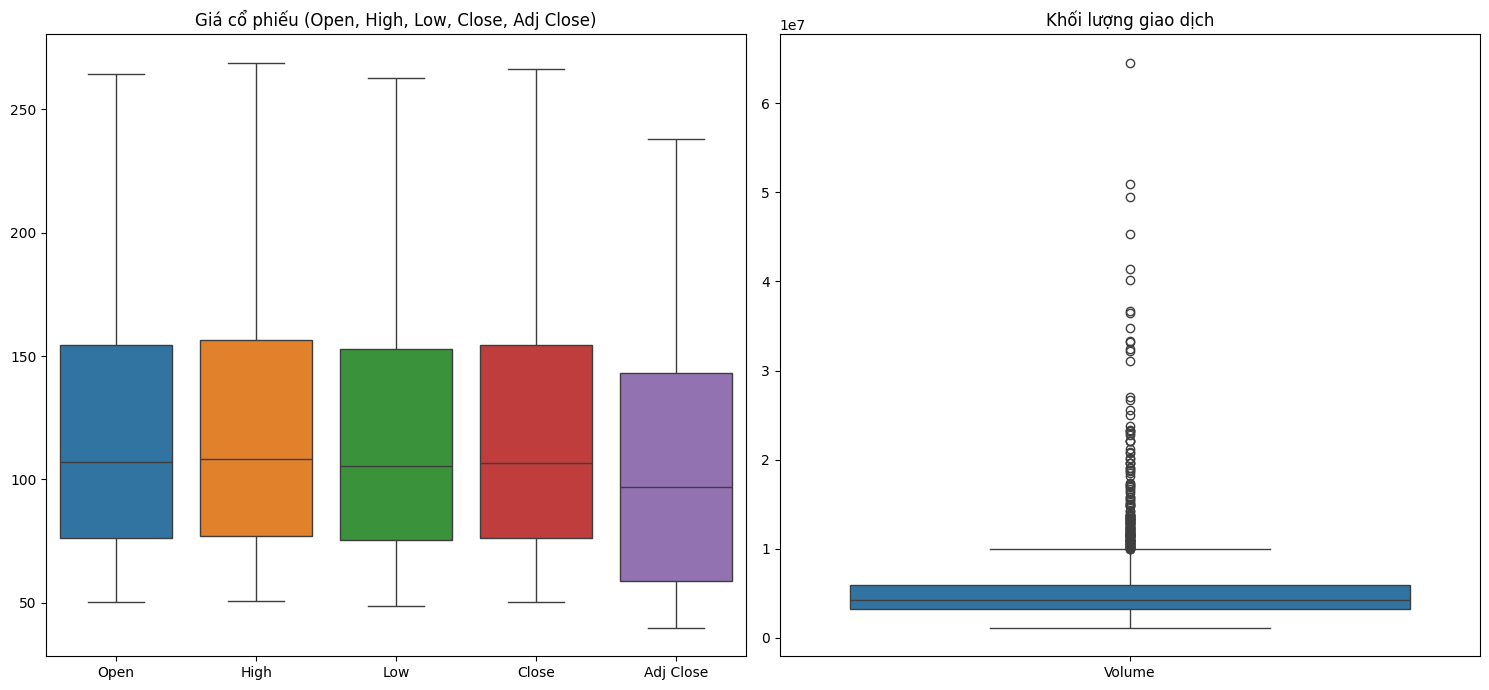


===== Outliers của mã TGT =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          143          2702        5.29


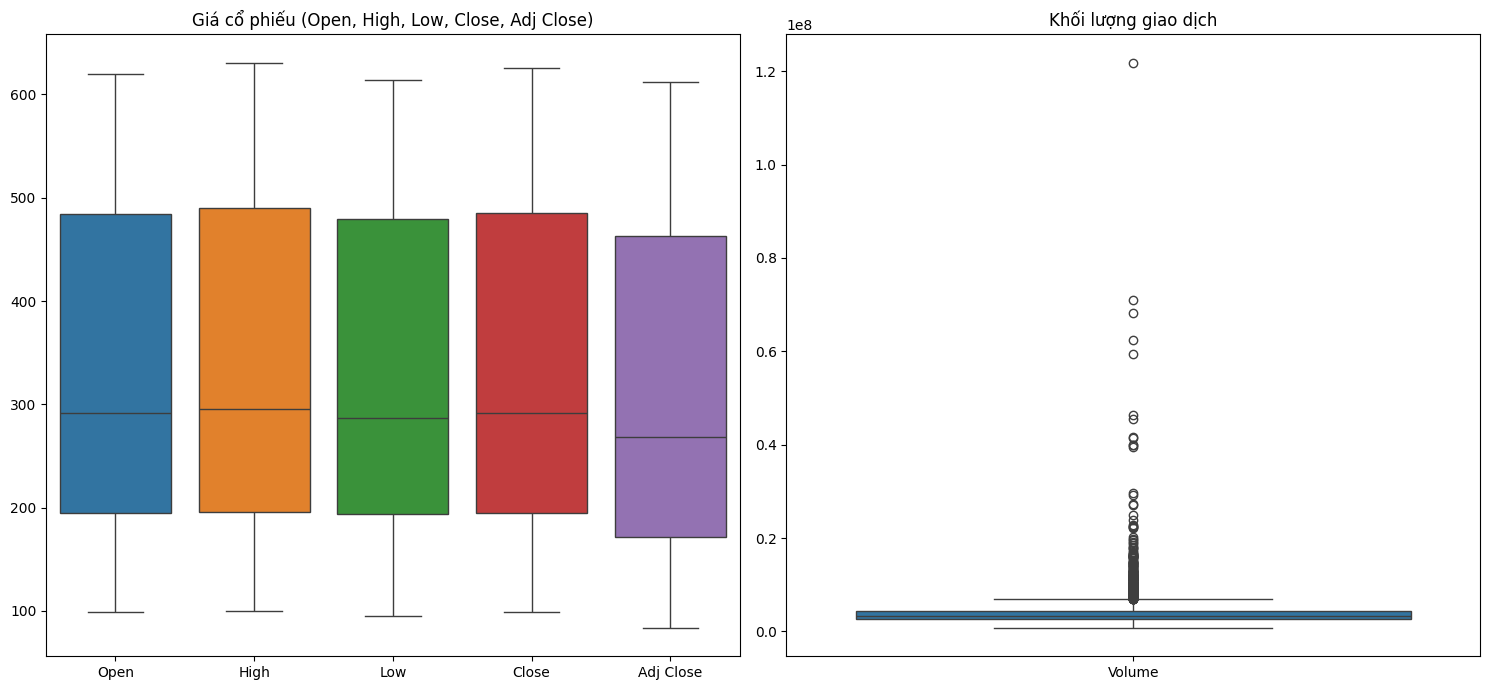


===== Outliers của mã UNH =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702         0.0
High              0          2702         0.0
Low               0          2702         0.0
Close             0          2702         0.0
Adj Close         0          2702         0.0
Volume          246          2702         9.1


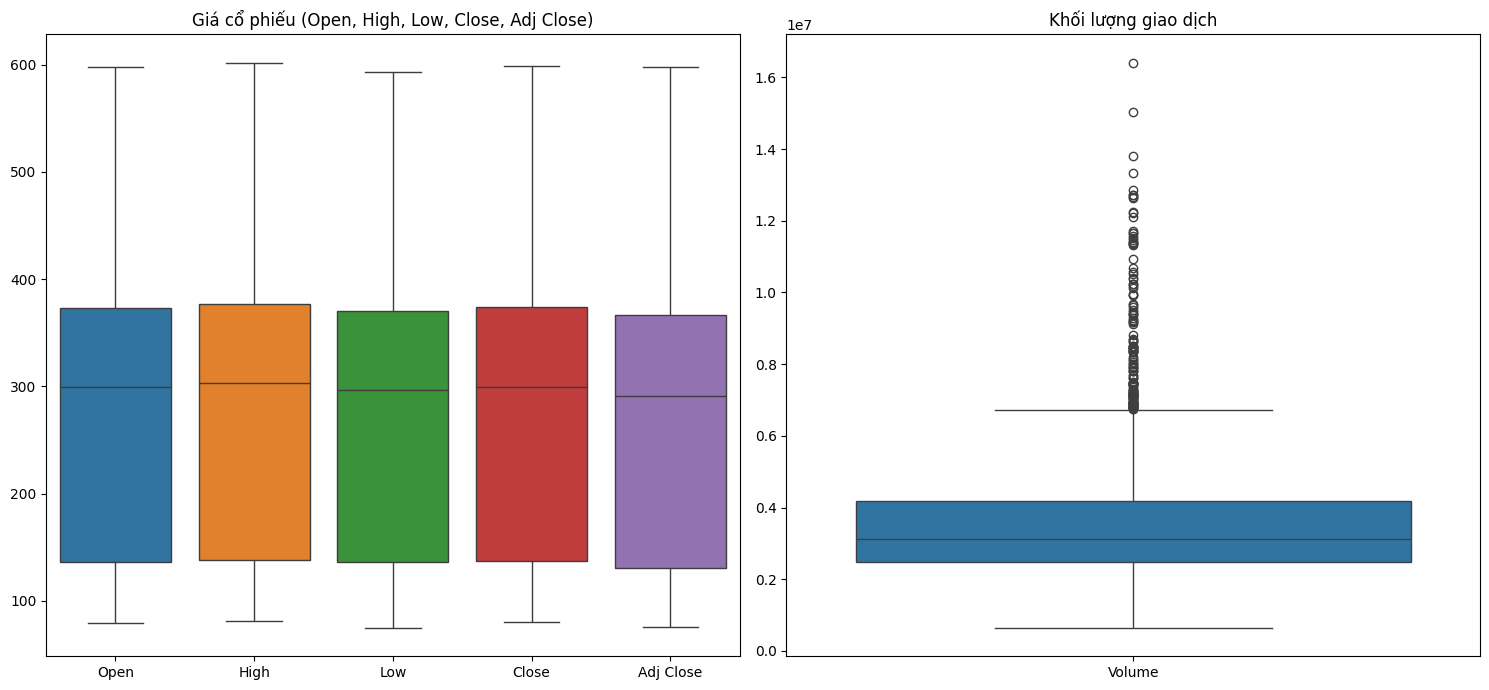


===== Outliers của mã MA =====
           Outliers  Tổng giá trị  % Outliers
Open              0          2702        0.00
High              0          2702        0.00
Low               0          2702        0.00
Close             0          2702        0.00
Adj Close         0          2702        0.00
Volume          140          2702        5.18


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

cols = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]

# Sử dụng vòng lặp for để vẽ biểu đồ cho từng nhóm cột
for ticker, df in dataframes.items():
      if ticker == 'Summary': continue

      # Tạo boxplot cho dữ liệu đã được làm sạch
      fig, axes = plt.subplots(1, 2, figsize=(15, 7))

      # Boxplot cho các biến 'Open', 'High', 'Low', 'Close', 'Adj Close'
      sns.boxplot(data=df[['Open', 'High', 'Low', 'Close', 'Adj Close']], ax=axes[0])
      axes[0].set_title("Giá cổ phiếu (Open, High, Low, Close, Adj Close)")

      # Boxplot cho biến 'Volume'
      sns.boxplot(data=df[['Volume']], ax=axes[1])
      axes[1].set_title("Khối lượng giao dịch")

      plt.tight_layout()
      plt.show()


      print(f"\n===== Outliers của mã {ticker} =====")

      # Chuyển các cột về dạng số
      df[cols] = df[cols].apply(pd.to_numeric, errors='coerce')

      # Tính Q1, Q3 và IQR
      Q1 = df[cols].quantile(0.25)
      Q3 = df[cols].quantile(0.75)
      IQR = Q3 - Q1

      # Tính ngưỡng dưới và trên
      lower_bound = Q1 - 1.5 * IQR
      upper_bound = Q3 + 1.5 * IQR

      # Đếm số giá trị nằm ngoài khoảng [Q1 - 1.5*IQR, Q3 + 1.5*IQR]
      outlier_counts = ((df[cols] < lower_bound) | (df[cols] > upper_bound)).sum()

      # Tổng số giá trị hợp lệ trong mỗi cột
      total_counts = df[cols].count()

      # Tính tỉ lệ %
      outlier_percent = (outlier_counts / total_counts * 100).round(2)

      # Gộp kết quả
      result = pd.DataFrame({
        "Outliers": outlier_counts,
        "Tổng giá trị": total_counts,
        "% Outliers": outlier_percent
    })

      print(result)


**Nhận xét:**
- Nhận thấy gần như mọi biến *Volume* đều lệch phải và tồn tại siêu ngoại lai. Điều này là đúng với thực tế vì thị trường chịu ảnh hưởng mạnh bởi các sự kiện đặc biệt.

- Các hộp cho giá *Open*, *High*, *Low*, *Close*, và *Adj Close* gần như giống hệt nhau. Điều này là bình thường và đúng với thực tế, vì tất cả các mức giá này đều được ghi nhận trong cùng một ngày giao dịch nên phạm vi và phân bố của chúng phải tương đồng.

#### **3.1.1. Xác minh nguồn gốc ngoại lai:**

**VD: Mã AMZN**

In [ ]:
# Xác minh dữ liệu outlier (vì sao Volume của một số mã lại tăng mạnh vào 1 ngày nào đó)
# Ví dụ mã AMZN
df_amz = dataframes['AMZN'].copy()

Q3 = df_amz['Volume'].quantile(0.75)
Q1 = df_amz['Volume'].quantile(0.25)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

# Tìm top 10 outliers của Volume có giá trị cao nhất
outliers_df = df_amz[df_amz['Volume'] > upper_bound]
top_10_outliers = outliers_df.sort_values(by='Volume', ascending=False).head(10)

# In ra top 10 ngày có Volume là Outlier
print(top_10_outliers[["Date", "Volume"]])

# Xác minh nguồn gốc ngoại lai: (VD: một số ngày)
# Ngày 30-01-2015 là ngày Amazon công bố Báo cáo Lợi nhuận Q4 2014 (thời điểm mua sắm lễ hội) thường là một sự kiện lớn.
# Volume ngoại lai cao thường xảy ra vào ngày sau khi công bố lợi nhuận, khi thị trường phản ứng với tin tức đó.

# Ngày 31-01-2020 là phản ứng ban đầu của COVID-19. Ngày này là cao điểm của sự hoảng loạn bán tháo toàn cầu do COVID-19.
# Volume cao cho thấy lượng lớn giao dịch bán tháo, mặc dù thị trường đã cố gắng phục hồi nhẹ vào cuối ngày.

# Các ngày khác tương tự
# => Dữ liệu ngoại lai do các sự kiện thực tế, không phải là lỗi dữ liệu

                     Date     Volume
19    2015-01-30 00:00:00  477122000
140   2015-07-24 00:00:00  438188000
77    2015-04-24 00:00:00  343538000
711   2017-10-27 00:00:00  331300000
1278  2020-01-31 00:00:00  311346000
962   2018-10-26 00:00:00  299276000
270   2016-01-29 00:00:00  293552000
782   2018-02-09 00:00:00  282830000
269   2016-01-28 00:00:00  280304000
951   2018-10-11 00:00:00  278718000


**Các mã còn lại**

In [ ]:
import pandas as pd
import numpy as np

# Danh sách để thu thập TẤT CẢ các ngày ngoại lai từ mọi mã cổ phiếu
all_outlier_dates = []

for ticker, df in dataframes.items():

    # Tạo bản sao để tránh thay đổi DataFrame gốc
    df_ticker = df.copy()

    df_ticker['Volume'] = pd.to_numeric(df_ticker['Volume'], errors='coerce')
    df_ticker.dropna(subset=['Volume'], inplace=True)
    # 1. Tính Ngưỡng Outlier (IQR) trên cột 'Volume'
    Q3 = df_ticker['Volume'].quantile(0.75)
    Q1 = df_ticker['Volume'].quantile(0.25)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR

    # 2. Lọc Top 5 outliers
    outliers_df = df_ticker[df_ticker['Volume'] > upper_bound]
    top_5_outliers = outliers_df.sort_values(by='Volume', ascending=False).head(5)

    # 3. Thu thập Ngày (Date)
    if not top_5_outliers.empty:
        # Chuyển Index (Date) thành cột và thêm vào danh sách chung
        dates_to_collect = top_5_outliers.reset_index()['Date']
        all_outlier_dates.append(dates_to_collect)

# Tính tần số các ngày xuất hiện
if all_outlier_dates:
    # 4. Ghép tất cả các Series ngày lại thành một Series duy nhất
    combined_dates = pd.concat(all_outlier_dates)

    # 5. Tính Tần số (Frequency)
    frequency_series = combined_dates.value_counts()

    # Tạo DataFrame kết quả và in ra
    frequency_df = frequency_series.head(10).reset_index()
    frequency_df.columns = ['Date', 'Frequency (Số mã)']

    print("\n" + "="*50)
    print("BẢNG TẦN SỐ NGÀY OUTLIER CHUNG (TOP 10)")
    print("="*50)
    print(frequency_df.to_markdown(index=False))
else:
    print("\nKhông tìm thấy đủ dữ liệu outlier để tính tần số.")


BẢNG TẦN SỐ NGÀY OUTLIER CHUNG (TOP 10)
| Date                |   Frequency (Số mã) |
|:--------------------|--------------------:|
| 2024-03-15 00:00:00 |                   4 |
| 2021-03-19 00:00:00 |                   4 |
| 2016-11-10 00:00:00 |                   3 |
| 2015-04-24 00:00:00 |                   3 |
| 2025-03-21 00:00:00 |                   3 |
| 2020-03-09 00:00:00 |                   3 |
| 2020-11-09 00:00:00 |                   3 |
| 2017-06-16 00:00:00 |                   3 |
| 2025-07-17 00:00:00 |                   2 |
| 2015-04-17 00:00:00 |                   2 |


Một vài ngày có tần số xuất hiện oulier cao:

**Ngày 15-03-2024:** là ngày Thứ Sáu thứ ba của tháng 3, và là một trong bốn ngày Triple/Quadruple Witching của năm. Triple Witching là hiện tượng xảy ra khi ba loại hợp đồng phái sinh (derivatives) quan trọng hết hạn cùng một lúc vào cùng một ngày:

- Hợp đồng tương lai chỉ số chứng khoán (Stock Index Futures).

- Quyền chọn chỉ số chứng khoán (Stock Index Options).

- Quyền chọn cổ phiếu đơn lẻ (Stock Options).

**Ngày 09-03-2020:** một trong những ngày quan trọng nhất của đợt sụp đổ thị trường chứng khoán liên quan đến đại dịch COVID-19, được mệnh danh là "Black Monday I".
Thị trường bị tấn công bởi hai yếu tố tiêu cực cùng một lúc, gây ra Volume hoảng loạn:

- Đại dịch COVID-19: Các thị trường tiếp tục phản ứng với tin tức về virus COVID-19 và tác động kinh tế toàn cầu tiềm ẩn của nó, dẫn đến bán tháo hàng loạt.

- Cuộc chiến giá Dầu: Giá dầu thô (Crude Oil futures) đã có ngày giảm tồi tệ thứ hai trong lịch sử, giảm 24.60%. Sự sụt giảm của dầu mỏ đã kéo theo sự sụp đổ của lĩnh vực Năng lượng, vốn đã giảm 20.14%.

Những sự kiện này tạo ra sự hoảng loạn bán tháo (panic selling) trên toàn thị trường, lý giải tại sao ngày 09/03/2020 lại xuất hiện trong danh sách các ngày Volume ngoại lai của nhiều mã cổ phiếu khác nhau.

=> Các ngày có dữ liệu ngoại lai đều là ngày có sự kiện thực tế chứ không phải lỗi dữ liệu.

### **3.2. Xử lý ngoại lai**


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle

def winsorize(df, n=5):
    df_res = df.copy()
    for column in df_res.columns:
        if np.issubdtype(df_res[column].dtype, np.number):
            median = df_res[column].quantile(0.5)
            new_median = ((df_res[column] - median).abs()).quantile(0.50)
            max_range = median + n * new_median
            min_range = median - n * new_median
            df_res[column] = np.clip(df_res[column], min_range, max_range)
    return df_res

def standardize(df):
    numeric_cols = df.select_dtypes(include=np.number).columns
    if numeric_cols.empty:
        raise ValueError("No numeric columns found for standardization")

    scaler = StandardScaler()
    df[numeric_cols] = scaler.fit_transform(df[numeric_cols])
    return df

def preprocess_stock_data(df):
    # Kiểm tra xem dataframe có chứa cột số
    numeric_cols = df.select_dtypes(include=np.number).columns
    if numeric_cols.empty:
        raise ValueError("DataFrame contains no numeric columns to process")

    # Winsorize (limit outliers)
    df_factor = winsorize(df, n=5)

    # Standardize (Z-Score)
    df_factor = standardize(df_factor)

    return df_factor

# --- VÒNG LẶP XỬ LÝ CHÍNH ---
for ticker, df in dataframes.items():
    try:
        df_clean = preprocess_stock_data(df)
        dataframes[ticker] = df_clean
    except ValueError as e:
        print(f"Error processing {ticker}: {e}")

/usr/local/lib/python3.12/dist-packages/sklearn/utils/extmath.py:1101: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/usr/local/lib/python3.12/dist-packages/sklearn/utils/extmath.py:1106: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/usr/local/lib/python3.12/dist-packages/sklearn/utils/extmath.py:1126: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


## **4. Outliers in Trading Signal Returns**

### **4.1. Đọc file csv đã tạo ở lab 2,3 có kèm các indicator như SMA,Bollinger Bands**

In [ ]:
import pandas as pd
import pickle

with open('df_copy.pkl', 'rb') as f:
    df_signal = pickle.load(f)

for ticker, df in df_signal.items():
  df['Closelog'] = np.log(df.Close)

# In thử kiểm tra
print(df_signal['AAPL'].head())

                 Open       High        Low      Close  Adj Close     Volume  \
Date                                                                           
2015-01-02  27.847500  27.860001  26.837500  27.332500  24.261049  212818400   
2015-01-05  27.072500  27.162500  26.352501  26.562500  23.577578  257142000   
2015-01-06  26.635000  26.857500  26.157499  26.565001  23.579794  263188400   
2015-01-07  26.799999  27.049999  26.674999  26.937500  23.910429  160423600   
2015-01-08  27.307501  28.037500  27.174999  27.972500  24.829130  237458000   

            SMA_20  SMA_50  STD_20  STD_50  UpperBand_20  LowerBand_20  \
Date                                                                     
2015-01-02     NaN     NaN     NaN     NaN           NaN           NaN   
2015-01-05     NaN     NaN     NaN     NaN           NaN           NaN   
2015-01-06     NaN     NaN     NaN     NaN           NaN           NaN   
2015-01-07     NaN     NaN     NaN     NaN           NaN           Na

In [ ]:
if 'Summary' in df_signal:
    del df_signal['Summary']

for ticker, df in df_signal.items():
  df['SMA_Ratio'] = df['SMA_20'] / df['SMA_50'] - 1
  df['Volatility_Ratio'] = df['STD_20'] / df['STD_50'] - 1

print(df_signal['AAPL'].head())

                 Open       High        Low      Close  Adj Close     Volume  \
Date                                                                           
2015-01-02  27.847500  27.860001  26.837500  27.332500  24.261049  212818400   
2015-01-05  27.072500  27.162500  26.352501  26.562500  23.577578  257142000   
2015-01-06  26.635000  26.857500  26.157499  26.565001  23.579794  263188400   
2015-01-07  26.799999  27.049999  26.674999  26.937500  23.910429  160423600   
2015-01-08  27.307501  28.037500  27.174999  27.972500  24.829130  237458000   

            SMA_20  SMA_50  STD_20  STD_50  UpperBand_20  LowerBand_20  \
Date                                                                     
2015-01-02     NaN     NaN     NaN     NaN           NaN           NaN   
2015-01-05     NaN     NaN     NaN     NaN           NaN           NaN   
2015-01-06     NaN     NaN     NaN     NaN           NaN           NaN   
2015-01-07     NaN     NaN     NaN     NaN           NaN           Na

### **4.2. Vẽ QQ plot để kiểm tra sự phân phối của lợi suất (log return) được tạo ra từ trading strategedy để tìm ra các vấn đề về dữ liệu hoặc mô hình.**

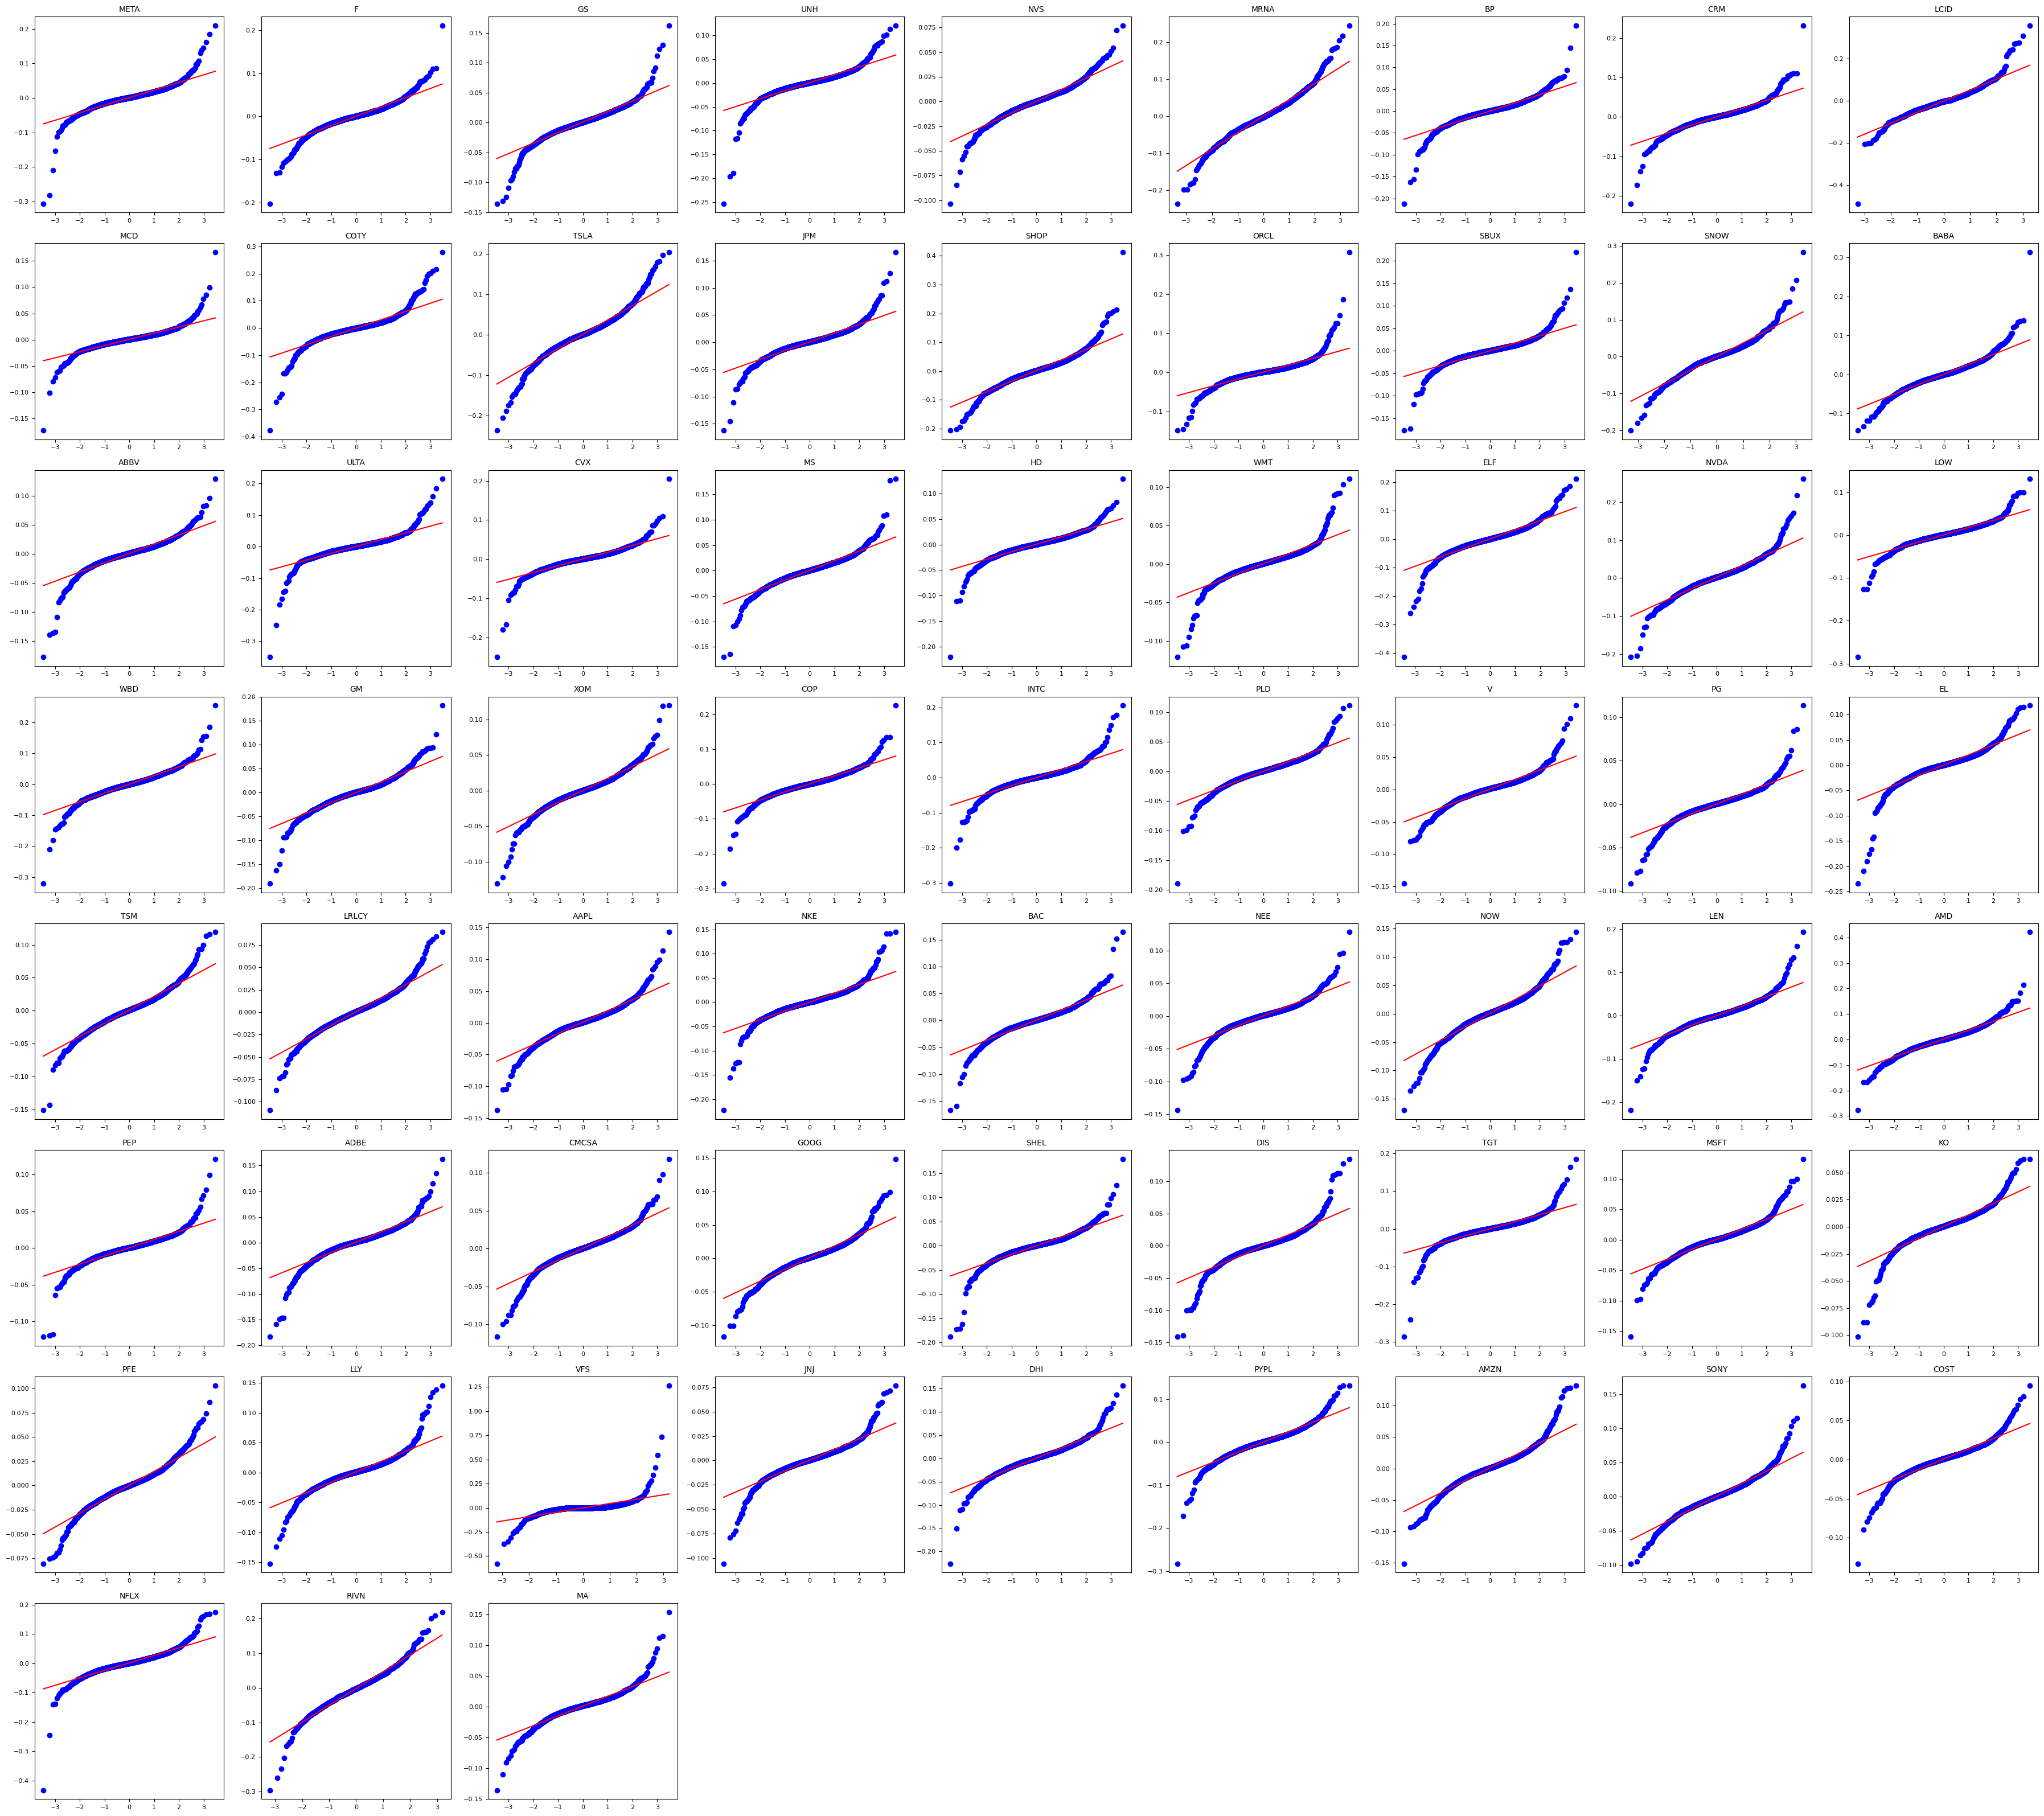

Hình ảnh tổng hợp của 66 QQ Plots đã được lưu thành: all_12_stocks_qq_plots.png


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import math

def plot_all_qq_subplots(dataframes, output_file='all_stocks_qq_plots.png'):
    """
    Tạo một file PNG duy nhất chứa QQ Plot của Log Returns cho TẤT CẢ mã cổ phiếu.

    Args:
        dataframes (dict): Dictionary chứa các DataFrame cổ phiếu (df_signal của bạn).
        output_file (str): Tên file PNG đầu ra.
    """

    tickers = [t for t in dataframes.keys() if t != 'Summary']
    num_plots = len(tickers)

    if num_plots == 0:
        print("Lỗi: Dictionary dataframes trống.")
        return

    # 1. Tính toán kích thước lưới (grid size)
    # Tìm số cột và số hàng xấp xỉ hình vuông (ví dụ: 60 plots -> 7x9 = 63)
    cols = math.ceil(math.sqrt(num_plots))
    rows = math.ceil(num_plots / cols)

    # 2. Tạo Figure và Subplots
    # Điều chỉnh figsize lớn để các biểu đồ con có thể đọc được
    fig, axs = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))

    # fig.suptitle('QQ Plots of All Stock Log Returns', fontsize=16) # Có thể thêm tiêu đề chung

    # Đảm bảo axs là mảng 2D ngay cả khi chỉ có 1 hàng/cột
    axs = axs.flatten() if num_plots > 1 else np.array([axs])

    # 3. Vòng lặp để vẽ từng QQ Plot
    for i, ticker in enumerate(tickers):
        ax = axs[i]
        df = dataframes[ticker].copy()

        # Tính toán Log Returns (nếu chưa có)
        if 'Log_Returns' not in df.columns and 'Adj Close' in df.columns:
            df['Log_Returns'] = np.log(df['Adj Close'] / df['Adj Close'].shift(1))

        data = df['Log_Returns'].dropna()

        if data.empty:
            ax.text(0.5, 0.5, f'{ticker}: Data Empty', transform=ax.transAxes, ha='center')
            ax.set_title(ticker)
        else:
            # stats.probplot: Vẽ QQ Plot trực tiếp lên trục ax
            stats.probplot(data, dist="norm", plot=ax)
            ax.set_title(f'{ticker}', fontsize=10)
            ax.tick_params(axis='both', which='major', labelsize=8)
            ax.set_xlabel('') # Loại bỏ nhãn trục X để tiết kiệm không gian
            ax.set_ylabel('') # Loại bỏ nhãn trục Y

    # 4. Ẩn các Subplots không sử dụng (nếu số lượng < rows * cols)
    for i in range(num_plots, rows * cols):
        fig.delaxes(axs[i])

    # 5. Lưu Figure cuối cùng
    plt.tight_layout() # Tối ưu hóa khoảng cách giữa các subplot
    plt.savefig(output_file)
    plt.show()
    plt.close(fig)

    print(f"Hình ảnh tổng hợp của {num_plots} QQ Plots đã được lưu thành: {output_file}")

# Chạy hàm bằng df_signal
plot_all_qq_subplots(df_signal, output_file='all_12_stocks_qq_plots.png')

**Nhận xét:**

**1. Khu vực Trung tâm (Đường Thẳng)**
- Dấu hiệu: Phần lớn các điểm dữ liệu ở trung tâm (gần trục 0) nằm tương đối gần đường thẳng.
- Ý nghĩa: Điều này cho thấy lợi suất gần mức trung bình tuân theo phân phối chuẩn.

**2. Khu vực Hai Đầu**
- Dấu hiệu: Các điểm dữ liệu ở hai đầu (thái cực trên và thái cực dưới) lệch ra xa đường thẳng một cách rõ rệt.
- Ý nghĩa: Biểu đồ này chỉ ra rằng lợi suất có **Đuôi dày (Fat Tails)**.
**Đuôi dày** có nghĩa là tần suất của các sự kiện cực đoan (lợi nhuận hoặc thua lỗ rất lớn) trong dữ liệu thực tế cao hơn đáng kể so với những gì mô hình phân phối chuẩn dự đoán. Trong **tài chính,** điều này xác nhận rằng dữ liệu có tính ngoại lai cao, và rủi ro thua lỗ lớn (hoặc cơ hội lợi nhuận lớn) cao hơn so với tính toán dựa trên mô hình Gaussian.

**3. Độ Lệch (Skewness)**
- Dấu hiệu: Nếu đường cong lệch về một phía (cong lên hoặc cong xuống), điều đó biểu thị độ lệch (Skewness).
- Phân tích (Đối với dữ liệu cổ phiếu): Lợi suất cổ phiếu thường có độ lệch âm (Left Tail), nghĩa là khả năng xảy ra thua lỗ lớn hơn so với dự đoán của phân phối chuẩn. Còn lệch dương nghĩa là khả năng xảy ra thua lỗ thấp hơn so với dự đoán của phân phối chuẩn.
=> Cần được xử lý các ngoại lai trước khi áp dụng các mô hình hồi quy tiêu chuẩn.

**Các mã có xu hướng lệch âm có khả năng thua lỗ lớn:** F, MCD, UNH, KO,...

**Các mã có xu hướng lệch dương hoặc đối xứng tốt có khả năng thua lỗ thấp hơn:** BABA (lệch dương rõ), JNJ (đối xứng), INTC (đối xứng), MSFT (tương đối đối xứng), NVDA (đối xứng khá tốt), ...


### **4.3. Handling Outliers in Signal Returns**


**Nguyên nhân** các outlier không phải là do lỗi dữ liệu mà là do các sự kiện thực tế nên cần xử lý như sau:
- Check for patterns, Consider excluding: Kiểm tra các cổ phiếu giao dịch thưa thớt (thinly traded small caps) hoặc các ngành có kết quả nhị phân (binary outcomes), và cân nhắc loại trừ chúng khỏi vũ trụ giao dịch.
- Market event considerations: Xác định xem các biến động lớn có trùng với công bố lợi nhuận hoặc tin tức chính sách hay không. Nếu các chiến lược paused trước các sự kiện lớn, có thể loại bỏ các điểm dữ liệu đó. Nếu không, cần thiết kế biện pháp kiểm soát rủi ro.

Kiểm tra các cổ phiếu giao dịch thưa thớt **(thinly traded small caps)**

In [ ]:
# Kiểm tra thinly traded small caps: Mục tiêu là lọc ra những cổ phiếu có thanh khoản kém,
# vốn rất nhạy cảm với các biến động giá cực đoan.

# Xác định Ngưỡng Thanh khoản Tối thiểu (Min Liquidity Threshold)
# Ví dụ: Loại bỏ các mã có Turnover trung bình < 500,000 USD/ngày
MIN_TURNOVER_THRESHOLD = 10000000           # (20 triệu USD)
tickers_to_exclude = set()
all_tickers = list(df_signal.keys())

for ticker in all_tickers:
    df = df_signal[ticker]

    # Tính Turnover Trung bình Hàng ngày
    avg_daily_turnover = df['Turnover'].mean()

    if avg_daily_turnover < MIN_TURNOVER_THRESHOLD:
        tickers_to_exclude.add(ticker)

# In ra các mã sẽ bị loại trừ
print(f"Các mã bị loại trừ do Turnover thấp: {tickers_to_exclude}")

Các mã bị loại trừ do Turnover thấp: {'LRLCY'}


Loại trừ khỏi Vũ trụ Giao dịch **(Exclusion)**

In [ ]:
# Tạo dictionary mới chỉ chứa các mã cổ phiếu đạt chuẩn thanh khoản
trading_universe = {
    ticker: df for ticker, df in df_signal.items()
    if ticker not in tickers_to_exclude
}
print(f"Số lượng mã cổ phiếu sau khi lọc: {len(trading_universe)}")

Số lượng mã cổ phiếu sau khi lọc: 66


Xử lý Sự kiện Thị trường **(Market Events)**

**Phương pháp Pausing Strategy (Loại bỏ Dữ liệu/Ngày)**

Nếu chiến lược có thể được tạm dừng (paused) trước các sự kiện lớn và hoạt động tốt hơn khi không có biến động đó, khi đó có thể loại bỏ các ngày đó khỏi quá trình backtest hoặc tính toán tín hiệu.



In [ ]:
# Ví dụ: Lọc bỏ tất cả các ngày Triple/Quadruple Witching (Thứ Sáu thứ 3 của tháng 3, 6, 9, 12)
# Đây là phương pháp hiệu quả khi bạn muốn xây dựng mô hình cho "điều kiện thị trường bình thường"
def filter_event_days(df):
    # (Logic phức tạp để tạo danh sách các ngày sự kiện)

    # Ví dụ đơn giản: Loại bỏ các ngày có Volume ngoại lai quá cao (Top 0.1%)
    volume_99_9_percentile = df['Volume'].quantile(0.999)

    # Chỉ giữ lại các ngày Volume dưới ngưỡng cực đoan
    df_filtered = df[df['Volume'] <= volume_99_9_percentile]
    return df_filtered

# Ví dụ cho một mã cổ phiếu
df_filtered_amzn = filter_event_days(trading_universe['AMZN'])
print(df_filtered_amzn.head())

               Open     High      Low    Close  Adj Close    Volume  SMA_20  \
Date                                                                          
2015-01-02  15.6290  15.7375  15.3480  15.4260    15.4260  55664000     NaN   
2015-01-05  15.3505  15.4190  15.0425  15.1095    15.1095  55484000     NaN   
2015-01-06  15.1120  15.1500  14.6190  14.7645    14.7645  70380000     NaN   
2015-01-07  14.8750  15.0640  14.7665  14.9210    14.9210  52806000     NaN   
2015-01-08  15.0160  15.1570  14.8055  15.0230    15.0230  61768000     NaN   

            SMA_50  STD_20  STD_50  UpperBand_20  LowerBand_20  UpperBand_50  \
Date                                                                           
2015-01-02     NaN     NaN     NaN           NaN           NaN           NaN   
2015-01-05     NaN     NaN     NaN           NaN           NaN           NaN   
2015-01-06     NaN     NaN     NaN           NaN           NaN           NaN   
2015-01-07     NaN     NaN     NaN           N

**Nếu không thể loại bỏ các ngày đó** (vì nó làm hỏng tính liên tục của chuỗi thời gian) hoặc muốn tận dụng cơ hội của biến động, cần thiết kế các kiểm soát rủi ro để giảm thua lỗ lợi nhuận:

**1/** Position Sizing (Giới hạn Vị thế): Giảm quy mô giao dịch vào những ngày hoặc những tuần dự kiến có biến động cao. Ví dụ: Nếu Volatility tăng gấp đôi, chỉ mua/bán một nửa số lượng cổ phiếu thông thường.

**2/** Stop-Loss Thresholds (Ngưỡng Cắt lỗ): Đặt lệnh cắt lỗ chặt chẽ hơn (ví dụ: 1% thay vì 2%) để giảm thiểu tổn thất trong trường hợp sự kiện gây ra biến động giá cực đoan không mong muốn.

**3/** Robust Design (Thiết kế Mạnh mẽ): Stress-test (kiểm tra áp lực) tín hiệu của bạn dưới cả điều kiện thị trường bình thường và khủng hoảng để đảm bảo chiến lược không bị phá vỡ.

## **5. Regression**

### **5.1. Chia tập train, tập test sau khi đã preprocessing**

In [ ]:
# Tạo dictionary để lưu trữ kết quả chia tập train/test
train_dataframes = {}
test_dataframes = {}

for ticker, df in df_signal.items():
    # 1. Các bước xử lý trong vòng lặp (giữ nguyên)
    df = df.reset_index()
    df['Date'] = pd.to_datetime(df['Date'], errors = 'coerce')
    df.index = pd.PeriodIndex(df.Date, freq='D')
    df = df.sort_index()

    df['timeIndex'] = df['Date'] - df['Date'].min()
    df['timeIndex'] = df['timeIndex'] / np.timedelta64(1, 'D')
    df.dropna(subset=['timeIndex'], inplace=True)
    df['timeIndex'] = df['timeIndex'].round().astype(int)

    # #Chia dữ liệu
    train_size = int(len(df) * 0.8)

    # KHẮC PHỤC LỖI: Lưu trữ vào dictionary
    train_dataframes[ticker] = df.iloc[:train_size].copy()
    test_dataframes[ticker] = df.iloc[train_size:].copy()

# --- # 4. Kiểm tra các cột (Chạy trên dictionary mới) ---
print("\n# 4. Kiểm tra")
for ticker, train_df in train_dataframes.items():
    print(f"Kiểm tra các cột của {ticker} train_df:")
    print(train_df.columns)
    print("~*~")
print()

# --- In 6 dòng đầu của train_df cho mỗi ticker ---
for ticker, train_df in train_dataframes.items():
    print(f"\nKiểm tra 6 dòng đầu của {ticker} train_df:")
    print(train_df.head(6))


# 4. Kiểm tra
Kiểm tra các cột của META train_df:
Index(['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'SMA_20',
       'SMA_50', 'STD_20', 'STD_50', 'UpperBand_20', 'LowerBand_20',
       'UpperBand_50', 'LowerBand_50', 'Log_Returns', 'Turnover',
       'Momentum_120D', 'Closelog', 'SMA_Ratio', 'Volatility_Ratio',
       'timeIndex'],
      dtype='object')
~*~
Kiểm tra các cột của F train_df:
Index(['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'SMA_20',
       'SMA_50', 'STD_20', 'STD_50', 'UpperBand_20', 'LowerBand_20',
       'UpperBand_50', 'LowerBand_50', 'Log_Returns', 'Turnover',
       'Momentum_120D', 'Closelog', 'SMA_Ratio', 'Volatility_Ratio',
       'timeIndex'],
      dtype='object')
~*~
Kiểm tra các cột của GS train_df:
Index(['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'SMA_20',
       'SMA_50', 'STD_20', 'STD_50', 'UpperBand_20', 'LowerBand_20',
       'UpperBand_50', 'LowerBand_50', 'Log_Returns', 'Turnover',
     

### **5.2. Xây dựng mô hình hồi quy tuyến tính**

In [ ]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

for ticker, train_df in train_dataframes.items():

    # BƯỚC 1: XÁC ĐỊNH CÁC CỘT CẦN DÙNG
    # Đảm bảo tất cả các biến đều có giá trị (không phải NaN)
    required_cols = ['Closelog', 'timeIndex', 'SMA_Ratio', 'Volatility_Ratio', 'Momentum_120D']

    # BƯỚC 2: LOẠI BỎ HÀNG CHỨA NaN TRONG CÁC CỘT CẦN DÙNG
    # Chỉ giữ lại các hàng có đầy đủ dữ liệu cho mô hình
    cleaned_train_df = train_df.dropna(subset=required_cols)

    # BƯỚC 3: KIỂM TRA DỮ LIỆU CÓ ĐỦ KHÔNG
    if len(cleaned_train_df) < 5: # Ví dụ: cần ít nhất 5 điểm dữ liệu để hồi quy với 4 biến
        print(f"--- BỎ QUA Ticker ('{ticker}') ---")
        print(f"Không đủ dữ liệu sạch: chỉ có {len(cleaned_train_df)} hàng.")
        print("|\n")
        continue # Bỏ qua ticker này và chuyển sang ticker tiếp theo

    # BƯỚC 4: Xây dựng mô hình hồi quy tuyến tính (Sử dụng DataFrame đã được làm sạch)
    model_linear = smf.ols('Closelog ~ timeIndex + SMA_Ratio + Volatility_Ratio + Momentum_120D', data = cleaned_train_df).fit()

    # In tiêu đề và kết quả
    print(f"--- Kết quả OLS cho ticker ('{ticker}') ---")
    print(model_linear.summary())
    print("|\n")

--- Kết quả OLS cho ticker ('META') ---
                            OLS Regression Results                            
Dep. Variable:               Closelog   R-squared:                       0.603
Model:                            OLS   Adj. R-squared:                  0.602
Method:                 Least Squares   F-statistic:                     772.0
Date:                Fri, 12 Dec 2025   Prob (F-statistic):               0.00
Time:                        13:43:46   Log-Likelihood:                 137.00
No. Observations:                2041   AIC:                            -264.0
Df Residuals:                    2036   BIC:                            -235.9
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------


In [ ]:
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

for ticker, train_df in train_dataframes.items():


  # Vì VIF chỉ cần biến độc lập, chúng ta chọn các cột cần thiết:
  X = cleaned_train_df[['timeIndex', 'SMA_Ratio', 'Volatility_Ratio', 'Momentum_120D']]

  # --- 2. Tính toán VIF ---
  # Chạy VIF cho từng cột trong ma trận X
  vif_data = pd.DataFrame()
  vif_data["feature"] = X.columns
  vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                   for i in range(len(X.columns))]

  # --- 3. Hiển thị Kết quả ---
  print(f"--- Kết quả VIF cho ticker ('{ticker}') ---")
  print(vif_data)
  print("|\n")


--- Kết quả VIF cho ticker ('META') ---
            feature       VIF
0         timeIndex  1.774995
1         SMA_Ratio  1.555602
2  Volatility_Ratio  1.962838
3     Momentum_120D  1.855643
|

--- Kết quả VIF cho ticker ('F') ---
            feature       VIF
0         timeIndex  1.774995
1         SMA_Ratio  1.555602
2  Volatility_Ratio  1.962838
3     Momentum_120D  1.855643
|

--- Kết quả VIF cho ticker ('GS') ---
            feature       VIF
0         timeIndex  1.774995
1         SMA_Ratio  1.555602
2  Volatility_Ratio  1.962838
3     Momentum_120D  1.855643
|

--- Kết quả VIF cho ticker ('UNH') ---
            feature       VIF
0         timeIndex  1.774995
1         SMA_Ratio  1.555602
2  Volatility_Ratio  1.962838
3     Momentum_120D  1.855643
|

--- Kết quả VIF cho ticker ('NVS') ---
            feature       VIF
0         timeIndex  1.774995
1         SMA_Ratio  1.555602
2  Volatility_Ratio  1.962838
3     Momentum_120D  1.855643
|

--- Kết quả VIF cho ticker ('MRNA') ---
  

**Nhận xét**
- Xem xét mô hình hồi quy của tất cả các mã, nhận thấy $R^2$ rất cao. Từ đó cho thấy biến timeIndex, SMA_Ratio, Volatility_Ratio, Momentum_10D giải thích được khoảng 85-92% sự biến thiên của *Closelog*.

- Giá trị p của F-statistic **rất nhỏ(~0)** cho thấy mô hình có ý nghĩa thống kê với độ tin cậy 5%.

**Đánh giá cho hệ số $\beta$ của mô hình hồi quy tuyến tính BETA**

- **SMA_Ratio** có hệ số âm, p-value thấp cho thấy có ý nghĩa thống kê. Khẳng định chiến lược theo xu hướng có liên quan tiêu cực đến lợi suất ngày hôm sau

- **Bolatility_Ratio** có hệ số dương, p-value thấp cho thấy có ý nghĩa thống kê. Điều này cho thấy khi Volatility hiện tại tăng cao hơn mức trung bình, lợi suất ngày hôm sau có xu hướng tăng.

- **Momentum_120D** có hệ số dương, p-value thấp có ý nghĩa thống kê cho thấy đà tăng trưởng dài hạn(120 ngày) có liên quan tích cực đến lợi suất ngắn hạn ngày hôm sau.


Mặt khác, ta kết luận được rằng các phần dư của mô hình tự tương quan rất mạnh, vì giá trị là $0.04$ cực kỳ thấp đối với test **Durbin-Watson**

**Kết luận**: Mô hình không phù hợp để dự báo hoặc giải thích giá cổ phiếu để đưa ra quyết định mua bán. Sự tương quan mạnh mẽ trong phần dư chỉ ra rằng các phần dư(lỗi dự báo) của ngày hôm nay có liên quan trực tiếp đến lỗi của ngày hôm trước. Điều này có nghĩa là **giá trị thực tế của ngày hôm trước là yếu tố dự báo quan trọng nhất** mà mô hình OLS đã bỏ qua.

$\to$ Chuyển sang mô hình chuỗi thời gian tiên tiến hơn như *ARIMA* để xử lý hiệu quả tính tự tương quan trong chuỗi giá cổ phiếu
